In [1]:
# GAC-KAN: Guarded Adaptive Compilation for Kolmogorov-Arnold Networks.
# Full inference: GAC-KAN (ours); training: GAC-KAN (compact training).
# SC-KAN-v2 is an internal baseline; fixed backends are component controls.
# Run all cells. CPU measurements use one thread; every result stays inline.
import importlib.util, subprocess, sys
packages = {'numpy':'numpy','pandas':'pandas','scipy':'scipy','sklearn':'scikit-learn',
            'numba':'numba','matplotlib':'matplotlib','threadpoolctl':'threadpoolctl','sympy':'sympy'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
if importlib.util.find_spec('torch') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','torch','--index-url','https://download.pytorch.org/whl/cpu'])
import copy, gc, hashlib, io, json, math, os, pickle, platform, random, tarfile, time, urllib.request, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import torch
from torch import nn
from torch.nn import functional as F
from numba import njit
from scipy.io import arff
from scipy.special import expit
from sklearn.datasets import load_digits,load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score,mean_squared_error,r2_score
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display,Math
get_ipython().run_line_magic('matplotlib','inline')
torch.set_num_threads(1)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass
THREAD_LIMIT = threadpool_limits(limits=1)
pd.set_option('display.max_rows',220);pd.set_option('display.max_columns',36)
plt.rcParams.update({'figure.dpi':150,'font.size':10})
EPS = np.finfo(np.float64).eps
CACHE = Path('kan_v3_cache');CACHE.mkdir(exist_ok=True)
def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
def download(url,name,expected=None):
    path = CACHE/name
    if not path.exists():
        with urllib.request.urlopen(url,timeout=90) as response:
            data = response.read()
        if expected and hashlib.sha256(data).hexdigest() != expected:
            raise ValueError('Source checksum mismatch: '+name)
        path.write_bytes(data)
    if expected and hashlib.sha256(path.read_bytes()).hexdigest() != expected:
        raise ValueError('Cached checksum mismatch: '+name)
    return path

display(pd.DataFrame([dict(Python=platform.python_version(),PyTorch=torch.__version__,NumPy=np.__version__,
    SciPy=scipy.__version__,Numba=__import__('numba').__version__,CPU_threads=torch.get_num_threads(),
    machine=platform.machine(),GPU_measured=False,global_SOTA_proven=False)]))

No event loop hook running.


,Python,PyTorch,NumPy,SciPy,Numba,CPU_threads,machine,GPU_measured,global_SOTA_proven
0,3.12.14,2.8.0+cpu,2.2.6,1.17.0,0.61.2,1,x86_64,False,False


In [2]:
# Pinned, unmodified upstream implementations; MIT (EfficientKAN), Apache-2.0 (FastKAN).
SOURCE_MANIFEST = {'EfficientKAN': {'url': 'https://raw.githubusercontent.com/Blealtan/efficient-kan/7b6ce1c87f18c8bc90c208f6b494042344216b11/src/efficient_kan/kan.py', 'filename': 'efficient_kan_upstream.py', 'sha256': 'c2b984359fe483640fcc2313570bbbd2128eede99bdbf0fa586ec8e0e1a1ecb7', 'commit': '7b6ce1c87f18c8bc90c208f6b494042344216b11'}, 'FastKAN': {'url': 'https://raw.githubusercontent.com/ZiyaoLi/fast-kan/17b65401c252334fffb5e63c9852dd8316d29e69/fastkan/fastkan.py', 'filename': 'fastkan_upstream.py', 'sha256': '3f2080b7baea947ea123be5d009fc4ce4267729e32a5d63ea2eed887ec3f3405', 'commit': '17b65401c252334fffb5e63c9852dd8316d29e69'}}
UPSTREAM={}
for name,source in SOURCE_MANIFEST.items():
    path=download(source['url'],source['filename'],source['sha256'])
    namespace={'__name__':'official_'+name}
    exec(compile(path.read_text(),source['filename'],'exec'),namespace)
    UPSTREAM[name]=namespace
OfficialEfficientKAN=UPSTREAM['EfficientKAN']['KAN']
OfficialEfficientLinear=UPSTREAM['EfficientKAN']['KANLinear']
OfficialFastKAN=UPSTREAM['FastKAN']['FastKAN']
display(pd.DataFrame([dict(method=name,**source) for name,source in SOURCE_MANIFEST.items()]))

,method,url,filename,sha256,commit
0,EfficientKAN,https://raw.githubusercontent.com/Blealtan/eff...,efficient_kan_upstream.py,c2b984359fe483640fcc2313570bbbd2128eede99bdbf0...,7b6ce1c87f18c8bc90c208f6b494042344216b11
1,FastKAN,https://raw.githubusercontent.com/ZiyaoLi/fast...,fastkan_upstream.py,3f2080b7baea947ea123be5d009fc4ce4267729e32a5d6...,17b65401c252334fffb5e63c9852dd8316d29e69


In [3]:
# Internal SC-KAN-v2 baseline; this is separate from GAC-KAN.
# Shared spline residuals + learned feature warps + direct linear shortcut.
def compact_cubic_basis(u, grid):
    v = (u + 1) * (grid / 2)
    span = v.floor().long().clamp(0, grid - 1)
    t = v - span.to(v.dtype)
    weights = torch.stack(((1-t).pow(3), 3*t.pow(3)-6*t.square()+4,
                           -3*t.pow(3)+3*t.square()+3*t+1, t.pow(3)), -1) / 6
    basis = torch.zeros(*u.shape, grid + 3, dtype=u.dtype, device=u.device)
    ids = span.unsqueeze(-1) + torch.arange(4, device=u.device)
    return basis.scatter_add(-1, ids, weights)

class SharedSplineLayer(nn.Module):
    def __init__(self, n_in, n_out, grid=8, rank=8, warp=True,
                 raw_base=True, base=True, spline=True, scale=.5, linear_base=False, spline_engine='compact'):
        super().__init__()
        self.n_in, self.n_out, self.grid = n_in, n_out, grid
        self.rank = n_out if rank == 0 else min(rank, n_out)
        self.fullrank = rank == 0
        self.linear_base = linear_base
        self.spline_engine = spline_engine
        self.raw_base, self.use_base, self.use_spline = raw_base, base, spline
        active_warp = warp and (spline or not raw_base)
        self.log_scale = nn.Parameter(torch.full((n_in,), math.log(scale)), requires_grad=active_warp)
        self.shift = nn.Parameter(torch.zeros(n_in), requires_grad=active_warp)
        self.coeff = nn.Parameter(torch.randn(self.rank, n_in, grid + 3) * (.04 / math.sqrt(n_in)), requires_grad=spline)
        if self.fullrank:
            self.register_buffer('mix', torch.eye(n_out))
        else:
            self.mix = nn.Parameter(torch.empty(n_out, self.rank), requires_grad=spline)
            nn.init.orthogonal_(self.mix)
        self.base = nn.Parameter(torch.empty(n_out, n_in), requires_grad=base)
        nn.init.kaiming_uniform_(self.base, a=math.sqrt(5))
        self.bias = nn.Parameter(torch.zeros(n_out))

    def effective_coefficients(self):
        return self.coeff - self.coeff.mean(-1, keepdim=True)

    def forward(self, x):
        u = (torch.tanh(x * self.log_scale.clamp(-3, 1).exp() + self.shift)
             if self.use_spline or not self.raw_base else None)
        out = self.bias.expand(len(x), -1)
        if self.use_base:
            features = x if self.raw_base else u
            out = out + F.linear(features if self.linear_base else F.silu(features), self.base)
        if self.use_spline:
            basis_fn = compact_cubic_basis if self.spline_engine == 'compact' else spline_basis
            basis = basis_fn(u, self.grid).flatten(1)
            latent = F.linear(basis, self.effective_coefficients().flatten(1))
            out = out + (latent if self.fullrank else F.linear(latent, self.mix))
        return out

    def curvature(self):
        c = self.effective_coefficients()
        second = c[..., 2:] - 2 * c[..., 1:-1] + c[..., :-2]
        # Scale-invariant under reciprocal rescaling of the two factors.
        return (second.abs().mean((1, 2)) * self.mix.abs().sum(0)).mean()

class SharedResidualKAN(nn.Module):
    def __init__(self, n_in, n_out, hidden=128, grid=8, rank=8, depth=2,
                 warp=True, raw_base=True, shortcut=True, base=True, spline=True, scale=.5,
                 linear_input=True, spline_engine='compact', residual_mode='all'):
        super().__init__()
        self.method = 'SC-KAN'
        self.n_in, self.n_out, self.hidden, self.grid = n_in, n_out, hidden, grid
        sizes = [n_in] + [hidden] * (depth - 1) + [n_out]
        self.layers = nn.ModuleList([
            SharedSplineLayer(a, b, grid, rank, warp, raw_base, base,
                              spline and (residual_mode == 'all' or (residual_mode == 'first' and i == 0)
                                          or (residual_mode == 'last' and i == depth - 1)),
                              scale, linear_input and i == 0, spline_engine)
            for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:]))
        ])
        self.shortcut = nn.Linear(n_in, n_out, bias=False) if shortcut else None
        if shortcut:
            nn.init.zeros_(self.shortcut.weight)

    def forward(self, x):
        z = x
        for layer in self.layers:
            z = layer(z)
        if self.shortcut is not None:
            z = z + self.shortcut(x)
        return z

    def curvature(self):
        return sum(layer.curvature() for layer in self.layers if layer.use_spline)

In [4]:
# Official EfficientKAN/FastKAN classes are loaded from pinned upstream source above.
class MLP(nn.Module):
    def __init__(self,n_in,n_out,hidden):
        super().__init__();self.layers=nn.Sequential(nn.Linear(n_in,hidden),nn.SiLU(),nn.Linear(hidden,n_out))
    def forward(self,x):
        return self.layers(x)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def instantiate(method,data,config):
    n,m,h,g=data['n_in'],data['n_out'],config['hidden'],config['grid']
    if method == 'MLP':return MLP(n,m,h)
    if method == 'EfficientKAN':return OfficialEfficientKAN([n,h,m],grid_size=g,grid_range=[-3,3])
    if method == 'FastKAN':return OfficialFastKAN([n,h,m],num_grids=g)
    if method == 'SC-KAN-v2':return SharedResidualKAN(n,m,hidden=h,grid=g,rank=8,linear_input=True)
    raise ValueError(method)

def match_config(method,data,budget,grid):
    low,high=4,1024
    while low<high:
        mid=(low+high+1)//2
        if count_parameters(instantiate(method,data,dict(hidden=mid,grid=grid)))<=budget:low=mid
        else:high=mid-1
    return dict(hidden=low,grid=grid)

def train_model(data,method,config,seed,epochs,lr):
    seed_all(seed);model=instantiate(method,data,config)
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=.001)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,epochs,eta_min=.02*lr)
    ema=copy.deepcopy(model).eval();best=np.inf;best_accuracy=-1.;state=None;records=[];start=time.perf_counter()
    x,y=map(torch.from_numpy,data['train']);xv,yv=map(torch.from_numpy,data['val'])
    classification=data['task']=='classification';batch=256
    for epoch in range(epochs):
        model.train();total=0.
        for ids in torch.randperm(len(y)).split(batch):
            optimizer.zero_grad(set_to_none=True);z=model(x[ids])
            loss=(F.cross_entropy(z,y[ids],label_smoothing=.01) if classification else F.mse_loss(z,y[ids]))
            if method=='SC-KAN-v2':loss=loss+.0005*model.curvature()
            if not torch.isfinite(loss):raise FloatingPointError('Nonfinite training loss')
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);optimizer.step()
            with torch.no_grad():
                for a,b in zip(ema.parameters(),model.parameters()):a.lerp_(b,.03)
                for a,b in zip(ema.buffers(),model.buffers()):a.copy_(b)
            total+=float(loss.detach())*len(ids)
        scheduler.step();model.eval();score=np.inf;acc=np.nan
        for candidate in (model,ema):
            with torch.inference_mode():
                z=candidate(xv)
                value=float(F.cross_entropy(z,yv) if classification else F.mse_loss(z,yv))
                accuracy=float((z.argmax(1)==yv).double().mean()) if classification else np.nan
            better=((accuracy>best_accuracy+1e-12 or (abs(accuracy-best_accuracy)<=1e-12 and value<best))
                    if classification else value<best)
            if better:
                best,best_accuracy=value,accuracy;state=copy.deepcopy(candidate.state_dict())
            if value<score:score,acc=value,accuracy
        records.append((epoch+1,total/len(y),score,acc))
    model.load_state_dict(state);model.eval()
    return model,pd.DataFrame(records,columns=['epoch','train_loss','val_loss','val_accuracy']),dict(
        val_loss=best,val_accuracy=best_accuracy,train_s=time.perf_counter()-start,parameters=count_parameters(model))

In [5]:
DATA_SOURCES = {'Banknote': ('https://archive.ics.uci.edu/static/public/267/banknote+authentication.zip', 'banknote.zip', '1e2acd9a2085fadf3d8145c12d3d22af853320d52294a6590c2eaf75fdc05227'), 'DryBean': ('https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip', 'dry_bean.zip', '0a64eff5be87f48c3dbbfc0a12a56c5d5b5167ef8e61cd45d69b3e7c7130c06f'), 'Letter': ('https://archive.ics.uci.edu/static/public/59/letter+recognition.zip', 'letter.zip', '3b5f07a334697b6cace4fbae22940393a18fee596e73f68d97ce5973d52dc60f'), 'WineQuality': ('https://archive.ics.uci.edu/static/public/186/wine+quality.zip', 'wine_quality.zip', '3ed56667f4b828242bd732d7d1dd7f2861e54432239d7fa63877014cbb0304d4'), 'California': ('https://ndownloader.figshare.com/files/5976036', 'california_housing.tgz', 'aaa5c9a6afe2225cc2aed2723682ae403280c4a3695a2ddda4ffb5d8215ea681')}
# Public data are downloaded once and verified against fixed SHA256 hashes.
def load_public(name):
    if name=='Digits':
        d=load_digits();return d.data.astype(float),d.target,'classification'
    if name=='BreastCancer':
        d=load_breast_cancer();return d.data.astype(float),d.target,'classification'
    if name=='Diabetes':
        from sklearn.datasets import load_diabetes
        d=load_diabetes();return d.data.astype(float),d.target.astype(float),'regression'
    url,filename,sha=DATA_SOURCES[name];path=download(url,filename,sha)
    if name=='Banknote':
        with zipfile.ZipFile(path) as z:a=np.loadtxt(io.BytesIO(z.read('data_banknote_authentication.txt')),delimiter=',')
        return a[:,:-1],a[:,-1].astype(int),'classification'
    if name=='DryBean':
        with zipfile.ZipFile(path) as z:d,_=arff.loadarff(io.StringIO(z.read('DryBeanDataset/Dry_Bean_Dataset.arff').decode()))
        f=pd.DataFrame(d);return f.iloc[:,:-1].to_numpy(float),LabelEncoder().fit_transform(f.iloc[:,-1]),'classification'
    if name=='Letter':
        with zipfile.ZipFile(path) as z:f=pd.read_csv(io.BytesIO(z.read('letter-recognition.data')),header=None)
        return f.iloc[:,1:].to_numpy(float),LabelEncoder().fit_transform(f.iloc[:,0]),'classification'
    if name=='WineQuality':
        with zipfile.ZipFile(path) as z:
            red=pd.read_csv(io.BytesIO(z.read('winequality-red.csv')),sep=';');red['red']=1
            white=pd.read_csv(io.BytesIO(z.read('winequality-white.csv')),sep=';');white['red']=0
        f=pd.concat([red,white],ignore_index=True)
        return f.drop(columns='quality').to_numpy(float),f.quality.to_numpy(float),'regression'
    if name=='California':
        with tarfile.open(path) as t:a=np.loadtxt(t.extractfile('CaliforniaHousing/cal_housing.data'),delimiter=',')
        x=np.c_[a[:,7],a[:,2],a[:,3]/a[:,6],a[:,4]/a[:,6],a[:,5],a[:,5]/a[:,6],a[:,1],a[:,0]]
        return x,a[:,8]/100000.,'regression'
    raise ValueError(name)

def split_public(name,split_seed):
    raw,y,task=load_public(name)
    _,first,groups=np.unique(raw,axis=0,return_index=True,return_inverse=True)
    group_ids=np.arange(len(first));labels=y[first]
    stratify=labels if task=='classification' else pd.qcut(labels,5,duplicates='drop',labels=False)
    dev,test=train_test_split(group_ids,test_size=.15,stratify=stratify,random_state=split_seed)
    train,rest=train_test_split(dev,test_size=25/85,stratify=np.asarray(stratify)[dev],random_state=split_seed+1)
    val,cal=train_test_split(rest,test_size=.4,stratify=np.asarray(stratify)[rest],random_state=split_seed+2)
    ids={k:np.flatnonzero(np.isin(groups,g)) for k,g in [('train',train),('val',val),('cal',cal),('test',test)]}
    sets=[set(groups[i].tolist()) for i in ids.values()]
    assert all(not a.intersection(b) for j,a in enumerate(sets) for b in sets[:j])
    scaler=StandardScaler().fit(raw[ids['train']]);mean=0.;scale=1.
    if task=='regression':mean=float(y[ids['train']].mean());scale=float(y[ids['train']].std())
    data=dict(name=name,task=task,n_in=raw.shape[1],n_out=len(np.unique(y)) if task=='classification' else 1,
              split_seed=split_seed,scaler=scaler,indices=ids,groups=groups,target_mean=mean,target_scale=scale)
    for key,index in ids.items():
        target=y[index].astype(np.int64) if task=='classification' else ((y[index]-mean)/scale).astype(np.float32)[:,None]
        data[key]=(np.ascontiguousarray(scaler.transform(raw[index]),dtype=np.float32),np.ascontiguousarray(target))
    return data

CLASS_NAMES=['Digits','BreastCancer','Banknote','DryBean']
REG_NAMES=['Diabetes']
SPLITS=[20261021,20261022]
SEEDS=[0,1,2,3,4]
METHODS=['MLP','EfficientKAN','FastKAN','SC-KAN-v2']
TUNING_EPOCHS=45;FINAL_EPOCHS=80
DATA={(name,split):split_public(name,split) for name in CLASS_NAMES+REG_NAMES for split in SPLITS}
BUDGET={name:(DATA[name,SPLITS[0]]['n_in']+DATA[name,SPLITS[0]]['n_out'])*64*13+128 for name in CLASS_NAMES+REG_NAMES}
display(pd.DataFrame([dict(dataset=name,task=d['task'],split=split,features=d['n_in'],outputs=d['n_out'],
    unique_feature_groups=len(np.unique(d['groups'])),**{k:len(d[k][0]) for k in ('train','val','cal','test')})
    for (name,split),d in DATA.items()]))

,dataset,task,split,features,outputs,unique_feature_groups,train,val,cal,test
0,Digits,classification,20261021,64,10,1797,1077,270,180,270
1,Digits,classification,20261022,64,10,1797,1077,270,180,270
2,BreastCancer,classification,20261021,30,2,569,340,85,58,86
3,BreastCancer,classification,20261022,30,2,569,340,85,58,86
4,Banknote,classification,20261021,4,2,1348,824,204,138,206
5,Banknote,classification,20261022,4,2,1348,819,207,141,205
6,DryBean,classification,20261021,16,7,13543,8169,2038,1361,2043
7,DryBean,classification,20261022,16,7,13543,8154,2049,1361,2047
8,Diabetes,regression,20261021,10,1,442,264,66,45,67
9,Diabetes,regression,20261022,10,1,442,264,66,45,67


In [6]:
TEST_OPEN=False;BEST={};TUNING=[];TRAIN_RESULTS=[];MODELS={};HISTORY={}
def tune_dataset(name):
    if all((name,m) in BEST for m in METHODS) and sum(r['dataset']==name for r in TUNING)==12:
        display(pd.DataFrame([r for r in TUNING if r['dataset']==name]).drop(columns='config').round(6));return
    assert not TEST_OPEN
    data=DATA[name,SPLITS[0]]
    for method in METHODS:
        trials=[]
        for trial,(grid,lr) in enumerate([(4,.006),(8,.003),(12,.0015)]):
            config=match_config(method,data,BUDGET[name],grid)
            model,history,info=train_model(data,method,config,seed=31,epochs=TUNING_EPOCHS,lr=lr)
            row=dict(dataset=name,method=method,trial=trial,config=config,lr=lr,**info)
            TUNING.append(row);trials.append(row)
        winner=(max(trials,key=lambda r:(r['val_accuracy'],-r['val_loss'])) if data['task']=='classification'
                else min(trials,key=lambda r:r['val_loss']))
        BEST[name,method]=dict(config=winner['config'],lr=winner['lr'],epochs=FINAL_EPOCHS)
        print(f'Tuning {name:14s} {method:16s}: validation loss={winner["val_loss"]:.6f}',flush=True)
    display(pd.DataFrame([r for r in TUNING if r['dataset']==name]).drop(columns='config').round(6))

In [7]:
tune_dataset('Digits')

,dataset,method,trial,lr,val_loss,val_accuracy,train_s,parameters
0,Digits,MLP,0,0.0060,0.117864,0.974074,0.985732,61660
1,Digits,MLP,1,0.0030,0.108803,0.970370,1.081769,61660
2,Digits,MLP,2,0.0015,0.119122,0.966667,0.963910,61660
3,Digits,EfficientKAN,0,0.0060,0.168422,0.955556,3.751186,61272
4,Digits,EfficientKAN,1,0.0030,0.137806,0.955556,3.987017,61568
5,Digits,EfficientKAN,2,0.0015,0.272593,0.929630,3.888651,61642
6,Digits,FastKAN,0,0.0060,0.126837,0.959259,1.417498,61683
7,Digits,FastKAN,1,0.0030,0.137903,0.959259,1.997988,61686
8,Digits,FastKAN,2,0.0015,0.405253,0.888889,1.962222,60933
9,Digits,SC-KAN-v2,0,0.0060,0.119183,0.970370,3.805663,61688


In [8]:
tune_dataset('BreastCancer')

,dataset,method,trial,lr,val_loss,val_accuracy,train_s,parameters
0,BreastCancer,MLP,0,0.0060,0.031999,1.000000,0.274340,26732
1,BreastCancer,MLP,1,0.0030,0.045497,1.000000,0.272992,26732
2,BreastCancer,MLP,2,0.0015,0.048608,0.988235,0.247861,26732
3,BreastCancer,EfficientKAN,0,0.0060,0.044411,1.000000,1.058438,26496
4,BreastCancer,EfficientKAN,1,0.0030,0.055265,0.988235,1.181030,26624
5,BreastCancer,EfficientKAN,2,0.0015,0.130310,0.976471,1.136809,26656
6,BreastCancer,FastKAN,0,0.0060,0.035741,0.988235,0.447476,26631
7,BreastCancer,FastKAN,1,0.0030,0.091914,0.964706,0.428143,26543
8,BreastCancer,FastKAN,2,0.0015,0.177601,0.917647,0.498001,26459
9,BreastCancer,SC-KAN-v2,0,0.0060,0.019396,1.000000,1.346946,26715


In [9]:
tune_dataset('Banknote')

,dataset,method,trial,lr,val_loss,val_accuracy,train_s,parameters
0,Banknote,MLP,0,0.0060,0.010213,1.000000,0.516946,5119
1,Banknote,MLP,1,0.0030,0.015947,1.000000,0.465445,5119
2,Banknote,MLP,2,0.0015,0.030161,1.000000,0.513609,5119
3,Banknote,EfficientKAN,0,0.0060,0.024510,0.995098,2.195118,5076
4,Banknote,EfficientKAN,1,0.0030,0.044527,0.995098,2.128114,5070
5,Banknote,EfficientKAN,2,0.0015,0.170520,0.965686,2.063060,5100
6,Banknote,FastKAN,0,0.0060,0.033924,0.995098,0.686306,5092
7,Banknote,FastKAN,1,0.0030,0.043487,0.995098,0.656118,5083
8,Banknote,FastKAN,2,0.0015,0.076222,0.965686,0.739011,5113
9,Banknote,SC-KAN-v2,0,0.0060,0.006771,1.000000,1.338493,5113


In [10]:
tune_dataset('DryBean')

,dataset,method,trial,lr,val_loss,val_accuracy,train_s,parameters
0,DryBean,MLP,0,0.0060,0.192636,0.939647,5.096457,19255
1,DryBean,MLP,1,0.0030,0.188150,0.937193,5.169023,19255
2,DryBean,MLP,2,0.0015,0.190498,0.936703,5.030916,19255
3,DryBean,EfficientKAN,0,0.0060,0.180229,0.940628,22.226162,19251
4,DryBean,EfficientKAN,1,0.0030,0.184708,0.940137,20.792804,19136
5,DryBean,EfficientKAN,2,0.0015,0.187783,0.935721,20.353549,19159
6,DryBean,FastKAN,0,0.0060,0.184246,0.941119,7.009224,19155
7,DryBean,FastKAN,1,0.0030,0.198326,0.933268,7.369480,19149
8,DryBean,FastKAN,2,0.0015,0.222210,0.924436,7.730035,19065
9,DryBean,SC-KAN-v2,0,0.0060,0.185989,0.940137,16.270794,19190


In [11]:
tune_dataset('Diabetes')

Tuning Diabetes       MLP             : validation loss=0.606566
Tuning Diabetes       EfficientKAN    : validation loss=0.628961
Tuning Diabetes       FastKAN         : validation loss=0.588105
Tuning Diabetes       SC-KAN-v2       : validation loss=0.580456


,dataset,method,trial,lr,val_loss,val_accuracy,train_s,parameters
0,Diabetes,MLP,0,0.0060,0.610120,NaN,0.211243,9277
1,Diabetes,MLP,1,0.0030,0.606566,NaN,0.211350,9277
2,Diabetes,MLP,2,0.0015,0.644584,NaN,0.222264,9277
3,Diabetes,EfficientKAN,0,0.0060,0.632286,NaN,0.971419,9207
4,Diabetes,EfficientKAN,1,0.0030,0.628961,NaN,0.775323,9152
5,Diabetes,EfficientKAN,2,0.0015,0.698221,NaN,0.797641,9163
6,Diabetes,FastKAN,0,0.0060,0.588105,NaN,0.329289,9243
7,Diabetes,FastKAN,1,0.0030,1.108689,NaN,0.302970,9201
8,Diabetes,FastKAN,2,0.0015,1.488766,NaN,0.303480,9219
9,Diabetes,SC-KAN-v2,0,0.0060,0.580456,NaN,0.726341,9263


In [12]:
FROZEN_CONFIG={f'{name}/{method}':cfg for (name,method),cfg in BEST.items()}
CONFIG_SHA256=hashlib.sha256(json.dumps(FROZEN_CONFIG,sort_keys=True).encode()).hexdigest()
TEST_OPEN=True
display(pd.json_normalize([dict(dataset=name,method=method,**cfg) for (name,method),cfg in BEST.items()]))
print('Configuration frozen before test evaluation:',CONFIG_SHA256)

def fit_final_dataset(name):
    assert TEST_OPEN
    for split in SPLITS:
        data=DATA[name,split]
        for seed in SEEDS:
            for method in METHODS:
                if (name,split,seed,method) in MODELS:continue
                cfg=BEST[name,method]
                model,history,info=train_model(data,method,cfg['config'],seed,cfg['epochs'],cfg['lr'])
                MODELS[name,split,seed,method]=model;HISTORY[name,split,seed,method]=history
                x,y=data['test']
                with torch.inference_mode():z=model(torch.from_numpy(x)).numpy()
                if data['task']=='classification':
                    p=z.argmax(1);scores=dict(accuracy=accuracy_score(y,p),balanced_accuracy=balanced_accuracy_score(y,p),macro_f1=f1_score(y,p,average='macro'))
                else:
                    scores=dict(mse=mean_squared_error(y,z)*data['target_scale']**2,r2=r2_score(y,z))
                TRAIN_RESULTS.append(dict(dataset=name,task=data['task'],split=split,seed=seed,method=method,**scores,**info))
            print(f'Final {name:14s} split={split} seed={seed} completed',flush=True)
    frame=pd.DataFrame([r for r in TRAIN_RESULTS if r['dataset']==name and r['method'] in METHODS])
    metrics=[c for c in ['accuracy','balanced_accuracy','macro_f1','mse','r2','parameters'] if c in frame]
    display(frame[['split','seed','method']+metrics].sort_values(['split','seed','method']).round(6))
    display(frame.groupby('method')[metrics].mean().round(6))

,dataset,method,lr,epochs,config.hidden,config.grid
0,Digits,MLP,0.006,80,822,4
1,Digits,EfficientKAN,0.003,80,64,8
2,Digits,FastKAN,0.006,80,165,4
3,Digits,SC-KAN-v2,0.003,80,319,8
4,BreastCancer,MLP,0.006,80,810,4
5,BreastCancer,EfficientKAN,0.006,80,92,4
6,BreastCancer,FastKAN,0.006,80,163,4
7,BreastCancer,SC-KAN-v2,0.006,80,437,4
8,Banknote,MLP,0.006,80,731,4
9,Banknote,EfficientKAN,0.006,80,94,4


Configuration frozen before test evaluation: 3b3b294a22c1f91e52bbbf1c2cd5f9541a00a527a059601944cc0c86c8cf4926


In [13]:
fit_final_dataset('Digits')

Final Digits         split=20261021 seed=0 completed
Final Digits         split=20261021 seed=1 completed
Final Digits         split=20261021 seed=2 completed
Final Digits         split=20261021 seed=3 completed
Final Digits         split=20261021 seed=4 completed
Final Digits         split=20261022 seed=0 completed
Final Digits         split=20261022 seed=1 completed
Final Digits         split=20261022 seed=2 completed
Final Digits         split=20261022 seed=3 completed
Final Digits         split=20261022 seed=4 completed


,split,seed,method,accuracy,balanced_accuracy,macro_f1,parameters
1,20261021,0,EfficientKAN,0.981481,0.981481,0.981410,61568
2,20261021,0,FastKAN,0.981481,0.981339,0.981330,61683
0,20261021,0,MLP,0.988889,0.988889,0.988818,61660
3,20261021,0,SC-KAN-v2,0.992593,0.992593,0.992590,61677
5,20261021,1,EfficientKAN,0.977778,0.977910,0.977839,61568
6,20261021,1,FastKAN,0.981481,0.981339,0.981527,61683
4,20261021,1,MLP,0.992593,0.992593,0.992521,61660
7,20261021,1,SC-KAN-v2,0.985185,0.985185,0.985181,61677
9,20261021,2,EfficientKAN,0.974074,0.974064,0.974127,61568
10,20261021,2,FastKAN,0.981481,0.981471,0.981404,61683


,accuracy,balanced_accuracy,macro_f1,parameters
method,,,,
EfficientKAN,0.975185,0.975474,0.975197,61568.0
FastKAN,0.978889,0.978850,0.978843,61683.0
MLP,0.985926,0.985976,0.985893,61660.0
SC-KAN-v2,0.984444,0.984479,0.984410,61677.0


In [14]:
fit_final_dataset('BreastCancer')

Final BreastCancer   split=20261021 seed=0 completed
Final BreastCancer   split=20261021 seed=1 completed
Final BreastCancer   split=20261021 seed=2 completed
Final BreastCancer   split=20261021 seed=3 completed
Final BreastCancer   split=20261021 seed=4 completed
Final BreastCancer   split=20261022 seed=0 completed
Final BreastCancer   split=20261022 seed=1 completed
Final BreastCancer   split=20261022 seed=2 completed
Final BreastCancer   split=20261022 seed=3 completed
Final BreastCancer   split=20261022 seed=4 completed


,split,seed,method,accuracy,balanced_accuracy,macro_f1,parameters
1,20261021,0,EfficientKAN,0.976744,0.975116,0.975116,26496
2,20261021,0,FastKAN,0.988372,0.984375,0.987476,26631
0,20261021,0,MLP,0.976744,0.975116,0.975116,26732
3,20261021,0,SC-KAN-v2,0.965116,0.972222,0.963326,26715
5,20261021,1,EfficientKAN,0.965116,0.959491,0.962429,26496
6,20261021,1,FastKAN,1.000000,1.000000,1.000000,26631
4,20261021,1,MLP,0.988372,0.984375,0.987476,26732
7,20261021,1,SC-KAN-v2,0.988372,0.984375,0.987476,26715
9,20261021,2,EfficientKAN,0.988372,0.984375,0.987476,26496
10,20261021,2,FastKAN,0.988372,0.984375,0.987476,26631


,accuracy,balanced_accuracy,macro_f1,parameters
method,,,,
EfficientKAN,0.969767,0.965741,0.967562,26496.0
FastKAN,0.967442,0.969618,0.965879,26631.0
MLP,0.975581,0.967824,0.973450,26732.0
SC-KAN-v2,0.970930,0.967940,0.968811,26715.0


In [15]:
fit_final_dataset('Banknote')

Final Banknote       split=20261021 seed=0 completed
Final Banknote       split=20261021 seed=1 completed
Final Banknote       split=20261021 seed=2 completed
Final Banknote       split=20261021 seed=3 completed
Final Banknote       split=20261021 seed=4 completed
Final Banknote       split=20261022 seed=0 completed
Final Banknote       split=20261022 seed=1 completed
Final Banknote       split=20261022 seed=2 completed
Final Banknote       split=20261022 seed=3 completed
Final Banknote       split=20261022 seed=4 completed


,split,seed,method,accuracy,balanced_accuracy,macro_f1,parameters
1,20261021,0,EfficientKAN,1.0,1.0,1.0,5076
2,20261021,0,FastKAN,1.0,1.0,1.0,5092
0,20261021,0,MLP,1.0,1.0,1.0,5119
3,20261021,0,SC-KAN-v2,1.0,1.0,1.0,5113
5,20261021,1,EfficientKAN,1.0,1.0,1.0,5076
6,20261021,1,FastKAN,1.0,1.0,1.0,5092
4,20261021,1,MLP,1.0,1.0,1.0,5119
7,20261021,1,SC-KAN-v2,1.0,1.0,1.0,5113
9,20261021,2,EfficientKAN,1.0,1.0,1.0,5076
10,20261021,2,FastKAN,1.0,1.0,1.0,5092


,accuracy,balanced_accuracy,macro_f1,parameters
method,,,,
EfficientKAN,1.0,1.0,1.0,5076.0
FastKAN,1.0,1.0,1.0,5092.0
MLP,1.0,1.0,1.0,5119.0
SC-KAN-v2,1.0,1.0,1.0,5113.0


In [16]:
fit_final_dataset('DryBean')

Final DryBean        split=20261021 seed=0 completed
Final DryBean        split=20261021 seed=1 completed
Final DryBean        split=20261021 seed=2 completed
Final DryBean        split=20261021 seed=3 completed
Final DryBean        split=20261021 seed=4 completed
Final DryBean        split=20261022 seed=0 completed
Final DryBean        split=20261022 seed=1 completed
Final DryBean        split=20261022 seed=2 completed
Final DryBean        split=20261022 seed=3 completed
Final DryBean        split=20261022 seed=4 completed


,split,seed,method,accuracy,balanced_accuracy,macro_f1,parameters
1,20261021,0,EfficientKAN,0.926579,0.938505,0.938257,19251
2,20261021,0,FastKAN,0.925110,0.937447,0.937684,19155
0,20261021,0,MLP,0.926579,0.938099,0.938577,19255
3,20261021,0,SC-KAN-v2,0.926089,0.939001,0.938514,19257
5,20261021,1,EfficientKAN,0.924621,0.936492,0.936083,19251
6,20261021,1,FastKAN,0.925600,0.938238,0.938021,19155
4,20261021,1,MLP,0.930005,0.939813,0.940918,19255
7,20261021,1,SC-KAN-v2,0.928047,0.940675,0.940704,19257
9,20261021,2,EfficientKAN,0.927558,0.938852,0.938834,19251
10,20261021,2,FastKAN,0.928047,0.939604,0.939611,19155


,accuracy,balanced_accuracy,macro_f1,parameters
method,,,,
EfficientKAN,0.933294,0.942321,0.943295,19251.0
FastKAN,0.933146,0.942422,0.943202,19155.0
MLP,0.933197,0.942150,0.943515,19255.0
SC-KAN-v2,0.932610,0.942116,0.943052,19257.0


In [17]:
fit_final_dataset('Diabetes')

Final Diabetes       split=20261021 seed=0 completed
Final Diabetes       split=20261021 seed=1 completed
Final Diabetes       split=20261021 seed=2 completed
Final Diabetes       split=20261021 seed=3 completed
Final Diabetes       split=20261021 seed=4 completed
Final Diabetes       split=20261022 seed=0 completed
Final Diabetes       split=20261022 seed=1 completed
Final Diabetes       split=20261022 seed=2 completed
Final Diabetes       split=20261022 seed=3 completed
Final Diabetes       split=20261022 seed=4 completed


,split,seed,method,mse,r2,parameters
1,20261021,0,EfficientKAN,2226.302238,0.625466,9152
2,20261021,0,FastKAN,2562.182307,0.568960,9243
0,20261021,0,MLP,2648.156301,0.554497,9277
3,20261021,0,SC-KAN-v2,2553.095784,0.570489,9263
5,20261021,1,EfficientKAN,2279.605512,0.616498,9152
6,20261021,1,FastKAN,3130.892461,0.473285,9243
4,20261021,1,MLP,2495.364962,0.580201,9277
7,20261021,1,SC-KAN-v2,2394.136600,0.597231,9263
9,20261021,2,EfficientKAN,2163.335299,0.636059,9152
10,20261021,2,FastKAN,2836.662205,0.522784,9243


,mse,r2,parameters
method,,,
EfficientKAN,2464.683464,0.568450,9152.0
FastKAN,2878.251856,0.497427,9243.0
MLP,2571.298806,0.551037,9277.0
SC-KAN-v2,2701.236657,0.528387,9263.0


In [18]:
# Compile the unmodified official cubic KAN, including extended-knot tails.
COMPILER_PREPARATION_START=time.perf_counter()
def polynomial_basis_on_spans(knots):
    knots=np.asarray(knots,float);S=len(knots)-1;B=len(knots)-4
    result=np.zeros((S,B,4))
    for s in range(S):
        left=knots[s];width=knots[s+1]-left
        p=np.zeros((S,4));p[s,0]=1.
        for degree in range(1,4):
            q=np.zeros((S-degree,4))
            for j in range(S-degree):
                den=knots[j+degree]-knots[j]
                if den>0:
                    q[j]+=(left-knots[j])/den*p[j]
                    q[j,1:]+=width/den*p[j,:-1]
                den=knots[j+degree+1]-knots[j+1]
                if den>0:
                    q[j]+=(knots[j+degree+1]-left)/den*p[j+1]
                    q[j,1:]-=width/den*p[j+1,:-1]
            p=q
        result[s]=p
    return result

@njit(cache=False)
def locate(x,knots):
    lo=0;hi=len(knots)-1
    while lo+1<hi:
        mid=(lo+hi)//2
        if knots[mid]<=x:lo=mid
        else:hi=mid
    return min(max(lo,0),len(knots)-2)

@njit(cache=False)
def silu_scalar(x):
    if x>=0:return x/(1+np.exp(-x))
    e=np.exp(x);return x*e/(1+e)

@njit(cache=False)
def exact_layer(x,grid,pp,base):
    B,n=x.shape;m=base.shape[1];out=np.zeros((B,m))
    for b in range(B):
        for i in range(n):
            raw=x[b,i];a=silu_scalar(raw)
            inside=grid[i,0]<=raw<grid[i,-1]
            s=locate(raw,grid[i]) if inside else 0
            t=(raw-grid[i,s])/(grid[i,s+1]-grid[i,s]) if inside else 0.
            for j in range(m):
                value=base[i,j]*a
                if inside:
                    c=pp[i,s,:,j];value+=((c[3]*t+c[2])*t+c[1])*t+c[0]
                out[b,j]+=value
    return out

@njit(cache=False)
def exact_layers(x,grids,polynomials,bases,stop):
    z=x
    for i in range(stop):z=exact_layer(z,grids[i],polynomials[i],bases[i])
    return z

def vector_silu(x):
    e=np.exp(-abs(x));return x*np.where(x>=0,1/(1+e),e/(1+e))

def derivative_bounds(grid,pp,base):
    n,S,_,m=pp.shape;D=np.empty((n,m))
    for i in range(n):
        c=pp[i];h=np.diff(grid[i])[:,None]
        b=np.stack([c[:,1],c[:,1]+c[:,2],c[:,1]+2*c[:,2]+3*c[:,3]])/h[None]
        D[i]=np.max(abs(b),axis=(0,1))+1.5*abs(base[i])
    return np.nextafter(D+8192*EPS*(1+D),np.inf)

class OfficialCompiler:
    def __init__(self,model):
        from numba.typed import List
        if len(model.layers)<2:raise ValueError('The cascade expects at least two KAN layers')
        self.parts=[];self.n_in=model.layers[0].in_features;self.n_out=model.layers[-1].out_features
        self.numeric_factor=32768*EPS
        cache={}
        for layer in model.layers:
            if layer.spline_order!=3 or not isinstance(layer.base_activation,nn.SiLU):
                raise TypeError('The compiler expects cubic splines with a SiLU base')
            grid=np.ascontiguousarray(layer.grid.detach().double().numpy())
            if not np.isfinite(grid).all() or not np.all(np.diff(grid,axis=1)>0):
                raise ValueError('Spline knots must be finite and strictly increasing')
            weight=layer.spline_weight.detach().double().numpy()
            if layer.enable_standalone_scale_spline:
                weight=weight*layer.spline_scaler.detach().double().numpy()[...,None]
            base=np.ascontiguousarray(layer.base_weight.detach().double().numpy().T)
            n=base.shape[0];S=grid.shape[1]-1;m=base.shape[1];pp=np.empty((n,S,4,m))
            for i in range(n):
                key=grid[i].tobytes()
                if key not in cache:cache[key]=polynomial_basis_on_spans(grid[i])
                pp[i]=np.einsum('sbk,ob->sko',cache[key],weight[:,i])
            pp=np.ascontiguousarray(pp);D=derivative_bounds(grid,pp,base)
            self.parts.append(dict(grid=grid,pp=pp,base=base,D=D))
            self.numeric_factor*=2+abs(base).sum(0).max()+abs(pp).sum((0,2)).max()
        self.grids=List([p['grid'] for p in self.parts]);self.pps=List([p['pp'] for p in self.parts])
        self.bases=List([p['base'] for p in self.parts])
        last=self.parts[-1];C=self.n_out;n=last['base'].shape[0]
        self.pair_D=np.empty((C,C,n))
        for c in range(C):
            for j in range(C):
                diff=(last['pp'][...,c]-last['pp'][...,j])[...,None]
                self.pair_D[c,j]=derivative_bounds(last['grid'],diff,
                    (last['base'][:,c]-last['base'][:,j])[:,None])[:,0]
        self.memory_bytes=sum(p[k].nbytes for p in self.parts for k in ('grid','pp','base','D'))+self.pair_D.nbytes

    def check(self,x):
        x=np.ascontiguousarray(x,dtype=np.float64)
        if x.ndim!=2 or x.shape[1]!=self.n_in or not np.isfinite(x).all():
            raise ValueError('Expected a finite input matrix with the correct feature count')
        return x
    def logits(self,x,stop=None):
        x=self.check(x)
        z=exact_layers(x,self.grids,self.pps,self.bases,len(self.parts) if stop is None else stop)
        if not np.isfinite(z).all():raise FloatingPointError('Nonfinite exact activations')
        return z
    def predict(self,x,return_stats=False):
        p=self.logits(x).argmax(1)
        return (p,np.zeros(len(p),dtype=np.int64)) if return_stats else p

def check_official_compiler():
    rng=np.random.default_rng(583);rows=[]
    for grid in (4,8,12):
        for adaptive in (False,True):
            seed_all(58)
            model=OfficialEfficientKAN([7,12,3],grid_size=grid,grid_range=[-3,3]).double().eval()
            if adaptive:
                with torch.no_grad():
                    for layer in model.layers:
                        gaps=np.exp(rng.normal(0,.25,(layer.in_features,layer.grid.shape[1]-1)))
                        knots=np.c_[np.zeros(layer.in_features),np.cumsum(gaps,1)]
                        knots=-6+12*knots/knots[:,-1:];layer.grid.copy_(torch.tensor(knots))
            compiler=OfficialCompiler(model)
            x=np.r_[rng.normal(size=(500,7))*4,np.full((1,7),-1000.),np.full((1,7),1000.),
                     np.tile(model.layers[0].grid[0].detach().numpy()[:,None],(1,7))]
            z=compiler.logits(x)
            with torch.inference_mode():reference=model(torch.tensor(x)).numpy()
            np.testing.assert_allclose(z,reference,atol=3e-11,rtol=3e-11)
            assert compiler.predict(np.empty((0,7))).shape==(0,)
            rows.append(dict(grid=grid,nonuniform_grid=adaptive,max_error=abs(z-reference).max(),passed=True))
    return pd.DataFrame(rows)

display(check_official_compiler())

,grid,nonuniform_grid,max_error,passed
0,4,False,7.105427e-15,True
1,4,True,7.105427e-15,True
2,8,False,1.421085e-14,True
3,8,True,1.421085e-14,True
4,12,False,8.881784e-16,True
5,12,True,8.881784e-16,True


In [19]:
# Error-controlled, curvature-adaptive tables with optional shared-bank compression.
import heapq

def silu_second_interval(a,b):
    sa,sb=float(expit(a)),float(expit(b));p0=sa*(1-sa);p1=sb*(1-sb)
    pl=min(p0,p1);ph=.25 if a<=0<=b else max(p0,p1)
    q0,q1=1-2*sb,1-2*sa
    products=[a*q0,a*q1,b*q0,b*q1];al,ah=2+min(products),2+max(products)
    values=[pl*al,pl*ah,ph*al,ph*ah]
    return min(values)-8192*EPS,max(values)+8192*EPS

def spline_value(part,i,x):
    grid=part['grid'][i]
    if x<grid[0] or x>=grid[-1]:return np.zeros(part['base'].shape[1])
    s=min(max(np.searchsorted(grid,x,side='right')-1,0),len(grid)-2)
    t=(x-grid[s])/(grid[s+1]-grid[s]);c=part['pp'][i,s]
    return ((c[3]*t+c[2])*t+c[1])*t+c[0]

def phi_value(part,i,x):
    return spline_value(part,i,float(x))+part['base'][i]*(float(x)*float(expit(x)))

def curvature_score(part,i,a,b,values,sensitivity):
    grid=part['grid'][i];second=np.zeros(part['base'].shape[1])
    cuts=np.r_[a,grid[(grid>a)&(grid<b)],b]
    for left,right in zip(cuts[:-1],cuts[1:]):
        middle=(left+right)/2
        if middle<grid[0] or middle>=grid[-1]:continue
        s=min(max(np.searchsorted(grid,middle)-1,0),len(grid)-2);h=grid[s+1]-grid[s]
        u,v=(left-grid[s])/h,(right-grid[s])/h;c=part['pp'][i,s]
        second=np.maximum(second,np.maximum(np.abs(2*c[2]+6*c[3]*u),np.abs(2*c[2]+6*c[3]*v))/h**2)
    lo,hi=silu_second_interval(a,b)
    second+=np.abs(part['base'][i])*max(np.abs(lo),np.abs(hi))
    mass=(np.searchsorted(values,b,side='right')-np.searchsorted(values,a,side='left'))/max(1,len(values))
    return float(np.max(second*sensitivity))*(b-a)**2*(.15+math.sqrt(mass))

def adaptive_nodes(part,i,cells,cal,sensitivity,layout):
    extent=max(12.,float(np.max(np.abs(part['grid'][i])))+1.)
    if layout=='uniform':return np.linspace(-extent,extent,cells+1)
    grid=part['grid'][i]
    nodes=np.unique(np.r_[-extent,grid,-6.,-3.,0.,3.,6.,extent])
    if len(nodes)>cells+1:raise ValueError('Cell budget is smaller than the spline support')
    values=np.sort(np.asarray(cal[:,i],float));queue=[];serial=0
    for a,b in zip(nodes[:-1],nodes[1:]):
        heapq.heappush(queue,(-curvature_score(part,i,a,b,values,sensitivity),serial,float(a),float(b)));serial+=1
    while len(queue)<cells:
        _,_,a,b=heapq.heappop(queue);middle=(a+b)/2
        for left,right in ((a,middle),(middle,b)):
            score=curvature_score(part,i,left,right,values,sensitivity)
            heapq.heappush(queue,(-score,serial,left,right));serial+=1
    return np.asarray(sorted({a for _,_,a,b in queue}|{b for _,_,a,b in queue}))

def cell_envelope(part,i,a,b,y0,y1):
    base=part['base'][i];grid=part['grid'][i]
    ba,bb=spline_value(part,i,a),spline_value(part,i,b)
    delta0=ba+base*(a*float(expit(a)))-y0
    delta1=bb+base*(b*float(expit(b)))-y1
    low=np.full(len(base),np.inf);high=-low
    cuts=np.r_[a,grid[(grid>a)&(grid<b)],b]
    for left,right in zip(cuts[:-1],cuts[1:]):
        t0=(left-a)/(b-a);dt=(right-left)/(b-a);middle=(left+right)/2
        if grid[0]<=middle<grid[-1]:
            s=min(max(np.searchsorted(grid,middle)-1,0),len(grid)-2)
            h=grid[s+1]-grid[s];u=(left-grid[s])/h;d=(right-left)/h;c=part['pp'][i,s]
            p0=((c[3]*u+c[2])*u+c[1])*u+c[0]
            p1=(c[1]+2*c[2]*u+3*c[3]*u*u)*d
            p2=(c[2]+3*c[3]*u)*d*d;p3=c[3]*d**3
        else:p0=p1=p2=p3=np.zeros(len(base))
        r0=p0-ba-(bb-ba)*t0+delta0+(delta1-delta0)*t0
        r1=p1-(bb-ba)*dt+(delta1-delta0)*dt
        controls=np.stack([r0,r0+r1/3,r0+2*r1/3+p2/3,r0+r1+p2+p3])
        low=np.minimum(low,controls.min(0));high=np.maximum(high,controls.max(0))
    second_lo,second_hi=silu_second_interval(a,b)
    sl=-max(second_hi,0.)*(b-a)**2/8;sh=-min(second_lo,0.)*(b-a)**2/8
    low+=np.minimum(base*sl,base*sh);high+=np.maximum(base*sl,base*sh)
    guard=32768*EPS*(1+np.abs(y0)+np.abs(y1)+np.abs(part['pp'][i]).sum((0,1))+np.abs(base)*(1+np.abs(a)+np.abs(b)))
    return np.nextafter(low-guard,-np.inf),np.nextafter(high+guard,np.inf)

def build_adaptive_part(part,cells,cal,sensitivity,layout='adaptive',rank=0,local=True):
    n,m=part['base'].shape;nodes=[];offsets=[0]
    for i in range(n):
        node=adaptive_nodes(part,i,cells,cal,sensitivity,layout);nodes.extend(node);offsets.append(len(nodes))
    nodes=np.asarray(nodes,float);offsets=np.asarray(offsets,np.int64)
    original=np.empty((len(nodes),m))
    for i in range(n):
        for k in range(offsets[i],offsets[i+1]):original[k]=phi_value(part,i,nodes[k])
    compressed=0<rank<m
    if compressed:
        u,s,v=np.linalg.svd(original,full_matrices=False);r=min(rank,len(s))
        table=np.ascontiguousarray((u[:,:r]*s[:r]).astype(np.float32));mix=np.ascontiguousarray(v[:r])
        represented=table.astype(float)@mix
    else:
        table=np.ascontiguousarray(original.astype(np.float32));mix=np.ones((1,1));represented=table.astype(float)
    slopes=np.zeros_like(table)
    for i in range(n):
        start,stop=offsets[i],offsets[i+1];slopes[start:stop-1]=table[start+1:stop].astype(float)-table[start:stop-1].astype(float)
    represented_right=(table.astype(float)+slopes.astype(float))@mix if compressed else table.astype(float)+slopes.astype(float)
    lows=np.zeros((len(nodes),m));highs=np.zeros_like(lows);tails_lo=np.zeros((n,m));tails_hi=np.zeros_like(tails_lo)
    global_lo=np.zeros(m);global_hi=np.zeros(m)
    for i in range(n):
        start,stop=offsets[i],offsets[i+1];extent=max(np.abs(nodes[start]),np.abs(nodes[stop-1]))
        tail=extent*np.exp(-extent);a=-part['base'][i]*tail
        tails_lo[i]=np.minimum(a,0.);tails_hi[i]=np.maximum(a,0.)
        for k in range(start,stop-1):
            lows[k],highs[k]=cell_envelope(part,i,nodes[k],nodes[k+1],represented[k],represented_right[k])
        global_lo+=np.minimum(lows[start:stop-1].min(0),tails_lo[i])
        global_hi+=np.maximum(highs[start:stop-1].max(0),tails_hi[i])
    lows=np.nextafter(lows.astype(np.float32),np.float32(-np.inf))
    highs=np.nextafter(highs.astype(np.float32),np.float32(np.inf))
    result=dict(nodes=np.ascontiguousarray(nodes),offsets=offsets,table=table,slopes=slopes,mix=mix,compressed=compressed,
        low=np.ascontiguousarray(lows if local else np.zeros((1,1),np.float32)),
        high=np.ascontiguousarray(highs if local else np.zeros((1,1),np.float32)),
        tail_low=tails_lo,tail_high=tails_hi,global_low=global_lo,global_high=global_hi,
        base=part['base'],rank=table.shape[1],cells=cells,layout=layout)
    result['memory_bytes']=sum(v.nbytes for v in result.values() if isinstance(v,np.ndarray))
    return result

@njit(cache=False)
def adaptive_layer(x,nodes,offsets,table,slopes,mix,base,compressed,record_indices):
    B,n=x.shape;r=table.shape[1];m=base.shape[1]
    latent=np.zeros((B,r));tail=np.zeros((B,m))
    indices=np.empty((B,n),np.int64) if record_indices else np.empty((0,0),np.int64)
    for b in range(B):
        for i in range(n):
            start=offsets[i];stop=offsets[i+1];a=x[b,i]
            if a<nodes[start] or a>=nodes[stop-1]:
                if record_indices:indices[b,i]=-i-1
                if a>=nodes[stop-1]:
                    for j in range(m):tail[b,j]+=base[i,j]*a
            else:
                lo=start;hi=stop-1
                while lo+1<hi:
                    middle=(lo+hi)//2
                    if nodes[middle]<=a:lo=middle
                    else:hi=middle
                t=(a-nodes[lo])/(nodes[lo+1]-nodes[lo])
                if record_indices:indices[b,i]=lo
                for j in range(r):latent[b,j]+=table[lo,j]+t*slopes[lo,j]
    return (latent@mix+tail if compressed else latent+tail),indices

@njit(cache=False)
def collect_local(indices,low,high,tail_low,tail_high):
    B,n=indices.shape;m=low.shape[1];lo=np.zeros((B,m));hi=np.zeros((B,m))
    for b in range(B):
        for i in range(n):
            k=indices[b,i]
            for j in range(m):
                lo[b,j]+=tail_low[i,j] if k<0 else low[k,j]
                hi[b,j]+=tail_high[i,j] if k<0 else high[k,j]
    return lo,hi

@njit(cache=False)
def global_gate(z,x,budget,numeric_factor):
    accepted=np.ones(len(x),np.int64)
    for b in range(len(x)):
        c=np.argmax(z[b]);guard=numeric_factor*(1+np.max(np.abs(x[b]))+np.max(np.abs(z[b])))
        for j in range(z.shape[1]):
            if j!=c and z[b,c]-z[b,j]+budget[c,j]<=guard:
                accepted[b]=0;break
    return accepted

@njit(cache=False)
def local_gate(z,x,prefix,last_lo,last_hi,pair_D,numeric_factor):
    accepted=np.ones(len(x),np.int64)
    for b in range(len(x)):
        c=np.argmax(z[b]);guard=numeric_factor*(1+np.max(np.abs(x[b]))+np.max(np.abs(z[b])))
        for j in range(z.shape[1]):
            if j==c:continue
            lower=z[b,c]-z[b,j]+last_lo[b,c]-last_hi[b,j]
            for k in range(prefix.shape[1]):lower-=pair_D[c,j,k]*prefix[b,k]
            if lower<=guard:accepted[b]=0;break
    return accepted

class AdaptiveBankKAN:
    def __init__(self,reference,cal,cells=64,layout='adaptive',rank=0,local=True,repair=True):
        if layout not in ('uniform','adaptive') or not isinstance(cells,int) or cells<2:
            raise ValueError('Expected a supported layout and an integer cell budget')
        if not isinstance(rank,int) or rank<0:raise ValueError('Rank must be a nonnegative integer')
        self.reference=reference;self.local=bool(local);self.repair=bool(repair);self.parts=[]
        self.numeric_factor=2*reference.numeric_factor
        z=reference.check(cal)
        if not len(z):raise ValueError('Calibration inputs must be nonempty')
        sensitivities=[None]*len(reference.parts);sensitivity=(np.max(reference.pair_D,axis=(0,1)) if reference.n_out>1 else reference.parts[-1]['D'][:,0].copy())
        sensitivities[-1]=np.ones(reference.n_out)
        for k in range(len(reference.parts)-2,-1,-1):
            sensitivities[k]=sensitivity
            sensitivity=reference.parts[k]['D']@sensitivity
        for k,p in enumerate(reference.parts):
            # Compress the first layer only; the output layer keeps class directions.
            current=build_adaptive_part(p,cells,z,sensitivities[k],layout,rank if k==0 else 0,local)
            self.parts.append(current)
            self.numeric_factor*=1+np.abs(current['mix']).sum(1).max()
            z=exact_layer(z,p['grid'],p['pp'],p['base'])
        error=np.maximum(np.abs(self.parts[0]['global_low']),np.abs(self.parts[0]['global_high']))
        for k in range(1,len(self.parts)-1):
            error=np.maximum(np.abs(self.parts[k]['global_low']),np.abs(self.parts[k]['global_high']))+error@reference.parts[k]['D']
        last=self.parts[-1];C=reference.n_out;self.budget=np.empty((C,C))
        for c in range(C):
            for j in range(C):
                self.budget[c,j]=last['global_low'][c]-last['global_high'][j]-reference.pair_D[c,j]@error
        self.memory_bytes=sum(p['memory_bytes'] for p in self.parts)+self.budget.nbytes
        self.configuration=dict(cells=cells,layout=layout,rank=rank,local=local,repair=repair)

    def layer(self,x,k,record=None):
        p=self.parts[k]
        return adaptive_layer(x,p['nodes'],p['offsets'],p['table'],p['slopes'],p['mix'],p['base'],p['compressed'],self.local if record is None else record)

    def approximate(self,x):
        z=x;indices=[]
        for k in range(len(self.parts)):
            z,index=self.layer(z,k);indices.append(index)
        if not np.isfinite(z).all():raise FloatingPointError('Nonfinite approximate activations')
        return z,indices

    def local_bounds(self,indices,rows):
        prefix=None;last_lo=last_hi=None
        for k,(p,index) in enumerate(zip(self.parts,indices)):
            lo,hi=collect_local(np.ascontiguousarray(index[rows]),p['low'],p['high'],p['tail_low'],p['tail_high'])
            if k==len(self.parts)-1:last_lo,last_hi=lo,hi
            else:
                error=np.maximum(np.abs(lo),np.abs(hi))
                prefix=error if prefix is None else error+prefix@self.reference.parts[k]['D']
        return prefix,last_lo,last_hi

    def predict(self,x,return_stats=False,certify=True):
        x=self.reference.check(x);z,indices=self.approximate(x)
        if not certify:
            pred=z.argmax(1);return (pred,np.zeros(len(x),np.int64)) if return_stats else pred
        cert=global_gate(z,x,self.budget,self.numeric_factor)
        failed=np.flatnonzero(cert==0)
        if self.local and len(failed):
            prefix,lo,hi=self.local_bounds(indices,failed)
            ok=local_gate(z[failed],x[failed],prefix,lo,hi,self.reference.pair_D,self.numeric_factor)
            cert[failed[ok==1]]=2;failed=failed[ok==0]
        if len(failed) and self.repair:
            hidden=self.reference.logits(np.ascontiguousarray(x[failed]),stop=len(self.parts)-1)
            repaired,index=self.layer(hidden,len(self.parts)-1,True);p=self.parts[-1]
            lo,hi=collect_local(index,p['low'],p['high'],p['tail_low'],p['tail_high']) if self.local else (
                np.broadcast_to(p['global_low'],repaired.shape),np.broadcast_to(p['global_high'],repaired.shape))
            prefix=np.zeros_like(hidden)
            ok=local_gate(repaired,x[failed],prefix,lo,hi,self.reference.pair_D,self.numeric_factor)
            z[failed]=repaired;cert[failed[ok==1]]=3
            if np.any(ok==0):
                q=failed[ok==0];last=self.reference.parts[-1]
                z[q]=exact_layer(np.ascontiguousarray(hidden[ok==0]),last['grid'],last['pp'],last['base'])
        elif len(failed):z[failed]=self.reference.logits(np.ascontiguousarray(x[failed]))
        if not np.isfinite(z).all():raise FloatingPointError('Nonfinite compiled outputs')
        pred=z.argmax(1);return (pred,cert) if return_stats else pred

    def predict_values(self,x,tolerance=.001,return_stats=False):
        if not np.isfinite(tolerance) or tolerance<0:raise ValueError('Tolerance must be finite and nonnegative')
        x=self.reference.check(x);z,indices=self.approximate(x)
        if not len(x):
            return (z,np.zeros(0,np.int64),np.empty_like(z)) if return_stats else z
        e=np.maximum(np.abs(self.parts[0]['global_low']),np.abs(self.parts[0]['global_high']))
        for k in range(1,len(self.parts)):
            p=self.parts[k];e=np.maximum(np.abs(p['global_low']),np.abs(p['global_high']))+e@self.reference.parts[k]['D']
        numeric=self.numeric_factor*(1+np.abs(x).max(1)+np.abs(z).max(1))[:,None]
        errors=np.broadcast_to(e,z.shape).copy()+numeric;cert=np.all(errors<=tolerance,axis=1).astype(np.int64)
        failed=np.flatnonzero(cert==0)
        if self.local and len(failed):
            prefix,lo,hi=self.local_bounds(indices,failed)
            errors[failed]=np.maximum(np.abs(lo),np.abs(hi))+prefix@self.reference.parts[-1]['D']+numeric[failed]
            ok=np.all(errors[failed]<=tolerance,axis=1);cert[failed[ok]]=2;failed=failed[~ok]
        if len(failed) and self.repair:
            hidden=self.reference.logits(np.ascontiguousarray(x[failed]),stop=len(self.parts)-1)
            repaired,index=self.layer(hidden,len(self.parts)-1,True);p=self.parts[-1]
            lo,hi=collect_local(index,p['low'],p['high'],p['tail_low'],p['tail_high']) if self.local else (
                np.broadcast_to(p['global_low'],repaired.shape),np.broadcast_to(p['global_high'],repaired.shape))
            error=np.maximum(np.abs(lo),np.abs(hi))+numeric[failed]
            ok=np.all(error<=tolerance,axis=1);cert[failed[ok]]=3;z[failed]=repaired;errors[failed]=error
            if np.any(~ok):
                q=failed[~ok];last=self.reference.parts[-1]
                z[q]=exact_layer(np.ascontiguousarray(hidden[~ok]),last['grid'],last['pp'],last['base']);errors[q]=0.
        elif len(failed):z[failed]=self.reference.logits(np.ascontiguousarray(x[failed]));errors[failed]=0.
        if not np.isfinite(z).all():raise FloatingPointError('Nonfinite compiled outputs')
        return (z,cert,errors) if return_stats else z

def check_adaptive_compiler():
    rng=np.random.default_rng(831);rows=[]
    for sizes in ([5,12,3],[5,9,9,3]):
        seed_all(831);model=OfficialEfficientKAN(sizes,grid_size=8,grid_range=[-3,3]).double().eval()
        ref=OfficialCompiler(model);cal=rng.normal(size=(100,5));x=np.r_[rng.normal(size=(600,5))*4,rng.normal(size=(100,5))*1000]
        exact=ref.logits(x)
        for layout in ('uniform','adaptive'):
            for rank in (0,4):
                for local in (False,True):
                    obj=AdaptiveBankKAN(ref,cal,32,layout,rank,local,True)
                    pred,cert=obj.predict(x,True);np.testing.assert_array_equal(pred,exact.argmax(1))
                    approximate,indices=obj.approximate(x)
                    if local:
                        prefix,lo,hi=obj.local_bounds(indices,np.arange(len(x)))
                        actual=exact-approximate
                        for c in range(ref.n_out):
                            for j in range(ref.n_out):
                                bound=lo[:,c]-hi[:,j]-prefix@ref.pair_D[c,j]
                                assert np.all(actual[:,c]-actual[:,j]>=bound-2e-8)
                    for tolerance in (.1,.001,0.):
                        value,flag,bound=obj.predict_values(x,tolerance,True)
                        assert np.abs(value-exact).max()<=tolerance+3e-8
                    assert obj.predict(np.empty((0,5))).shape==(0,)
                    rows.append(dict(depth=len(sizes)-1,layout=layout,rank=rank,local=local,
                        agreement=1.,pure_approximation_rate=np.mean((cert==1)|(cert==2)),prefix_repair_rate=np.mean(cert==3),passed=True))
    # Every post-quantization interval envelope is checked on a dense independent grid.
    for k,p in enumerate(obj.parts):
        original=ref.parts[k]
        for i in range(original['base'].shape[0]):
            start,stop=p['offsets'][i:i+2]
            represented=p['table'].astype(float)@p['mix'] if p['compressed'] else p['table'].astype(float)
            for cell in range(start,stop-1):
                a,b=p['nodes'][cell:cell+2]
                for t in np.linspace(0,1,19):
                    endpoint=(p['table'][cell].astype(float)+p['slopes'][cell].astype(float))@p['mix'] if p['compressed'] else p['table'][cell].astype(float)+p['slopes'][cell].astype(float)
                    xx=a+(b-a)*t;error=phi_value(original,i,xx)-((1-t)*represented[cell]+t*endpoint)
                    assert np.all(error>=p['low'][cell]-2e-10) and np.all(error<=p['high'][cell]+2e-10)
    return pd.DataFrame(rows)

display(check_adaptive_compiler())

,depth,layout,rank,local,agreement,pure_approximation_rate,prefix_repair_rate,passed
0,2,uniform,0,False,1.0,0.658571,0.144286,True
1,2,uniform,0,True,1.0,0.770000,0.070000,True
2,2,uniform,4,False,1.0,0.122857,0.680000,True
3,2,uniform,4,True,1.0,0.211429,0.628571,True
4,2,adaptive,0,False,1.0,0.795714,0.098571,True
5,2,adaptive,0,True,1.0,0.931429,0.050000,True
6,2,adaptive,4,False,1.0,0.122857,0.771429,True
7,2,adaptive,4,True,1.0,0.242857,0.738571,True
8,3,uniform,0,False,1.0,0.158571,0.444286,True
9,3,uniform,0,True,1.0,0.304286,0.342857,True


In [20]:
# Unmodified corrected LUT-KAN v2.2.0, pinned to a commit and archive checksum.
LUT_COMMIT='004139787a0fa623386ec071383b3b4ae350334f'
lut_archive=download('https://codeload.github.com/KuznetsovKarazin/lut-kan/tar.gz/'+LUT_COMMIT,
    'lutkan_upstream.tar.gz','621dbe0f5988b50e3f14738268ae496724f19e8f26b4c756fc7831744551e43b')
LUT_ROOT=CACHE/'lutkan_official';LUT_ROOT.mkdir(exist_ok=True)
with tarfile.open(lut_archive) as archive:
    for member in archive.getmembers():
        parts=Path(member.name).parts[1:]
        if member.isfile() and parts and '..' not in parts and (
            (parts[0]=='src' and member.name.endswith('.py')) or parts==('LICENSE',)):
            target=LUT_ROOT.joinpath(*parts);target.parent.mkdir(parents=True,exist_ok=True)
            target.write_bytes(archive.extractfile(member).read())
sys.path.insert(0,str(LUT_ROOT.resolve()))
from src.quant.lut_builder import build_lut_for_edges
from src.kernels.lut_contract import pack_dense_layer
from src.kernels.lut_backend_dense_numba import forward_dense_numba
from src.models.bspline_adapter import EdgeSpec
SOURCE_MANIFEST['LUT-KAN']={'commit':LUT_COMMIT,'archive_sha256':hashlib.sha256(lut_archive.read_bytes()).hexdigest(),
    'modules':{str(p.relative_to(LUT_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()
               for p in sorted(LUT_ROOT.rglob('*.py'))}}

def spline_vector(part,i,x):
    x=np.asarray(x,float).reshape(-1);knots=part['grid'][i]
    interval=np.clip(np.searchsorted(knots,x,side='right')-1,0,len(knots)-2)
    t=((x-knots[interval])/(knots[interval+1]-knots[interval]))[:,None]
    c=part['pp'][i,interval];out=((c[:,3]*t+c[:,2])*t+c[:,1])*t+c[:,0]
    out[(x<knots[0])|(x>=knots[-1])]=0.
    return out

class PublishedLUTKAN:
    def __init__(self,reference,L=32,dtype='int8'):
        self.n_in=reference.n_in;self.layers=[];self.memory_bytes=0;self.L=L
        for part in reference.parts:
            n,m=part['base'].shape;knots=part['grid'][0]
            if not np.all(part['grid']==knots):raise ValueError('Published dense LUT requires shared knots')
            edges=[]
            for i in range(n):
                for j in range(m):
                    def evaluate(x,i=i,j=j,p=part):return spline_vector(p,i,x)[:,j]
                    def phi(x,i=i,j=j,p=part):return evaluate(x,i,j,p)+p['base'][i,j]*vector_silu(np.asarray(x))
                    edges.append(EdgeSpec(i*m+j,i,j,knots,(knots[0],knots[-1]),phi,evaluate,
                                          'silu',float(part['base'][i,j]),1.,1.))
            symmetric=dtype=='int8'
            artifact=build_lut_for_edges(edges,L,'linear','minmax',0.,100.,dtype,
                'symmetric' if symmetric else 'asymmetric',-127 if symmetric else 0,127 if symmetric else 255,
                meta_dtype='float32',value_representation='spline_component',oob_behavior='zero',boundary_mode='half_open')
            packed=pack_dense_layer(artifact,edges=edges,in_dim=n,out_dim=m,boundary_mode='half_open')
            self.layers.append(packed)
            self.memory_bytes+=sum(v.nbytes for v in vars(packed).values() if isinstance(v,np.ndarray))
    def logits(self,x):
        z=np.ascontiguousarray(x,dtype=np.float64)
        if z.ndim!=2 or z.shape[1]!=self.n_in or not np.isfinite(z).all():raise ValueError('Expected a finite input matrix with the correct feature count')
        for layer in self.layers:z=forward_dense_numba(z,layer)
        return z
    def predict(self,x):return self.logits(x).argmax(1)

display(pd.DataFrame([{'implementation':k,'commit':v['commit']} for k,v in SOURCE_MANIFEST.items()]))

,implementation,commit
0,EfficientKAN,7b6ce1c87f18c8bc90c208f6b494042344216b11
1,FastKAN,17b65401c252334fffb5e63c9852dd8316d29e69
2,LUT-KAN,004139787a0fa623386ec071383b3b4ae350334f


In [21]:
# Exact compact-support basis evaluation plus one dense contraction per layer.
@njit(cache=False)
def compact_features(x,grid,basis_pp):
    B,n=x.shape;nb=basis_pp.shape[2];features=np.zeros((B,n*(nb+1)),dtype=x.dtype)
    for b in range(B):
        for i in range(n):
            a=np.float64(x[b,i]);features[b,i]=silu_scalar(a)
            if grid[i,0]<=a<grid[i,-1]:
                s=locate(a,grid[i]);t=(a-grid[i,s])/(grid[i,s+1]-grid[i,s])
                for k in range(max(0,s-3),min(s+1,nb)):
                    c=basis_pp[i,s,k]
                    features[b,n+i*nb+k]=((c[3]*t+c[2])*t+c[1])*t+c[0]
    return features

def compact_geometry(grid):
    cache={};values=[]
    for knots in grid:
        key=knots.tobytes()
        if key not in cache:cache[key]=polynomial_basis_on_spans(knots)
        values.append(cache[key])
    return np.ascontiguousarray(np.stack(values))

class CompactBasisKAN:
    def __init__(self,model,reference=None):
        self.reference=OfficialCompiler(model) if reference is None else reference;self.parts=[]
        for layer in model.layers:
            grid=np.ascontiguousarray(layer.grid.detach().double().numpy())
            basis=compact_geometry(grid)
            weight=layer.spline_weight.detach().double().numpy()
            if layer.enable_standalone_scale_spline:weight=weight*layer.spline_scaler.detach().double().numpy()[...,None]
            n=layer.in_features;m=layer.out_features
            contraction=np.ascontiguousarray(np.r_[layer.base_weight.detach().double().numpy().T,
                weight.transpose(1,2,0).reshape(-1,m)])
            self.parts.append(dict(grid=grid,basis=basis,contraction=contraction))
        self.memory_bytes=sum(v.nbytes for p in self.parts for v in p.values())
    def logits(self,x,stop=None):
        z=self.reference.check(x)
        for p in self.parts[:stop]:z=compact_features(z,p['grid'],p['basis'])@p['contraction']
        if not np.isfinite(z).all():raise FloatingPointError('Nonfinite compact outputs')
        return z
    def predict(self,x,return_stats=False):
        z=self.logits(x);pred=z.argmax(1);flags=np.full(len(x),4,np.int64)
        if z.shape[1]>1 and len(z):
            top=np.partition(z,-2,axis=1)[:,-2:]
            guard=self.reference.numeric_factor*(1+np.abs(x).max(1)+np.abs(z).max(1))
            uncertain=top[:,1]-top[:,0]<=guard
            if np.any(uncertain):pred[uncertain]=self.reference.predict(np.asarray(x)[uncertain]);flags[uncertain]=0
        return (pred,flags) if return_stats else pred
    def predict_values(self,x,tolerance=.001,return_stats=False):
        x=self.reference.check(x);z=self.logits(x);flag=np.full(len(x),4,np.int64)
        if not np.isfinite(tolerance) or tolerance<0:raise ValueError('Tolerance must be finite and nonnegative')
        if len(x):
            error=self.reference.numeric_factor*(1+np.abs(x).max(1)+np.abs(z).max(1))[:,None]
            uncertain=np.any(error>tolerance,axis=1)
            if np.any(uncertain):z[uncertain]=self.reference.logits(x[uncertain]);error[uncertain]=0.;flag[uncertain]=0
        else:error=np.empty_like(z)
        return (z,flag,np.broadcast_to(error,z.shape)) if return_stats else z

def check_compact():
    rng=np.random.default_rng(916);rows=[]
    for sizes in ([7,24,3],[7,12,8,3]):
        for grid in (4,8,16):
            seed_all(916);model=OfficialEfficientKAN(sizes,grid_size=grid,grid_range=[-3,3]).double().eval()
            ref=OfficialCompiler(model);bank=CompactBasisKAN(model,ref)
            x=np.r_[rng.normal(size=(800,7))*4,rng.normal(size=(200,7))*1000]
            z=ref.logits(x);q=bank.logits(x)
            np.testing.assert_allclose(q,z,rtol=3e-11,atol=3e-11)
            np.testing.assert_array_equal(bank.predict(x),ref.predict(x))
            assert bank.predict(np.empty((0,7))).shape==(0,)
            rows.append(dict(depth=len(sizes)-1,grid=grid,max_error=np.abs(q-z).max(),passed=True))
    return pd.DataFrame(rows)
display(check_compact())

,depth,grid,max_error,passed
0,2,4,1.136868e-13,True
1,2,8,1.136868e-13,True
2,2,16,1.278977e-13,True
3,3,4,5.684342e-14,True
4,3,8,2.842171e-14,True
5,3,16,4.263256e-14,True


In [22]:
# One compiled call covers table evaluation, selective bounds, repair, and fallback.
@njit(cache=False)
def fused_cascade(x,nodes,offsets,tables,slopes,mixes,table_bases,compressed,lows,highs,tail_lows,tail_highs,
                  global_lows,global_highs,grids,pps,bases,Ds,pair_D,budget,numeric_factor,use_local,use_repair):
    z=x;indices=[];depth=len(nodes)
    for k in range(depth):
        z,index=adaptive_layer(z,nodes[k],offsets[k],tables[k],slopes[k],mixes[k],table_bases[k],compressed[k],use_local)
        indices.append(index)
    if not np.isfinite(z).all():raise FloatingPointError('Nonfinite approximate activations')
    cert=global_gate(z,x,budget,numeric_factor);failed=np.nonzero(cert==0)[0]
    if use_local and len(failed)>0:
        prefix=np.zeros((len(failed),x.shape[1]));lo=np.empty((0,0));hi=np.empty((0,0))
        for k in range(depth):
            lo,hi=collect_local(indices[k][failed],lows[k],highs[k],tail_lows[k],tail_highs[k])
            if k<depth-1:
                own=np.maximum(np.abs(lo),np.abs(hi))
                prefix=own if k==0 else own+prefix@Ds[k]
        ok=local_gate(z[failed],x[failed],prefix,lo,hi,pair_D,numeric_factor)
        for r in range(len(failed)):
            if ok[r]==1:cert[failed[r]]=2
        failed=failed[ok==0]
    if len(failed)>0 and use_repair:
        hidden=exact_layers(x[failed],grids,pps,bases,depth-1)
        k=depth-1
        repaired,index=adaptive_layer(hidden,nodes[k],offsets[k],tables[k],slopes[k],mixes[k],table_bases[k],compressed[k],use_local)
        if use_local:lo,hi=collect_local(index,lows[k],highs[k],tail_lows[k],tail_highs[k])
        else:
            lo=np.empty_like(repaired);hi=np.empty_like(repaired)
            for b in range(len(repaired)):
                lo[b]=global_lows[k];hi[b]=global_highs[k]
        ok=local_gate(repaired,x[failed],np.zeros_like(hidden),lo,hi,pair_D,numeric_factor)
        exact_rows=np.nonzero(ok==0)[0]
        exact=exact_layer(hidden[exact_rows],grids[k],pps[k],bases[k])
        for r in range(len(failed)):
            z[failed[r]]=repaired[r]
            if ok[r]==1:cert[failed[r]]=3
        for r in range(len(exact_rows)):z[failed[exact_rows[r]]]=exact[r]
    elif len(failed)>0:
        exact=exact_layers(x[failed],grids,pps,bases,depth)
        for r in range(len(failed)):z[failed[r]]=exact[r]
    if not np.isfinite(z).all():raise FloatingPointError('Nonfinite compiled outputs')
    prediction=np.empty(len(x),np.int64)
    for r in range(len(x)):prediction[r]=np.argmax(z[r])
    return prediction,cert

class FusedAdaptiveKAN(AdaptiveBankKAN):
    def __init__(self,*args,**kwargs):
        from numba.typed import List
        super().__init__(*args,**kwargs)
        keys=('nodes','offsets','table','slopes','mix','base','compressed','low','high','tail_low','tail_high','global_low','global_high')
        self.kernel_tables=[List([p[k] for p in self.parts]) for k in keys]
        self.kernel_D=List([p['D'] for p in self.reference.parts])
    def predict(self,x,return_stats=False,certify=True):
        if not certify:return super().predict(x,return_stats,False)
        x=self.reference.check(x);r=self.reference
        pred,flag=fused_cascade(x,*self.kernel_tables,r.grids,r.pps,r.bases,self.kernel_D,r.pair_D,self.budget,
                               self.numeric_factor,self.local,self.repair)
        return (pred,flag) if return_stats else pred

def check_fused():
    rng=np.random.default_rng(725);rows=[]
    for sizes in ([5,12,3],[5,8,8,3]):
        seed_all(725);model=OfficialEfficientKAN(sizes,grid_size=8,grid_range=[-3,3]).double().eval()
        ref=OfficialCompiler(model);cal=rng.normal(size=(100,5));x=rng.normal(size=(1200,5))*8
        exact=ref.predict(x)
        for local in (False,True):
            for repair in (False,True):
                for rank in (0,4):
                    obj=FusedAdaptiveKAN(ref,cal,cells=32,rank=rank,local=local,repair=repair)
                    pred,flag=obj.predict(x,True);np.testing.assert_array_equal(pred,exact)
                    plain,plainflag=AdaptiveBankKAN.predict(obj,x,True)
                    np.testing.assert_array_equal(pred,plain);np.testing.assert_array_equal(flag,plainflag)
                    assert obj.predict(np.empty((0,5))).shape==(0,)
                    rows.append(dict(depth=len(sizes)-1,local=local,repair=repair,rank=rank,passed=True))
    return pd.DataFrame(rows)
display(check_fused())
COMPILER_PREPARATION_S=time.perf_counter()-COMPILER_PREPARATION_START
print('Shared JIT, source loading, and correctness checks (s):',round(COMPILER_PREPARATION_S,3))

,depth,local,repair,rank,passed
0,2,False,False,0,True
1,2,False,False,4,True
2,2,False,True,0,True
3,2,False,True,4,True
4,2,True,False,0,True
5,2,True,False,4,True
6,2,True,True,0,True
7,2,True,True,4,True
8,3,False,False,0,True
9,3,False,False,4,True


Shared JIT, source loading, and correctness checks (s): 14.231


In [23]:
# Timing includes validation, conversion, gates, and every fallback.
class TorchPredictor:
    def __init__(self,model,dtype=torch.float32):
        self.model=copy.deepcopy(model).to(dtype).eval();self.dtype=dtype
    def logits(self,x):
        a=np.ascontiguousarray(x,dtype=np.float64 if self.dtype==torch.float64 else np.float32)
        with torch.inference_mode():return self.model(torch.from_numpy(a)).numpy()
    def predict(self,x):return self.logits(x).argmax(1)

class ScriptPredictor(TorchPredictor):
    def __init__(self,model,example):
        import warnings
        self.dtype=torch.float32;start=time.perf_counter();source=copy.deepcopy(model).float().eval()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore',torch.jit.TracerWarning)
            self.model=torch.jit.freeze(torch.jit.trace(source,torch.from_numpy(np.ascontiguousarray(example[:2],dtype=np.float32)),check_trace=False))
        self.storage_tensors=[]
        for node in self.model.inlined_graph.nodes():
            if node.kind()=='prim::Constant':
                value=node.output().toIValue()
                if isinstance(value,torch.Tensor):self.storage_tensors.append(value)
        with torch.inference_mode():
            for count in (1,32,128):
                a=torch.from_numpy(np.ascontiguousarray(example[np.arange(count)%len(example)],dtype=np.float32))
                torch.testing.assert_close(self.model(a),source(a),rtol=3e-5,atol=3e-6)
        self.build_s=time.perf_counter()-start

class CompiledPredictor(TorchPredictor):
    def __init__(self,model,example):
        import importlib.util,shutil
        if not shutil.which('g++'):raise RuntimeError('g++ is unavailable for the CPU Inductor control')
        if hasattr(torch._dynamo.config,'recompile_limit'):torch._dynamo.config.recompile_limit=256
        elif hasattr(torch._dynamo.config,'cache_size_limit'):torch._dynamo.config.cache_size_limit=256
        name='verified_inference_control'
        if name not in sys.modules:
            spec=importlib.util.spec_from_file_location(name,CACHE/'efficient_kan_upstream.py')
            module=importlib.util.module_from_spec(spec);sys.modules[name]=module;spec.loader.exec_module(module)
        module=sys.modules[name];sizes=[model.layers[0].in_features]+[p.out_features for p in model.layers]
        start=time.perf_counter();source=module.KAN(sizes,grid_size=model.layers[0].grid_size).float().eval();source.load_state_dict(model.state_dict())
        self.dtype=torch.float32;self.model=torch.compile(source,fullgraph=True,dynamic=False)
        with torch.inference_mode():
            for count in (1,32,128):
                a=torch.from_numpy(np.ascontiguousarray(example[np.arange(count)%len(example)],dtype=np.float32))
                torch.testing.assert_close(self.model(a),source(a),rtol=5e-5,atol=5e-6)
        self.build_s=time.perf_counter()-start

def timing(fn,x,seconds=.012,rounds=5):
    fn(x);fn(x);repeats=1
    while True:
        start=time.perf_counter()
        for _ in range(repeats):fn(x)
        elapsed=time.perf_counter()-start
        if elapsed>=seconds or repeats>=4096:break
        repeats*=2
    samples=[]
    for _ in range(rounds):
        start=time.perf_counter()
        for _ in range(repeats):fn(x)
        samples.append((time.perf_counter()-start)/repeats)
    return float(np.median(samples)),samples

def paired_timing(functions,x,seconds=.008,rounds=7,seed=0):
    rng=np.random.default_rng(seed);counts={};samples={k:[] for k in functions}
    for k,fn in functions.items():
        fn(x);fn(x);repeats=1
        while True:
            start=time.perf_counter()
            for _ in range(repeats):fn(x)
            if time.perf_counter()-start>=seconds or repeats>=2048:break
            repeats*=2
        counts[k]=repeats
    for _ in range(rounds):
        for k in rng.permutation(list(functions)):
            fn=functions[k];repeats=counts[k];start=time.perf_counter()
            for _ in range(repeats):fn(x)
            samples[k].append((time.perf_counter()-start)/repeats)
    return {k:float(np.median(v)) for k,v in samples.items()},samples

def bootstrap_interval(values,stat=np.mean,seed=77):
    values=np.asarray(values,float);values=values[np.isfinite(values)]
    if len(values)==0:return np.nan,np.nan,np.nan
    rng=np.random.default_rng(seed);draws=values[rng.integers(len(values),size=(4000,len(values)))]
    estimates=stat(draws,axis=1)
    return float(stat(values)),*map(float,np.quantile(estimates,[.025,.975]))

def rotating_workload(functions,pool,batch,seed=318):
    rng=np.random.default_rng(seed)
    batches=[np.ascontiguousarray(pool[rng.choice(len(pool),batch,replace=batch>len(pool))])
             for _ in range(32 if batch==1 else 8)]
    def wrap(fn):
        index=[0]
        def call(_):
            k=index[0];index[0]=(k+1)%len(batches);return fn(batches[k])
        return call
    return {k:wrap(fn) for k,fn in functions.items()},batches[0]

class GACKAN:
    def __init__(self,reference,candidates,cal,task='classification',tolerance=.01):
        self.reference=reference;self.candidates=candidates;self.selected={};self.task=task;self.tolerance=tolerance
        self.calibration=[]
        for batch in (1,32,128):
            rng=np.random.default_rng(489+batch)
            batches=[np.ascontiguousarray(cal[rng.choice(len(cal),batch,replace=batch>len(cal))]) for _ in range(8)]
            x=batches[0]
            functions={'Exact PP64':reference.predict if task=='classification' else reference.logits}
            for label,obj in candidates.items():
                functions[label]=obj.predict if task=='classification' else lambda a,o=obj:o.predict_values(a,tolerance)
            def rotate(fn):
                state=[0]
                def call(_):
                    k=state[0];state[0]=(k+1)%len(batches);return fn(batches[k])
                return call
            medians,_=paired_timing({k:rotate(fn) for k,fn in functions.items()},x,seconds=.004,rounds=5,seed=batch)
            best=min(medians,key=medians.get)
            if medians[best]>.93*medians['Exact PP64']:best='Exact PP64'
            else:
                close=[k for k in medians if medians[k]<=1.05*medians[best] and k!='Exact PP64']
                best=min(close,key=lambda k:candidates[k].memory_bytes)
            self.selected[batch]=best
            self.calibration.extend(dict(batch=batch,candidate=k,seconds=v,selected=(k==best)) for k,v in medians.items())
        self.candidates={k:candidates[k] for k in set(self.selected.values()) if k!='Exact PP64'}
        self.memory_bytes=reference.memory_bytes+sum(c.memory_bytes for c in self.candidates.values())
        if task=='classification' and len(set(self.selected.values()))==1:
            key=next(iter(self.selected.values()));self.predict=reference.predict if key=='Exact PP64' else self.candidates[key].predict
    def chosen(self,batch):return self.selected[1 if batch<=5 else 32 if batch<=64 else 128]
    def predict(self,x,return_stats=False):
        key=self.chosen(len(x))
        return self.reference.predict(x,return_stats) if key=='Exact PP64' else self.candidates[key].predict(x,return_stats)
    def predict_values(self,x,tolerance=None,return_stats=False):
        tolerance=self.tolerance if tolerance is None else tolerance;key=self.chosen(len(x))
        if key!='Exact PP64':return self.candidates[key].predict_values(x,tolerance,return_stats)
        z=self.reference.logits(x)
        return (z,np.zeros(len(z),np.int64),np.zeros_like(z)) if return_stats else z

display(pd.DataFrame([dict(timed_batches=[1,32,128],selection_inputs='unlabeled calibration partition only',
    exact_acceptance_hysteresis=.07,precision_reference='FP64 official weights / compiled polynomial',
    memory_tie_tolerance=.05,floating_point_status='conservative guards and empirical tests; no formal machine proof')]))

BENCHMARK_THREAD_LIMIT=threadpool_limits(limits=1)
display(pd.DataFrame([dict(cpu_capability=torch.backends.cpu.get_cpu_capability(),allocated_logical_cpus=os.cpu_count(),measurement_threads=torch.get_num_threads())]))

,timed_batches,selection_inputs,exact_acceptance_hysteresis,precision_reference,memory_tie_tolerance,floating_point_status
0,"[1, 32, 128]",unlabeled calibration partition only,0.07,FP64 official weights / compiled polynomial,0.05,conservative guards and empirical tests; no fo...


,cpu_capability,allocated_logical_cpus,measurement_threads
0,NO AVX,9,1


In [24]:
# Optional fixed-grid CPU training kernel; source parameters and gradients are preserved.
@njit(cache=False)
def compact_backward(x,gradient,grid,basis_pp):
    B,n=x.shape;nb=basis_pp.shape[2];result=np.zeros_like(x)
    for b in range(B):
        for i in range(n):
            a=np.float64(x[b,i]);acc=np.float64(0.);sig=1/(1+np.exp(-a)) if a>=0 else np.exp(a)/(1+np.exp(a))
            acc=np.float64(gradient[b,i])*(sig+a*sig*(1-sig))
            if grid[i,0]<=a<grid[i,-1]:
                s=locate(a,grid[i]);h=grid[i,s+1]-grid[i,s];t=(a-grid[i,s])/h
                for k in range(max(0,s-3),min(s+1,nb)):
                    c=basis_pp[i,s,k];derivative=((3*c[3]*t+2*c[2])*t+c[1])/h
                    acc+=np.float64(gradient[b,n+i*nb+k])*derivative
            result[b,i]=acc
    return result

class CompactFeatureFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx,x,grid,basis):
        if x.device.type!='cpu':raise ValueError('This optional kernel targets CPU')
        ctx.save_for_backward(x);ctx.grid=grid;ctx.basis=basis
        y=compact_features(np.ascontiguousarray(x.detach().numpy()),grid,basis)
        return torch.from_numpy(y).to(x.dtype)
    @staticmethod
    def backward(ctx,gradient):
        x,=ctx.saved_tensors
        # Keep higher derivatives available for scientific learning and PINNs.
        if torch.is_grad_enabled():
            grid=torch.as_tensor(ctx.grid,dtype=x.dtype,device=x.device)
            pp=torch.as_tensor(ctx.basis,dtype=x.dtype,device=x.device)
            B,n=x.shape;nb=pp.shape[2]
            spans=torch.searchsorted(grid.contiguous(),x.T.contiguous(),right=True).T-1
            spans=spans.clamp(0,grid.shape[1]-2);feature=torch.arange(n,device=x.device)[None,:]
            left=grid[feature,spans];width=grid[feature,spans+1]-left;t=(x-left)/width
            c=pp[feature,spans]
            derivative=((3*c[...,3]*t[...,None]+2*c[...,2])*t[...,None]+c[...,1])/width[...,None]
            derivative=derivative*((x>=grid[:,0])&(x<grid[:,-1]))[...,None]
            sig=torch.sigmoid(x);base=sig+x*sig*(1-sig)
            value=gradient[:,:n]*base+(gradient[:,n:].reshape(B,n,nb)*derivative).sum(-1)
            return value,None,None
        g=compact_backward(np.ascontiguousarray(x.detach().numpy()),
            np.ascontiguousarray(gradient.detach().numpy()),ctx.grid,ctx.basis)
        return torch.from_numpy(g).to(x.dtype),None,None

class GACKANCompactTraining(nn.Module):
    def __init__(self,model):
        super().__init__();self.layers=copy.deepcopy(model.layers);self.geometry=[]
        for layer in self.layers:
            grid=np.ascontiguousarray(layer.grid.detach().double().numpy())
            self.geometry.append((grid,compact_geometry(grid)))
    def refresh_geometry(self):
        self.geometry=[]
        for layer in self.layers:
            grid=np.ascontiguousarray(layer.grid.detach().double().cpu().numpy())
            self.geometry.append((grid,compact_geometry(grid)))
        return self
    def load_state_dict(self,*args,**kwargs):
        result=super().load_state_dict(*args,**kwargs)
        if any(not np.array_equal(grid,layer.grid.detach().double().cpu().numpy())
               for layer,(grid,_) in zip(self.layers,self.geometry)):self.refresh_geometry()
        return result
    def forward(self,x):
        for layer,(grid,basis) in zip(self.layers,self.geometry):
            f=CompactFeatureFunction.apply(x,grid,basis)
            weights=torch.cat([layer.base_weight,layer.scaled_spline_weight.reshape(layer.out_features,-1)],dim=1)
            x=F.linear(f,weights)
        return x

def training_kernel_study():
    rows=[];rng=np.random.default_rng(181)
    for irregular in (False,True):
        seed_all(181);small=OfficialEfficientKAN([2,3,2],grid_size=4,grid_range=[-3,3]).double()
        if irregular:
            with torch.no_grad():
                for layer in small.layers:layer.grid.add_(.035*torch.sin(layer.grid))
        probe=GACKANCompactTraining(small);input_probe=torch.tensor(rng.normal(size=(3,2)),requires_grad=True)
        torch.testing.assert_close(probe(input_probe),small(input_probe),rtol=2e-10,atol=2e-10)
        assert torch.autograd.gradcheck(probe,(input_probe,),eps=1e-6,atol=2e-5,rtol=2e-4)
        assert torch.autograd.gradgradcheck(probe,(input_probe,),eps=1e-6,atol=2e-5,rtol=2e-4)
    for n,h,c,g in ((7,32,3,4),(16,64,7,8),(64,128,10,16),(16,128,10,32)):
        seed_all(181);source=OfficialEfficientKAN([n,h,c],grid_size=g,grid_range=[-3,3]).double()
        fast=GACKANCompactTraining(source);a=torch.tensor(rng.normal(size=(31,n)),requires_grad=True);b=a.detach().clone().requires_grad_(True)
        z=source(a);q=fast(b);np.testing.assert_allclose(q.detach().numpy(),z.detach().numpy(),rtol=2e-10,atol=2e-10)
        z.square().mean().backward();q.square().mean().backward()
        errors=[float((a.grad-b.grad).abs().max())]
        for p,v in zip(source.parameters(),fast.parameters()):
            np.testing.assert_allclose(p.grad.numpy(),v.grad.numpy(),rtol=2e-9,atol=2e-10)
            errors.append(float((p.grad-v.grad).abs().max()))
        x=torch.tensor(rng.normal(size=(256,n)),dtype=torch.float32)
        source=source.float();fast=fast.float()
        def step(model):
            def run(_):model.zero_grad(set_to_none=True);model(x).square().mean().backward()
            return run
        rbf=OfficialFastKAN([n,h,c],num_grids=g).float()
        medians,_=paired_timing({'upstream':step(source),'compact':step(fast),'fastkan':step(rbf)},x,seconds=.01,rounds=5,seed=g)
        rows.append(dict(inputs=n,hidden=h,outputs=c,grid=g,batch=256,max_gradient_error=max(errors),
                         upstream_forward_backward_ms=1000*medians['upstream'],compact_forward_backward_ms=1000*medians['compact'],
                         forward_backward_speedup=medians['upstream']/medians['compact'],
                         speedup_fastkan=medians['fastkan']/medians['compact'],compact_parameters=count_parameters(fast),fastkan_parameters=count_parameters(rbf),passed=True))
    return pd.DataFrame(rows)
TRAINING_KERNEL_PREPARATION_START=time.perf_counter()
TRAINING_KERNEL_RESULTS=training_kernel_study()
kernel_table=TRAINING_KERNEL_RESULTS.copy();kernel_table['max_gradient_error']=kernel_table.max_gradient_error.map('{:.3e}'.format)
display(kernel_table.round(5))
TRAINING_KERNEL_PREPARATION_S=time.perf_counter()-TRAINING_KERNEL_PREPARATION_START

,inputs,hidden,outputs,grid,batch,max_gradient_error,upstream_forward_backward_ms,compact_forward_backward_ms,forward_backward_speedup,speedup_fastkan,compact_parameters,fastkan_parameters,passed
0,7,32,3,4,256,6.939e-18,4.32913,1.02632,4.21810,0.98135,2880,1713,True
1,16,64,7,8,256,6.072e-18,9.86957,2.23217,4.42151,1.12676,19136,13479,True
2,64,128,10,16,256,4.337e-18,41.32965,9.50167,4.34973,1.72417,198912,161546,True
3,16,128,10,32,256,2.168e-18,59.14280,8.22129,7.19386,3.13190,123136,110250,True


In [25]:
# Full accuracy fits; isolated optimizer-epoch timings include every baseline.
_instantiate_before_compact=instantiate
def instantiate(method,data,config):
    if method=='GAC-KAN (compact training)':return GACKANCompactTraining(_instantiate_before_compact('EfficientKAN',data,config))
    return _instantiate_before_compact(method,data,config)
EPOCH_TIMING_ROUNDS=3

def fit_accelerated_dataset(name):
    for split in SPLITS:
        d=DATA[name,split]
        for seed in SEEDS:
            key=(name,split,seed,'GAC-KAN (compact training)')
            row=next((r for r in TRAIN_RESULTS if (r['dataset'],r['split'],r['seed'],r['method'])==key),None)
            if row is not None and 'epoch_samples_s' in row:continue
            cfg=BEST[name,'EfficientKAN']
            if key not in MODELS:
                model,history,info=train_model(d,'GAC-KAN (compact training)',cfg['config'],seed,cfg['epochs'],cfg['lr'])
                MODELS[key]=model;HISTORY[key]=history
                x,y=d['test']
                with torch.inference_mode():z=model(torch.from_numpy(x)).numpy()
                if d['task']=='classification':
                    p=z.argmax(1);scores=dict(accuracy=accuracy_score(y,p),balanced_accuracy=balanced_accuracy_score(y,p),macro_f1=f1_score(y,p,average='macro'))
                else:scores=dict(mse=mean_squared_error(y,z)*d['target_scale']**2,r2=r2_score(y,z))
                row=dict(dataset=name,task=d['task'],split=split,seed=seed,method='GAC-KAN (compact training)',**scores,**info);TRAIN_RESULTS.append(row)
            methods=METHODS+['GAC-KAN (compact training)'];samples={m:[] for m in methods};rng=np.random.default_rng(split+seed)
            for repeat in range(EPOCH_TIMING_ROUNDS):
                for method in rng.permutation(methods):
                    frozen=BEST[name,'EfficientKAN' if method=='GAC-KAN (compact training)' else method]
                    # Warm train_s includes batching, optimizer, EMA, validation and best-state restoration.
                    temporary,_,info=train_model(d,method,frozen['config'],seed,1,frozen['lr'])
                    samples[method].append(info['train_s']);del temporary
            row.update(epoch_samples_s=samples,epoch_repeats=EPOCH_TIMING_ROUNDS,kernel_preparation_upper_s=TRAINING_KERNEL_PREPARATION_S)
            print(f'Paired training {name:14s} split={split} seed={seed} completed',flush=True)
    f=pd.DataFrame([r for r in TRAIN_RESULTS if r['dataset']==name and r['method'] in ('EfficientKAN','GAC-KAN (compact training)')])
    metrics=[c for c in ['accuracy','balanced_accuracy','macro_f1','mse','r2','parameters'] if c in f]
    display(f[['split','seed','method']+metrics].sort_values(['split','seed','method']).round(6))
    display(f.groupby('method')[metrics].mean().round(6))
    rows=[]
    for r in TRAIN_RESULTS:
        if r['dataset']==name and r['method']=='GAC-KAN (compact training)':
            medians={m:float(np.median(t)) for m,t in r['epoch_samples_s'].items()}
            rows.append(dict(split=r['split'],seed=r['seed'],**{m+'_epoch_ms':1000*t for m,t in medians.items()},
                **{m+'_speedup':t/medians['GAC-KAN (compact training)'] for m,t in medians.items()}))
    display(pd.DataFrame(rows).round(6))

In [26]:
fit_accelerated_dataset('Digits')

Paired training Digits         split=20261021 seed=0 completed
Paired training Digits         split=20261021 seed=1 completed
Paired training Digits         split=20261021 seed=2 completed
Paired training Digits         split=20261021 seed=3 completed
Paired training Digits         split=20261021 seed=4 completed
Paired training Digits         split=20261022 seed=0 completed
Paired training Digits         split=20261022 seed=1 completed
Paired training Digits         split=20261022 seed=2 completed
Paired training Digits         split=20261022 seed=3 completed
Paired training Digits         split=20261022 seed=4 completed


,split,seed,method,accuracy,balanced_accuracy,macro_f1,parameters
10,20261021,0,GAC-KAN (compact training),0.981481,0.981481,0.981410,61568
0,20261021,0,EfficientKAN,0.981481,0.981481,0.981410,61568
11,20261021,1,GAC-KAN (compact training),0.977778,0.977910,0.977839,61568
1,20261021,1,EfficientKAN,0.977778,0.977910,0.977839,61568
12,20261021,2,GAC-KAN (compact training),0.974074,0.974064,0.974127,61568
2,20261021,2,EfficientKAN,0.974074,0.974064,0.974127,61568
13,20261021,3,GAC-KAN (compact training),0.966667,0.966789,0.966767,61568
3,20261021,3,EfficientKAN,0.966667,0.966789,0.966767,61568
14,20261021,4,GAC-KAN (compact training),0.974074,0.974206,0.974250,61568
4,20261021,4,EfficientKAN,0.974074,0.974206,0.974250,61568


,accuracy,balanced_accuracy,macro_f1,parameters
method,,,,
GAC-KAN (compact training),0.975185,0.975474,0.975197,61568.0
EfficientKAN,0.975185,0.975474,0.975197,61568.0


,split,seed,MLP_epoch_ms,EfficientKAN_epoch_ms,FastKAN_epoch_ms,SC-KAN-v2_epoch_ms,GAC-KAN (compact training)_epoch_ms,MLP_speedup,EfficientKAN_speedup,FastKAN_speedup,SC-KAN-v2_speedup,GAC-KAN (compact training)_speedup
0,20261021,0,25.468856,88.186104,37.562970,89.855664,28.834007,0.883292,3.058406,1.302732,3.116309,1.0
1,20261021,1,23.166859,85.880685,34.047182,86.129680,28.295866,0.818737,3.035097,1.203256,3.043896,1.0
2,20261021,2,22.562113,82.883003,34.343185,89.322721,29.994108,0.752218,2.763309,1.144998,2.978009,1.0
3,20261021,3,24.224551,89.149828,34.745414,85.030291,30.216259,0.801706,2.950393,1.149891,2.814058,1.0
4,20261021,4,23.867178,87.430966,33.630135,85.571813,29.910639,0.797949,2.923072,1.124354,2.860916,1.0
5,20261022,0,23.270163,85.160183,33.759560,80.250892,28.822197,0.807370,2.954674,1.171304,2.784343,1.0
6,20261022,1,21.576471,78.922729,32.370866,77.221196,27.223099,0.792580,2.899109,1.189096,2.836606,1.0
7,20261022,2,20.900511,78.606489,31.758176,87.846995,27.358921,0.763938,2.873157,1.160798,3.210909,1.0
8,20261022,3,22.748870,80.758722,33.041969,80.020960,28.170470,0.807543,2.866786,1.172929,2.840597,1.0
9,20261022,4,21.847002,75.554788,29.602680,76.998376,26.506349,0.824218,2.850441,1.116815,2.904903,1.0


In [27]:
fit_accelerated_dataset('BreastCancer')

Paired training BreastCancer   split=20261021 seed=0 completed
Paired training BreastCancer   split=20261021 seed=1 completed
Paired training BreastCancer   split=20261021 seed=2 completed
Paired training BreastCancer   split=20261021 seed=3 completed
Paired training BreastCancer   split=20261021 seed=4 completed
Paired training BreastCancer   split=20261022 seed=0 completed
Paired training BreastCancer   split=20261022 seed=1 completed
Paired training BreastCancer   split=20261022 seed=2 completed
Paired training BreastCancer   split=20261022 seed=3 completed
Paired training BreastCancer   split=20261022 seed=4 completed


,split,seed,method,accuracy,balanced_accuracy,macro_f1,parameters
10,20261021,0,GAC-KAN (compact training),0.976744,0.975116,0.975116,26496
0,20261021,0,EfficientKAN,0.976744,0.975116,0.975116,26496
11,20261021,1,GAC-KAN (compact training),0.965116,0.959491,0.962429,26496
1,20261021,1,EfficientKAN,0.965116,0.959491,0.962429,26496
12,20261021,2,GAC-KAN (compact training),0.988372,0.984375,0.987476,26496
2,20261021,2,EfficientKAN,0.988372,0.984375,0.987476,26496
13,20261021,3,GAC-KAN (compact training),0.965116,0.959491,0.962429,26496
3,20261021,3,EfficientKAN,0.965116,0.959491,0.962429,26496
14,20261021,4,GAC-KAN (compact training),0.953488,0.956597,0.950829,26496
4,20261021,4,EfficientKAN,0.953488,0.956597,0.950829,26496


,accuracy,balanced_accuracy,macro_f1,parameters
method,,,,
GAC-KAN (compact training),0.969767,0.965741,0.967562,26496.0
EfficientKAN,0.969767,0.965741,0.967562,26496.0


,split,seed,MLP_epoch_ms,EfficientKAN_epoch_ms,FastKAN_epoch_ms,SC-KAN-v2_epoch_ms,GAC-KAN (compact training)_epoch_ms,MLP_speedup,EfficientKAN_speedup,FastKAN_speedup,SC-KAN-v2_speedup,GAC-KAN (compact training)_speedup
0,20261021,0,6.629630,22.556972,10.143178,27.964829,8.671981,0.764489,2.601133,1.169649,3.224734,1.0
1,20261021,1,7.833465,26.270524,12.346953,31.929388,8.946402,0.875599,2.936435,1.380103,3.568964,1.0
2,20261021,2,7.081953,25.403014,10.134633,25.992802,9.490092,0.746247,2.676793,1.067917,2.738941,1.0
3,20261021,3,6.720708,23.805216,11.946494,29.067987,9.560347,0.702977,2.489995,1.249588,3.040474,1.0
4,20261021,4,8.920464,31.430006,11.140309,31.024521,11.544704,0.772689,2.722461,0.964971,2.687338,1.0
5,20261022,0,6.911186,23.466345,10.230618,26.578906,8.334460,0.829230,2.815581,1.227508,3.189038,1.0
6,20261022,1,6.758691,23.915682,10.126992,25.695114,8.361911,0.808271,2.860074,1.211086,3.072876,1.0
7,20261022,2,7.329721,23.528199,10.741000,27.685715,8.581379,0.854143,2.741774,1.251664,3.226255,1.0
8,20261022,3,6.945977,26.392124,10.700840,28.343287,9.756009,0.711969,2.705217,1.096846,2.905213,1.0
9,20261022,4,6.620480,23.464552,9.332503,27.246445,8.692328,0.761646,2.699455,1.073648,3.134539,1.0


In [28]:
fit_accelerated_dataset('Banknote')

Paired training Banknote       split=20261021 seed=0 completed
Paired training Banknote       split=20261021 seed=1 completed
Paired training Banknote       split=20261021 seed=2 completed
Paired training Banknote       split=20261021 seed=3 completed
Paired training Banknote       split=20261021 seed=4 completed
Paired training Banknote       split=20261022 seed=0 completed
Paired training Banknote       split=20261022 seed=1 completed
Paired training Banknote       split=20261022 seed=2 completed
Paired training Banknote       split=20261022 seed=3 completed
Paired training Banknote       split=20261022 seed=4 completed


,split,seed,method,accuracy,balanced_accuracy,macro_f1,parameters
10,20261021,0,GAC-KAN (compact training),1.0,1.0,1.0,5076
0,20261021,0,EfficientKAN,1.0,1.0,1.0,5076
11,20261021,1,GAC-KAN (compact training),1.0,1.0,1.0,5076
1,20261021,1,EfficientKAN,1.0,1.0,1.0,5076
12,20261021,2,GAC-KAN (compact training),1.0,1.0,1.0,5076
2,20261021,2,EfficientKAN,1.0,1.0,1.0,5076
13,20261021,3,GAC-KAN (compact training),1.0,1.0,1.0,5076
3,20261021,3,EfficientKAN,1.0,1.0,1.0,5076
14,20261021,4,GAC-KAN (compact training),1.0,1.0,1.0,5076
4,20261021,4,EfficientKAN,1.0,1.0,1.0,5076


,accuracy,balanced_accuracy,macro_f1,parameters
method,,,,
GAC-KAN (compact training),1.0,1.0,1.0,5076.0
EfficientKAN,1.0,1.0,1.0,5076.0


,split,seed,MLP_epoch_ms,EfficientKAN_epoch_ms,FastKAN_epoch_ms,SC-KAN-v2_epoch_ms,GAC-KAN (compact training)_epoch_ms,MLP_speedup,EfficientKAN_speedup,FastKAN_speedup,SC-KAN-v2_speedup,GAC-KAN (compact training)_speedup
0,20261021,0,12.075994,48.799578,16.502699,29.360107,14.138376,0.854129,3.451569,1.167227,2.076625,1.0
1,20261021,1,12.576574,46.931579,24.192079,28.999213,13.539575,0.928875,3.466252,1.786768,2.141811,1.0
2,20261021,2,10.978335,46.758617,15.435452,26.783877,13.531112,0.811340,3.455637,1.140738,1.979429,1.0
3,20261021,3,10.912984,45.944345,15.386771,27.171531,13.054348,0.835965,3.519467,1.178670,2.081416,1.0
4,20261021,4,11.717368,46.743182,15.644050,28.785739,13.519551,0.866698,3.457451,1.157143,2.129193,1.0
5,20261022,0,11.889278,50.691808,16.048921,32.581463,14.175201,0.838738,3.576091,1.132183,2.298483,1.0
6,20261022,1,11.312638,46.143076,15.748848,29.030629,13.386840,0.845057,3.446898,1.176443,2.168595,1.0
7,20261022,2,10.871691,43.805756,14.666683,27.209919,12.796097,0.849610,3.423369,1.146184,2.126423,1.0
8,20261022,3,10.683138,43.705541,18.560406,29.900993,13.133156,0.813448,3.327878,1.413248,2.276756,1.0
9,20261022,4,11.145040,49.475201,15.732462,28.980693,13.150893,0.847474,3.762117,1.196304,2.203705,1.0


In [29]:
fit_accelerated_dataset('DryBean')

Paired training DryBean        split=20261021 seed=0 completed
Paired training DryBean        split=20261021 seed=1 completed
Paired training DryBean        split=20261021 seed=2 completed
Paired training DryBean        split=20261021 seed=3 completed
Paired training DryBean        split=20261021 seed=4 completed
Paired training DryBean        split=20261022 seed=0 completed
Paired training DryBean        split=20261022 seed=1 completed
Paired training DryBean        split=20261022 seed=2 completed
Paired training DryBean        split=20261022 seed=3 completed
Paired training DryBean        split=20261022 seed=4 completed


,split,seed,method,accuracy,balanced_accuracy,macro_f1,parameters
10,20261021,0,GAC-KAN (compact training),0.926579,0.938505,0.938257,19251
0,20261021,0,EfficientKAN,0.926579,0.938505,0.938257,19251
11,20261021,1,GAC-KAN (compact training),0.924621,0.936492,0.936083,19251
1,20261021,1,EfficientKAN,0.924621,0.936492,0.936083,19251
12,20261021,2,GAC-KAN (compact training),0.927558,0.938852,0.938834,19251
2,20261021,2,EfficientKAN,0.927558,0.938852,0.938834,19251
13,20261021,3,GAC-KAN (compact training),0.927558,0.939998,0.939544,19251
3,20261021,3,EfficientKAN,0.927558,0.939998,0.939544,19251
14,20261021,4,GAC-KAN (compact training),0.926579,0.938602,0.938503,19251
4,20261021,4,EfficientKAN,0.926579,0.938602,0.938503,19251


,accuracy,balanced_accuracy,macro_f1,parameters
method,,,,
GAC-KAN (compact training),0.933294,0.942321,0.943295,19251.0
EfficientKAN,0.933294,0.942321,0.943295,19251.0


,split,seed,MLP_epoch_ms,EfficientKAN_epoch_ms,FastKAN_epoch_ms,SC-KAN-v2_epoch_ms,GAC-KAN (compact training)_epoch_ms,MLP_speedup,EfficientKAN_speedup,FastKAN_speedup,SC-KAN-v2_speedup,GAC-KAN (compact training)_speedup
0,20261021,0,116.994969,532.418892,167.349018,386.556322,134.939801,0.867016,3.945603,1.240175,2.864658,1.0
1,20261021,1,108.200035,467.160807,145.971033,312.577717,122.807016,0.881057,3.804024,1.188621,2.545276,1.0
2,20261021,2,117.905028,538.511929,167.103317,367.781919,138.940044,0.848604,3.875858,1.202701,2.647055,1.0
3,20261021,3,119.992352,520.846550,146.129068,333.378031,132.072649,0.908533,3.943637,1.106429,2.524202,1.0
4,20261021,4,108.365391,539.751957,191.408382,370.090076,127.107443,0.852550,4.246423,1.505879,2.911632,1.0
5,20261022,0,118.176805,504.861110,153.952633,356.769056,142.271906,0.830640,3.548565,1.082101,2.507656,1.0
6,20261022,1,124.552462,507.842613,157.924792,410.338367,251.467197,0.495303,2.019518,0.628013,1.631777,1.0
7,20261022,2,139.923337,577.485831,194.826821,357.299557,147.862407,0.946308,3.905562,1.317622,2.416433,1.0
8,20261022,3,136.243527,515.554829,165.347702,349.045394,146.082893,0.932645,3.529194,1.131876,2.389365,1.0
9,20261022,4,138.578418,596.743907,199.116442,417.881798,160.282328,0.864590,3.723080,1.242286,2.607161,1.0


In [30]:
fit_accelerated_dataset('Diabetes')

Paired training Diabetes       split=20261021 seed=0 completed
Paired training Diabetes       split=20261021 seed=1 completed
Paired training Diabetes       split=20261021 seed=2 completed
Paired training Diabetes       split=20261021 seed=3 completed
Paired training Diabetes       split=20261021 seed=4 completed
Paired training Diabetes       split=20261022 seed=0 completed
Paired training Diabetes       split=20261022 seed=1 completed
Paired training Diabetes       split=20261022 seed=2 completed
Paired training Diabetes       split=20261022 seed=3 completed
Paired training Diabetes       split=20261022 seed=4 completed


,split,seed,method,mse,r2,parameters
10,20261021,0,GAC-KAN (compact training),2226.302071,0.625466,9152
0,20261021,0,EfficientKAN,2226.302238,0.625466,9152
11,20261021,1,GAC-KAN (compact training),2279.605345,0.616498,9152
1,20261021,1,EfficientKAN,2279.605512,0.616498,9152
12,20261021,2,GAC-KAN (compact training),2163.335467,0.636059,9152
2,20261021,2,EfficientKAN,2163.335299,0.636059,9152
13,20261021,3,GAC-KAN (compact training),2243.053764,0.622648,9152
3,20261021,3,EfficientKAN,2243.053931,0.622648,9152
14,20261021,4,GAC-KAN (compact training),2291.387989,0.614516,9152
4,20261021,4,EfficientKAN,2291.387989,0.614516,9152


,mse,r2,parameters
method,,,
GAC-KAN (compact training),2464.683468,0.56845,9152.0
EfficientKAN,2464.683464,0.56845,9152.0


,split,seed,MLP_epoch_ms,EfficientKAN_epoch_ms,FastKAN_epoch_ms,SC-KAN-v2_epoch_ms,GAC-KAN (compact training)_epoch_ms,MLP_speedup,EfficientKAN_speedup,FastKAN_speedup,SC-KAN-v2_speedup,GAC-KAN (compact training)_speedup
0,20261021,0,5.547055,20.585875,8.253177,18.900023,7.711048,0.719365,2.669660,1.070305,2.451032,1.0
1,20261021,1,5.604322,17.605700,7.995898,18.037882,8.057771,0.695518,2.184934,0.992321,2.238570,1.0
2,20261021,2,6.011757,19.355830,10.022455,19.592588,8.360589,0.719059,2.315128,1.198774,2.343446,1.0
3,20261021,3,6.353101,23.131998,9.469902,22.582589,7.271947,0.873645,3.180991,1.302251,3.105439,1.0
4,20261021,4,6.031537,17.242214,8.859061,20.128458,6.589167,0.915372,2.616752,1.344489,3.054780,1.0
5,20261022,0,4.917316,21.439705,7.341022,20.527639,7.908538,0.621773,2.710957,0.928240,2.595630,1.0
6,20261022,1,5.965627,23.319961,10.782712,20.355709,7.267391,0.820876,3.208849,1.483712,2.800965,1.0
7,20261022,2,6.056084,19.156281,8.091924,22.475902,8.405146,0.720521,2.279113,0.962734,2.674064,1.0
8,20261022,3,5.813318,20.244762,8.507741,18.916209,6.704671,0.867055,3.019501,1.268927,2.821348,1.0
9,20261022,4,4.638866,15.627068,7.326400,15.707539,5.147062,0.901265,3.036114,1.423414,3.051749,1.0


In [31]:
# The compiler search space is fixed; selection never receives held-out labels.
COMPILER_SEARCH=[dict(cells=c,layout='adaptive',rank=0,local=l,repair=True) for c in (32,64,128) for l in (False,True)]
COMPILER_SEARCH_SHA256=hashlib.sha256(json.dumps(COMPILER_SEARCH,sort_keys=True).encode()).hexdigest()
COMPILER_RESULTS=[];CALIBRATION_RESULTS=[];COMPILER_ABLATIONS=[];STRESS_RESULTS=[];SCALING_RESULTS=[];PROOF_CHECKS=[]
REPRESENTATIVES={};SETUP_RESULTS=[]
print('Frozen compiler search:',COMPILER_SEARCH_SHA256)

def payload_bytes(obj):
    arrays={}
    def visit(value):
        if isinstance(value,np.ndarray):
            root=value
            while isinstance(root.base,np.ndarray):root=root.base
            arrays[(root.__array_interface__['data'][0],root.nbytes)]=root.nbytes
        elif isinstance(value,dict):
            for v in value.values():visit(v)
        elif isinstance(value,(list,tuple)):
            for v in value:visit(v)
    def model(value):
        if isinstance(value,GACKAN):
            model(value.reference)
            for key in set(value.selected.values())-{'Exact PP64'}:model(value.candidates[key])
        elif isinstance(value,TorchPredictor):
            for tensor in list(value.model.parameters())+list(value.model.buffers())+list(getattr(value,'storage_tensors',[])):visit(tensor.detach().numpy())
        elif isinstance(value,PublishedLUTKAN):
            for p in value.layers:visit(vars(p))
        else:
            visit(value.parts)
            if hasattr(value,'pair_D'):visit(value.pair_D)
            if hasattr(value,'budget'):visit(value.budget)
            if hasattr(value,'reference'):model(value.reference)
    model(obj);return int(sum(arrays.values()))

def value_function(obj,task,tolerance=.01):
    if task=='classification':return obj.predict
    return (lambda x:obj.predict_values(x,tolerance)) if hasattr(obj,'predict_values') else obj.logits

def flags_for(obj,x,task,tolerance=.01):
    if isinstance(obj,(AdaptiveBankKAN,GACKAN,CompactBasisKAN)):
        return obj.predict(x,True)[1] if task=='classification' else obj.predict_values(x,tolerance,True)[1]
    return np.zeros(len(x),np.int64)

def compiler_dataset(name):
    for split in SPLITS:
        d=DATA[name,split];cal=d['cal'][0];x,y=d['test'];task=d['task']
        for seed in SEEDS:
            if any(r['dataset']==name and r['split']==split and r['seed']==seed and r['method']=='GAC-KAN (ours)' and r['batch']==128 for r in COMPILER_RESULTS):continue
            teacher=MODELS[name,split,seed,'EfficientKAN'];start=time.perf_counter();ref=OfficialCompiler(teacher)
            exact_build=time.perf_counter()-start
            start=time.perf_counter();compact=CompactBasisKAN(teacher,ref);compact_build=time.perf_counter()-start
            candidates={'Compact FP64':compact};builds={'Compact FP64':compact_build};construction=0.;table_cache={}
            for cfg in COMPILER_SEARCH:
                label=f"Adaptive-{cfg['cells']}-{'local' if cfg['local'] else 'global'}"
                if cfg['cells'] not in table_cache:
                    start=time.perf_counter();local_version=FusedAdaptiveKAN(ref,cal,**dict(cfg,local=True))
                    cost=time.perf_counter()-start;table_cache[cfg['cells']]=(local_version,cost);construction+=cost
                local_version,cost=table_cache[cfg['cells']]
                candidate=copy.copy(local_version);candidate.local=cfg['local'];candidate.configuration=cfg.copy()
                builds[label]=cost;candidates[label]=candidate
            start=time.perf_counter();dispatcher=GACKAN(ref,candidates,cal,task,.01)
            calibration_s=time.perf_counter()-start
            CALIBRATION_RESULTS.extend(dict(dataset=name,split=split,seed=seed,**r) for r in dispatcher.calibration)
            start=time.perf_counter();uniform=FusedAdaptiveKAN(ref,cal,cells=64,layout='uniform')
            uniform_build=time.perf_counter()-start
            published={};published_build={}
            for dtype in ('int8','uint8'):
                start=time.perf_counter();published[dtype]=PublishedLUTKAN(ref,32,dtype)
                published_build[dtype]=time.perf_counter()-start
            objects={'OfficialTorch32':TorchPredictor(teacher),'OfficialTorch64':TorchPredictor(teacher,torch.float64),
                     'OfficialTorchScript32':ScriptPredictor(teacher,cal),
                     'Exact PP64':ref,'Compact FP64':compact,'LUT-KAN-int8-L32':published['int8'],
                     'LUT-KAN-uint8-L32':published['uint8'],'Uniform-64-Guarded':uniform,
                     'Adaptive-64-Guarded':candidates['Adaptive-64-local'],
                     'Adaptive-128-Guarded':candidates['Adaptive-128-local'],'GAC-KAN (ours)':dispatcher}
            build_s={'OfficialTorch32':0.,'OfficialTorch64':0.,'OfficialTorchScript32':objects['OfficialTorchScript32'].build_s,'Exact PP64':exact_build,
                'Compact FP64':exact_build+compact_build,'LUT-KAN-int8-L32':exact_build+published_build['int8'],
                'LUT-KAN-uint8-L32':exact_build+published_build['uint8'],'Uniform-64-Guarded':exact_build+uniform_build,
                'Adaptive-64-Guarded':exact_build+builds['Adaptive-64-local'],
                'Adaptive-128-Guarded':exact_build+builds['Adaptive-128-local'],
                'GAC-KAN (ours)':exact_build+compact_build+construction+calibration_s}
            for method in ('MLP','FastKAN','SC-KAN-v2'):
                objects[method+'-standalone']=TorchPredictor(MODELS[name,split,seed,method]);build_s[method+'-standalone']=0.
            objects['FastKAN-Script32']=ScriptPredictor(MODELS[name,split,seed,'FastKAN'],cal)
            build_s['FastKAN-Script32']=objects['FastKAN-Script32'].build_s
            control_status='not scheduled: representative-only Inductor control'
            if split==SPLITS[0] and seed==0:
                try:
                    compiled=CompiledPredictor(teacher,cal);objects['OfficialInductor32']=compiled;build_s['OfficialInductor32']=compiled.build_s
                    control_status='executed'
                except Exception as error:control_status=type(error).__name__+': '+str(error).split('\n')[0][:200]
            target=ref.predict(x) if task=='classification' else ref.logits(x)
            def measure_quality(obj,guarded):
                pred=value_function(obj,task)(x)
                if task=='classification':
                    disagree=int(np.count_nonzero(pred!=target))
                    if guarded:assert disagree==0,(name,split,seed,disagree)
                    q=dict(accuracy=float(np.mean(pred==y)),disagreements=disagree,agreement=float(np.mean(pred==target)))
                else:
                    error=float(np.max(np.abs(pred-target)))
                    if guarded:assert error<=.0100001,(name,split,seed,error)
                    q=dict(mse=mean_squared_error(y,pred)*d['target_scale']**2,r2=r2_score(y,pred),max_teacher_error=error,agreement=np.nan)
                flag=flags_for(obj,x,task)
                q.update(test_samples=len(x),global_rate=float(np.mean(flag==1)),local_rate=float(np.mean(flag==2)),
                    prefix_repair_rate=float(np.mean(flag==3)),compact_rate=float(np.mean(flag==4)),exact_rate=float(np.mean(flag==0)))
                return q
            quality={label:measure_quality(obj,'Guarded' in label or label in ('GAC-KAN (ours)','Compact FP64')) for label,obj in objects.items()}
            selected_quality={key:measure_quality(ref if key=='Exact PP64' else dispatcher.candidates[key],True) for key in set(dispatcher.selected.values())}
            for label,obj in objects.items():quality[label].update(array_payload_bytes=payload_bytes(obj),warm_setup_s=build_s[label])
            for batch in (1,32,128):
                functions,xb=rotating_workload({k:value_function(o,task) for k,o in objects.items()},x,batch,split+seed+batch)
                small_target=ref.predict(xb) if task=='classification' else ref.logits(xb)
                for label,obj in objects.items():
                    if 'Guarded' in label or label in ('GAC-KAN (ours)','Compact FP64'):
                        small=value_function(obj,task)(xb)
                        if task=='classification':np.testing.assert_array_equal(small,small_target)
                        else:assert float(np.abs(small-small_target).max())<=.0100001
                medians,samples=paired_timing(functions,xb,seconds=.008,rounds=7,seed=seed+batch)
                for label,obj in objects.items():
                    chosen=dispatcher.chosen(batch) if label=='GAC-KAN (ours)' else label
                    gain=medians['OfficialTorch32']-medians[label]
                    q=quality[label].copy()
                    if label=='GAC-KAN (ours)':q.update(selected_quality[chosen])
                    cold_extra=0. if isinstance(obj,TorchPredictor) else COMPILER_PREPARATION_S
                    COMPILER_RESULTS.append(dict(dataset=name,task=task,split=split,seed=seed,batch=batch,method=label,
                        selected=chosen,latency_s=medians[label],speedup_torch32=medians['OfficialTorch32']/medians[label],
                        speedup_fastkan=medians['FastKAN-standalone']/medians[label],speedup_script=medians['OfficialTorchScript32']/medians[label],speedup_inductor=medians.get('OfficialInductor32',np.nan)/medians[label],speedup_exact=medians['Exact PP64']/medians[label],speedup_published=medians['LUT-KAN-int8-L32']/medians[label],
                        warm_break_even_queries=build_s[label]/gain*batch if gain>0 else np.inf,
                        cold_break_even_upper_queries=(build_s[label]+cold_extra)/gain*batch if gain>0 else np.inf,
                        timing_samples_s=samples[label],**q))
            if split==SPLITS[0] and seed==0:
                REPRESENTATIVES[name]=dict(reference=ref,compact=compact,candidates=candidates,dispatcher=dispatcher,
                    uniform=uniform,published=published,teacher=teacher)
            SETUP_RESULTS.append(dict(dataset=name,split=split,seed=seed,exact_build_s=exact_build,
                adaptive_build_s=construction,calibration_s=calibration_s,inductor_status=control_status))
            print(f'Compiler {name:14s} split={split} seed={seed}: {dispatcher.selected}',flush=True)
    results=pd.DataFrame([r for r in COMPILER_RESULTS if r['dataset']==name])
    display(results.groupby(['batch','method'])[['latency_s','speedup_torch32','speedup_exact','speedup_published','agreement','array_payload_bytes']].mean().round(6))

Frozen compiler search: 35986ce14f90bbe4a26d8e46c2c3b3924a902875c400feefca0f41f2956f3e50


In [32]:
compiler_dataset('Digits')

Compiler Digits         split=20261021 seed=0: {1: 'Exact PP64', 32: 'Compact FP64', 128: 'Adaptive-64-global'}
Compiler Digits         split=20261021 seed=1: {1: 'Exact PP64', 32: 'Adaptive-64-local', 128: 'Compact FP64'}
Compiler Digits         split=20261021 seed=2: {1: 'Exact PP64', 32: 'Adaptive-64-global', 128: 'Adaptive-64-local'}
Compiler Digits         split=20261021 seed=3: {1: 'Exact PP64', 32: 'Adaptive-64-global', 128: 'Adaptive-64-global'}
Compiler Digits         split=20261021 seed=4: {1: 'Exact PP64', 32: 'Adaptive-64-local', 128: 'Compact FP64'}
Compiler Digits         split=20261022 seed=0: {1: 'Exact PP64', 32: 'Adaptive-64-local', 128: 'Compact FP64'}
Compiler Digits         split=20261022 seed=1: {1: 'Exact PP64', 32: 'Adaptive-64-local', 128: 'Compact FP64'}
Compiler Digits         split=20261022 seed=2: {1: 'Exact PP64', 32: 'Adaptive-64-local', 128: 'Adaptive-64-local'}
Compiler Digits         split=20261022 seed=3: {1: 'Exact PP64', 32: 'Adaptive-64-local', 128

latency_s  speedup_torch32  speedup_exact  \
batch method                                                             
1     Adaptive-128-Guarded    0.000025        14.721494       0.715615   
      Adaptive-64-Guarded     0.000024        15.126291       0.734657   
      GAC-KAN (ours)     0.000018        20.292316       0.986135   
      Compact FP64         0.000037        10.046645       0.488056   
      Exact PP64              0.000018        20.596075       1.000000   
      FastKAN-Script32        0.000056         6.570229       0.319391   
      FastKAN-standalone      0.000095         3.856341       0.187406   
      LUT-KAN-int8-L32        0.000042         8.778930       0.426455   
      LUT-KAN-uint8-L32       0.000043         8.612597       0.418568   
      MLP-standalone          0.000027        13.747941       0.668368   
      OfficialInductor32      0.000090         4.010463       0.194338   
      OfficialTorch32         0.000366         1.000000       0.048642   
      OfficialTorch64         0.000408         0.898282       0.043654   
      OfficialTorchScript32   0.000113         3.251822       0.158023   
      SC-KAN-v2-standalone    0.000415         0.882811       0.042882   
      Uniform-64-Guarded      0.000027        13.795730       0.670807   
32    Adaptive-128-Guarded    0.000296         4.090297       1.116060   
      Adaptive-64-Guarded     0.000270         4.494242       1.225877   
      GAC-KAN (ours)     0.000272         4.460835       1.216200   
      Compact FP64         0.000305         3.967899       1.082962   
      Exact PP64              0.000330         3.667749       1.000000   
      FastKAN-Script32        0.000302         4.011707       1.094150   
      FastKAN-standalone      0.000346         3.493073       0.953076   
      LUT-KAN-int8-L32        0.000844         1.433378       0.391039   
      LUT-KAN-uint8-L32       0.000839         1.442710       0.393372   
      MLP-standalone          0.000179         6.737961       1.839110   
      OfficialInductor32      0.000535         2.157409       0.587896   
      OfficialTorch32         0.001209         1.000000       0.273092   
      OfficialTorch64         0.001691         0.715004       0.195003   
      OfficialTorchScript32   0.000940         1.287971       0.351141   
      SC-KAN-v2-standalone    0.001166         1.037781       0.283066   
      Uniform-64-Guarded      0.000324         3.742256       1.020509   
128   Adaptive-128-Guarded    0.001133         3.395842       1.138227   
      Adaptive-64-Guarded     0.001033         3.720587       1.249107   
      GAC-KAN (ours)     0.001077         3.573360       1.198114   
      Compact FP64         0.001090         3.527461       1.182763   
      Exact PP64              0.001289         2.985635       1.000000   
      FastKAN-Script32        0.001016         3.783192       1.268575   
      FastKAN-standalone      0.001073         3.583870       1.202020   
      LUT-KAN-int8-L32        0.003357         1.145590       0.384289   
      LUT-KAN-uint8-L32       0.003319         1.158321       0.388485   
      MLP-standalone          0.000643         5.973945       2.006176   
      OfficialInductor32      0.001891         1.962530       0.650805   
      OfficialTorch32         0.003842         1.000000       0.335941   
      OfficialTorch64         0.005712         0.673168       0.225892   
      OfficialTorchScript32   0.003477         1.106548       0.370901   
      SC-KAN-v2-standalone    0.003343         1.150547       0.386368   
      Uniform-64-Guarded      0.001240         3.104780       1.041755   

                             speedup_published  agreement  array_payload_bytes  
batch method                                                                    
1     Adaptive-128-Guarded            1.678283   1.000000           12250080.0  
      Adaptive-64-Guarded             1.722986   1.000000            7334880.0  
      GAC-KAN (ours)        

In [33]:
compiler_dataset('BreastCancer')

Compiler BreastCancer   split=20261021 seed=0: {1: 'Exact PP64', 32: 'Adaptive-32-global', 128: 'Adaptive-32-global'}
Compiler BreastCancer   split=20261021 seed=1: {1: 'Exact PP64', 32: 'Adaptive-32-local', 128: 'Adaptive-32-local'}
Compiler BreastCancer   split=20261021 seed=2: {1: 'Exact PP64', 32: 'Adaptive-32-local', 128: 'Adaptive-32-local'}
Compiler BreastCancer   split=20261021 seed=3: {1: 'Exact PP64', 32: 'Adaptive-32-local', 128: 'Adaptive-32-local'}
Compiler BreastCancer   split=20261021 seed=4: {1: 'Exact PP64', 32: 'Compact FP64', 128: 'Adaptive-32-global'}
Compiler BreastCancer   split=20261022 seed=0: {1: 'Exact PP64', 32: 'Compact FP64', 128: 'Adaptive-32-local'}
Compiler BreastCancer   split=20261022 seed=1: {1: 'Exact PP64', 32: 'Compact FP64', 128: 'Adaptive-32-local'}
Compiler BreastCancer   split=20261022 seed=2: {1: 'Exact PP64', 32: 'Adaptive-32-local', 128: 'Compact FP64'}
Compiler BreastCancer   split=20261022 seed=3: {1: 'Exact PP64', 32: 'Exact PP64', 128: '

latency_s  speedup_torch32  speedup_exact  \
batch method                                                             
1     Adaptive-128-Guarded    0.000026        13.538135       0.576495   
      Adaptive-64-Guarded     0.000024        14.103173       0.601345   
      GAC-KAN (ours)     0.000015        23.289117       0.991081   
      Compact FP64         0.000030        11.651379       0.495828   
      Exact PP64              0.000015        23.522932       1.000000   
      FastKAN-Script32        0.000052         6.540195       0.278586   
      FastKAN-standalone      0.000092         3.746843       0.159574   
      LUT-KAN-int8-L32        0.000028        12.269958       0.522522   
      LUT-KAN-uint8-L32       0.000028        12.164942       0.518297   
      MLP-standalone          0.000025        13.885973       0.591408   
      OfficialInductor32      0.000070         4.526759       0.187580   
      OfficialTorch32         0.000343         1.000000       0.042642   
      OfficialTorch64         0.000368         0.935247       0.039816   
      OfficialTorchScript32   0.000113         3.060866       0.130242   
      SC-KAN-v2-standalone    0.000333         1.034780       0.044129   
      Uniform-64-Guarded      0.000025        14.014488       0.597141   
32    Adaptive-128-Guarded    0.000251         3.881686       0.785805   
      Adaptive-64-Guarded     0.000208         4.659514       0.944637   
      GAC-KAN (ours)     0.000189         5.132163       1.039597   
      Compact FP64         0.000178         5.428781       1.098836   
      Exact PP64              0.000196         4.939472       1.000000   
      FastKAN-Script32        0.000228         4.248472       0.860298   
      FastKAN-standalone      0.000275         3.524942       0.714015   
      LUT-KAN-int8-L32        0.000479         2.020660       0.409199   
      LUT-KAN-uint8-L32       0.000492         1.967648       0.398428   
      MLP-standalone          0.000138         7.040229       1.425533   
      OfficialInductor32      0.000349         2.727845       0.553830   
      OfficialTorch32         0.000967         1.000000       0.202602   
      OfficialTorch64         0.001249         0.775290       0.156925   
      OfficialTorchScript32   0.000741         1.306661       0.264464   
      SC-KAN-v2-standalone    0.001083         0.893878       0.180953   
      Uniform-64-Guarded      0.000191         5.062737       1.025409   
128   Adaptive-128-Guarded    0.000881         3.446045       0.925996   
      Adaptive-64-Guarded     0.000764         3.992570       1.070577   
      GAC-KAN (ours)     0.000702         4.337143       1.168270   
      Compact FP64         0.000693         4.383349       1.176314   
      Exact PP64              0.000813         3.783403       1.000000   
      FastKAN-Script32        0.000748         4.050376       1.088677   
      FastKAN-standalone      0.000779         3.893313       1.046517   
      LUT-KAN-int8-L32        0.001922         1.581281       0.421506   
      LUT-KAN-uint8-L32       0.001903         1.592113       0.427784   
      MLP-standalone          0.000484         6.288368       1.688189   
      OfficialInductor32      0.001212         2.285994       0.590506   
      OfficialTorch32         0.003030         1.000000       0.268843   
      OfficialTorch64         0.003920         0.773022       0.207727   
      OfficialTorchScript32   0.002686         1.129724       0.303123   
      SC-KAN-v2-standalone    0.003481         0.873866       0.234997   
      Uniform-64-Guarded      0.000690         4.396947       1.180750   

                             speedup_published  agreement  array_payload_bytes  
batch method                                                                    
1     Adaptive-128-Guarded            1.103177   1.000000            7254832.0  
      Adaptive-64-Guarded             1.150093   1.000000            4177712.0  
      GAC-KAN (ours)        

In [34]:
compiler_dataset('Banknote')

Compiler Banknote       split=20261021 seed=0: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Banknote       split=20261021 seed=1: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Banknote       split=20261021 seed=2: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Banknote       split=20261021 seed=3: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Banknote       split=20261021 seed=4: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Banknote       split=20261022 seed=0: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Banknote       split=20261022 seed=1: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Banknote       split=20261022 seed=2: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Banknote       split=20261022 seed=3: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Banknote       split=20261022 seed=4: {1: 'Exact PP64', 32: 'Exact PP64',

latency_s  speedup_torch32  speedup_exact  \
batch method                                                             
1     Adaptive-128-Guarded    0.000022        13.841049       0.473393   
      Adaptive-64-Guarded     0.000021        14.418308       0.492988   
      GAC-KAN (ours)     0.000011        29.035228       0.992690   
      Compact FP64         0.000025        12.126216       0.414669   
      Exact PP64              0.000011        29.260411       1.000000   
      FastKAN-Script32        0.000051         6.084268       0.208162   
      FastKAN-standalone      0.000091         3.395841       0.116169   
      LUT-KAN-int8-L32        0.000016        19.087656       0.652963   
      LUT-KAN-uint8-L32       0.000016        19.143313       0.654577   
      MLP-standalone          0.000022        13.799352       0.472208   
      OfficialInductor32      0.000070         4.832780       0.158103   
      OfficialTorch32         0.000307         1.000000       0.034220   
      OfficialTorch64         0.000335         0.922175       0.031554   
      OfficialTorchScript32   0.000106         2.911406       0.099583   
      SC-KAN-v2-standalone    0.000291         1.058380       0.036221   
      Uniform-64-Guarded      0.000021        14.643284       0.500800   
32    Adaptive-128-Guarded    0.000177         4.799256       0.510731   
      Adaptive-64-Guarded     0.000145         5.836418       0.620992   
      GAC-KAN (ours)     0.000089         9.493808       1.010377   
      Compact FP64         0.000128         6.626698       0.705140   
      Exact PP64              0.000090         9.410670       1.000000   
      FastKAN-Script32        0.000187         4.548372       0.483505   
      FastKAN-standalone      0.000231         3.670519       0.390045   
      LUT-KAN-int8-L32        0.000164         5.155030       0.548642   
      LUT-KAN-uint8-L32       0.000161         5.250611       0.558910   
      MLP-standalone          0.000112         7.533596       0.801502   
      OfficialInductor32      0.000338         2.530768       0.288301   
      OfficialTorch32         0.000847         1.000000       0.106622   
      OfficialTorch64         0.001068         0.793579       0.084434   
      OfficialTorchScript32   0.000627         1.351767       0.143858   
      SC-KAN-v2-standalone    0.000596         1.425564       0.151817   
      Uniform-64-Guarded      0.000116         7.297321       0.776916   
128   Adaptive-128-Guarded    0.000690         3.653100       0.484112   
      Adaptive-64-Guarded     0.000568         4.444252       0.588473   
      GAC-KAN (ours)     0.000335         7.536816       0.999073   
      Compact FP64         0.000459         5.496477       0.728190   
      Exact PP64              0.000334         7.558295       1.000000   
      FastKAN-Script32        0.000567         4.458525       0.590440   
      FastKAN-standalone      0.000614         4.106608       0.544554   
      LUT-KAN-int8-L32        0.000603         4.188969       0.555023   
      LUT-KAN-uint8-L32       0.000607         4.156319       0.550473   
      MLP-standalone          0.000379         6.657272       0.881823   
      OfficialInductor32      0.000892         2.821676       0.394287   
      OfficialTorch32         0.002519         1.000000       0.132678   
      OfficialTorch64         0.003189         0.792800       0.105010   
      OfficialTorchScript32   0.002126         1.187059       0.157142   
      SC-KAN-v2-standalone    0.001448         1.747046       0.231238   
      Uniform-64-Guarded      0.000411         6.137132       0.813689   

                             speedup_published  agreement  array_payload_bytes  
batch method                                                                    
1     Adaptive-128-Guarded            0.725626        1.0            1477776.0  
      Adaptive-64-Guarded             0.755480        1.0             850064.0  
      GAC-KAN (ours)        

In [35]:
compiler_dataset('DryBean')

Compiler DryBean        split=20261021 seed=0: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Compact FP64'}
Compiler DryBean        split=20261021 seed=1: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler DryBean        split=20261021 seed=2: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Compact FP64'}
Compiler DryBean        split=20261021 seed=3: {1: 'Exact PP64', 32: 'Compact FP64', 128: 'Compact FP64'}
Compiler DryBean        split=20261021 seed=4: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler DryBean        split=20261022 seed=0: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Compact FP64'}
Compiler DryBean        split=20261022 seed=1: {1: 'Exact PP64', 32: 'Compact FP64', 128: 'Compact FP64'}
Compiler DryBean        split=20261022 seed=2: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Compact FP64'}
Compiler DryBean        split=20261022 seed=3: {1: 'Exact PP64', 32: 'Compact FP64', 128: 'Compact FP64'}
Compiler DryBean        split=20261022 seed=4: {1: 'Exact PP64

latency_s  speedup_torch32  speedup_exact  \
batch method                                                             
1     Adaptive-128-Guarded    0.000027        12.195582       0.501533   
      Adaptive-64-Guarded     0.000028        11.793140       0.485352   
      GAC-KAN (ours)     0.000014        23.915290       0.983335   
      Compact FP64         0.000029        11.432716       0.470201   
      Exact PP64              0.000013        24.318052       1.000000   
      FastKAN-Script32        0.000051         6.341497       0.261043   
      FastKAN-standalone      0.000089         3.685872       0.151880   
      LUT-KAN-int8-L32        0.000024        13.858400       0.570256   
      LUT-KAN-uint8-L32       0.000024        13.877184       0.570874   
      MLP-standalone          0.000024        13.639102       0.560925   
      OfficialInductor32      0.000065         4.651637       0.195715   
      OfficialTorch32         0.000326         1.000000       0.041219   
      OfficialTorch64         0.000344         0.949868       0.039086   
      OfficialTorchScript32   0.000104         3.145827       0.129471   
      SC-KAN-v2-standalone    0.000331         0.985909       0.040541   
      Uniform-64-Guarded      0.000030        10.919532       0.449147   
32    Adaptive-128-Guarded    0.000313         2.928866       0.587998   
      Adaptive-64-Guarded     0.000305         3.012372       0.604979   
      GAC-KAN (ours)     0.000179         5.130527       1.029406   
      Compact FP64         0.000171         5.352965       1.074703   
      Exact PP64              0.000183         4.989574       1.000000   
      FastKAN-Script32        0.000214         4.282390       0.858375   
      FastKAN-standalone      0.000259         3.531204       0.708488   
      LUT-KAN-int8-L32        0.000403         2.275115       0.456449   
      LUT-KAN-uint8-L32       0.000398         2.302486       0.461872   
      MLP-standalone          0.000143         6.437434       1.291406   
      OfficialInductor32      0.000343         2.560827       0.532860   
      OfficialTorch32         0.000915         1.000000       0.200794   
      OfficialTorch64         0.001192         0.769927       0.154590   
      OfficialTorchScript32   0.000701         1.310205       0.263150   
      SC-KAN-v2-standalone    0.000720         1.275478       0.256101   
      Uniform-64-Guarded      0.000338         2.729059       0.547638   
128   Adaptive-128-Guarded    0.001129         2.410766       0.619610   
      Adaptive-64-Guarded     0.001134         2.409395       0.619810   
      GAC-KAN (ours)     0.000638         4.269987       1.097264   
      Compact FP64         0.000612         4.445106       1.141845   
      Exact PP64              0.000698         3.894247       1.000000   
      FastKAN-Script32        0.000698         3.900951       1.002277   
      FastKAN-standalone      0.000732         3.714893       0.954777   
      LUT-KAN-int8-L32        0.001526         1.782309       0.457863   
      LUT-KAN-uint8-L32       0.001508         1.803544       0.463209   
      MLP-standalone          0.000485         5.614721       1.444142   
      OfficialInductor32      0.001204         2.237814       0.607692   
      OfficialTorch32         0.002719         1.000000       0.257075   
      OfficialTorch64         0.003565         0.762845       0.196049   
      OfficialTorchScript32   0.002407         1.129616       0.290283   
      SC-KAN-v2-standalone    0.001701         1.598821       0.410812   
      Uniform-64-Guarded      0.001289         2.122256       0.545349   

                             speedup_published  agreement  array_payload_bytes  
batch method                                                                    
1     Adaptive-128-Guarded            0.880584   1.000000            5329256.0  
      Adaptive-64-Guarded             0.852079   1.000000            3083112.0  
      GAC-KAN (ours)        

In [36]:
compiler_dataset('Diabetes')

Compiler Diabetes       split=20261021 seed=0: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Diabetes       split=20261021 seed=1: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Diabetes       split=20261021 seed=2: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Diabetes       split=20261021 seed=3: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Diabetes       split=20261021 seed=4: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Diabetes       split=20261022 seed=0: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Diabetes       split=20261022 seed=1: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Diabetes       split=20261022 seed=2: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Diabetes       split=20261022 seed=3: {1: 'Exact PP64', 32: 'Exact PP64', 128: 'Exact PP64'}
Compiler Diabetes       split=20261022 seed=4: {1: 'Exact PP64', 32: 'Exact PP64',

latency_s  speedup_torch32  speedup_exact  \
batch method                                                             
1     Adaptive-128-Guarded    0.000058         5.188999       0.168087   
      Adaptive-64-Guarded     0.000072         4.211557       0.136578   
      GAC-KAN (ours)     0.000010        29.769741       0.963058   
      Compact FP64         0.000026        11.537111       0.373362   
      Exact PP64              0.000010        30.916512       1.000000   
      FastKAN-Script32        0.000048         6.311929       0.204229   
      FastKAN-standalone      0.000086         3.474146       0.112524   
      LUT-KAN-int8-L32        0.000016        19.065588       0.617505   
      LUT-KAN-uint8-L32       0.000015        19.468579       0.629669   
      MLP-standalone          0.000022        13.495976       0.436954   
      OfficialInductor32      0.000054         5.821744       0.187058   
      OfficialTorch32         0.000300         1.000000       0.032405   
      OfficialTorch64         0.000325         0.924372       0.029948   
      OfficialTorchScript32   0.000100         3.009644       0.097473   
      SC-KAN-v2-standalone    0.000297         1.013037       0.032822   
      Uniform-64-Guarded      0.000096         3.118284       0.100823   
32    Adaptive-128-Guarded    0.000167         4.750276       0.480477   
      Adaptive-64-Guarded     0.000234         3.395672       0.343738   
      GAC-KAN (ours)     0.000081         9.777272       0.990584   
      Compact FP64         0.000115         6.877559       0.697412   
      Exact PP64              0.000080         9.884202       1.000000   
      FastKAN-Script32        0.000190         4.150382       0.420309   
      FastKAN-standalone      0.000234         3.379899       0.342326   
      LUT-KAN-int8-L32        0.000161         4.911563       0.497709   
      LUT-KAN-uint8-L32       0.000162         4.884596       0.494575   
      MLP-standalone          0.000113         6.994721       0.708394   
      OfficialInductor32      0.000315         2.484074       0.257244   
      OfficialTorch32         0.000789         1.000000       0.101477   
      OfficialTorch64         0.001055         0.748192       0.075818   
      OfficialTorchScript32   0.000578         1.365567       0.138380   
      SC-KAN-v2-standalone    0.000795         0.992452       0.100565   
      Uniform-64-Guarded      0.000340         2.316911       0.234743   
128   Adaptive-128-Guarded    0.000471         4.838466       0.632525   
      Adaptive-64-Guarded     0.000648         3.557990       0.466005   
      GAC-KAN (ours)     0.000297         7.620568       0.996398   
      Compact FP64         0.000384         5.893035       0.770529   
      Exact PP64              0.000296         7.648533       1.000000   
      FastKAN-Script32        0.000589         3.842321       0.502437   
      FastKAN-standalone      0.000647         3.504662       0.458111   
      LUT-KAN-int8-L32        0.000601         3.769194       0.492922   
      LUT-KAN-uint8-L32       0.000598         3.787068       0.495268   
      MLP-standalone          0.000396         5.718018       0.748060   
      OfficialInductor32      0.001077         2.147313       0.279580   
      OfficialTorch32         0.002261         1.000000       0.130984   
      OfficialTorch64         0.003168         0.713879       0.093412   
      OfficialTorchScript32   0.001975         1.147024       0.150007   
      SC-KAN-v2-standalone    0.002294         0.987885       0.129124   
      Uniform-64-Guarded      0.001004         2.259430       0.295477   

                             speedup_published  agreement  array_payload_bytes  
batch method                                                                    
1     Adaptive-128-Guarded            0.272294        NaN            1878408.0  
      Adaptive-64-Guarded             0.221509        NaN            1119624.0  
      GAC-KAN (ours)        

In [37]:
# One component changes at a time; all variants use the same frozen teacher.
def ablation_dataset(name):
    rep=REPRESENTATIVES[name];ref=rep['reference'];d=DATA[name,SPLITS[0]];cal=d['cal'][0];x,y=d['test'];task=d['task']
    configurations={
        'uniform32':dict(cells=32,layout='uniform'),
        'uniform64':dict(cells=64,layout='uniform'),
        'uniform128':dict(cells=128,layout='uniform'),
        'adaptive32':dict(cells=32),
        'adaptive64':dict(cells=64),
        'adaptive128':dict(cells=128),
        'adaptive64_global_only':dict(cells=64,local=False),
        'adaptive64_full_fallback':dict(cells=64,repair=False),
        'adaptive64_bank8':dict(cells=64,rank=8),
        'adaptive64_bank16':dict(cells=64,rank=16),
        'adaptive64_bank32':dict(cells=64,rank=32)}
    objects={'exact':ref,'compact_exact':rep['compact']}
    for label,cfg in configurations.items():objects[label]=FusedAdaptiveKAN(ref,cal,**cfg)
    python=AdaptiveBankKAN(ref,cal,cells=64);objects['adaptive64_python_calls']=python
    for L in (16,32,64,128):objects[f'published_int8_L{L}']=PublishedLUTKAN(ref,L)
    objects['published_uint8_L32']=rep['published']['uint8']
    target=ref.predict(x) if task=='classification' else ref.logits(x)
    quality={}
    for label,obj in objects.items():
        p=value_function(obj,task)(x);flag=flags_for(obj,x,task)
        if task=='classification':
            disagreement=int(np.count_nonzero(p!=target))
            if isinstance(obj,AdaptiveBankKAN):assert disagreement==0
            quality[label]=dict(disagreements=disagreement,accuracy=float(np.mean(p==y)))
        else:
            error=float(np.abs(p-target).max())
            if isinstance(obj,AdaptiveBankKAN):assert error<=.0100001
            quality[label]=dict(max_teacher_error=error,mse=mean_squared_error(y,p)*d['target_scale']**2)
        quality[label].update(global_rate=float(np.mean(flag==1)),local_rate=float(np.mean(flag==2)),
            prefix_repair_rate=float(np.mean(flag==3)),exact_rate=float(np.mean(flag==0)),payload_bytes=payload_bytes(obj))
    for batch in (1,32,128):
        xb=np.ascontiguousarray(x[np.arange(batch)%len(x)])
        functions={k:value_function(o,task) for k,o in objects.items()}
        if task=='classification':functions['adaptive64_without_guard']=lambda a:python.predict(a,certify=False)
        else:functions['adaptive64_without_guard']=lambda a:python.approximate(ref.check(a))[0]
        raw_functions=functions.copy();functions,xb=rotating_workload(functions,x,batch,batch+19)
        medians,_=paired_timing(functions,xb,seconds=.006,rounds=5,seed=batch+19)
        for label,seconds in medians.items():
            q=quality.get(label,{})
            if label=='adaptive64_without_guard':
                p=raw_functions[label](x)
                q=dict(disagreements=int(np.count_nonzero(p!=target))) if task=='classification' else dict(max_teacher_error=float(np.abs(p-target).max()))
            COMPILER_ABLATIONS.append(dict(dataset=name,task=task,batch=batch,variant=label,latency_s=seconds,
                speedup_exact=medians['exact']/seconds,**q))
    display(pd.DataFrame([r for r in COMPILER_ABLATIONS if r['dataset']==name]).round(6))
    del objects;gc.collect()

In [38]:
ablation_dataset('Digits')

,dataset,task,batch,variant,latency_s,speedup_exact,disagreements,accuracy,global_rate,local_rate,prefix_repair_rate,exact_rate,payload_bytes
0,Digits,classification,1,exact,0.000018,1.000000,0,0.981481,0.000000,0.000000,0.000000,1.000000,2264064.0
1,Digits,classification,1,compact_exact,0.000037,0.487664,0,0.981481,0.000000,0.000000,0.000000,0.000000,3364864.0
2,Digits,classification,1,uniform32,0.000040,0.454077,0,0.981481,0.000000,0.051852,0.922222,0.025926,4877280.0
3,Digits,classification,1,uniform64,0.000030,0.592586,0,0.981481,0.437037,0.474074,0.085185,0.003704,7334880.0
4,Digits,classification,1,uniform128,0.000028,0.651574,0,0.981481,0.940741,0.033333,0.022222,0.003704,12250080.0
5,Digits,classification,1,adaptive32,0.000031,0.577021,0,0.981481,0.096296,0.866667,0.033333,0.003704,4877280.0
6,Digits,classification,1,adaptive64,0.000027,0.661006,0,0.981481,0.940741,0.055556,0.000000,0.003704,7334880.0
7,Digits,classification,1,adaptive128,0.000027,0.675426,0,0.981481,0.981481,0.014815,0.003704,0.000000,12250080.0
8,Digits,classification,1,adaptive64_global_only,0.000029,0.622663,0,0.981481,0.940741,0.000000,0.055556,0.003704,4872176.0
9,Digits,classification,1,adaptive64_full_fallback,0.000025,0.728579,0,0.981481,0.940741,0.055556,0.000000,0.003704,7334880.0


In [39]:
ablation_dataset('BreastCancer')

,dataset,task,batch,variant,latency_s,speedup_exact,disagreements,accuracy,global_rate,local_rate,prefix_repair_rate,exact_rate,payload_bytes
0,BreastCancer,classification,1,exact,0.000014,1.000000,0,0.976744,0.000000,0.000000,0.000000,1.000000,1002864.0
1,BreastCancer,classification,1,compact_exact,0.000026,0.533509,0,0.976744,0.000000,0.000000,0.000000,0.000000,1475296.0
2,BreastCancer,classification,1,uniform32,0.000026,0.536096,0,0.976744,0.697674,0.023256,0.244186,0.034884,2639152.0
3,BreastCancer,classification,1,uniform64,0.000022,0.622631,0,0.976744,0.930233,0.011628,0.058140,0.000000,4177712.0
4,BreastCancer,classification,1,uniform128,0.000024,0.584811,0,0.976744,0.988372,0.011628,0.000000,0.000000,7254832.0
5,BreastCancer,classification,1,adaptive32,0.000023,0.606464,0,0.976744,0.837209,0.162791,0.000000,0.000000,2639152.0
6,BreastCancer,classification,1,adaptive64,0.000023,0.591794,0,0.976744,0.965116,0.034884,0.000000,0.000000,4177712.0
7,BreastCancer,classification,1,adaptive128,0.000024,0.570699,0,0.976744,1.000000,0.000000,0.000000,0.000000,7254832.0
8,BreastCancer,classification,1,adaptive64_global_only,0.000024,0.576532,0,0.976744,0.965116,0.000000,0.034884,0.000000,2646848.0
9,BreastCancer,classification,1,adaptive64_full_fallback,0.000024,0.573497,0,0.976744,0.965116,0.034884,0.000000,0.000000,4177712.0


In [40]:
ablation_dataset('Banknote')

,dataset,task,batch,variant,latency_s,speedup_exact,disagreements,accuracy,global_rate,local_rate,prefix_repair_rate,exact_rate,payload_bytes
0,Banknote,classification,1,exact,0.000010,1.000000,0,1.0,0.000000,0.000000,0.000000,1.0,201136.0
1,Banknote,classification,1,compact_exact,0.000023,0.424176,0,1.0,0.000000,0.000000,0.000000,0.0,465376.0
2,Banknote,classification,1,uniform32,0.000022,0.444298,0,1.0,0.354369,0.470874,0.174757,0.0,536208.0
3,Banknote,classification,1,uniform64,0.000020,0.499177,0,1.0,1.000000,0.000000,0.000000,0.0,850064.0
4,Banknote,classification,1,uniform128,0.000020,0.486472,0,1.0,1.000000,0.000000,0.000000,0.0,1477776.0
5,Banknote,classification,1,adaptive32,0.000020,0.477994,0,1.0,0.723301,0.276699,0.000000,0.0,536208.0
6,Banknote,classification,1,adaptive64,0.000019,0.509574,0,1.0,1.000000,0.000000,0.000000,0.0,850064.0
7,Banknote,classification,1,adaptive128,0.000020,0.481662,0,1.0,1.000000,0.000000,0.000000,0.0,1477776.0
8,Banknote,classification,1,adaptive64_global_only,0.000020,0.493039,0,1.0,1.000000,0.000000,0.000000,0.0,556800.0
9,Banknote,classification,1,adaptive64_full_fallback,0.000020,0.484845,0,1.0,1.000000,0.000000,0.000000,0.0,850064.0


In [41]:
ablation_dataset('DryBean')

,dataset,task,batch,variant,latency_s,speedup_exact,disagreements,accuracy,global_rate,local_rate,prefix_repair_rate,exact_rate,payload_bytes
0,DryBean,classification,1,exact,0.000012,1.000000,0,0.926579,0.000000,0.000000,0.000000,1.000000,764752.0
1,DryBean,classification,1,compact_exact,0.000028,0.449827,0,0.926579,0.000000,0.000000,0.000000,0.000000,1155400.0
2,DryBean,classification,1,uniform32,0.000031,0.405401,0,0.926579,0.000000,0.000000,0.929515,0.070485,1960040.0
3,DryBean,classification,1,uniform64,0.000027,0.453652,0,0.926579,0.033284,0.716104,0.233970,0.016642,3083112.0
4,DryBean,classification,1,uniform128,0.000023,0.531138,0,0.926579,0.838962,0.102790,0.054821,0.003426,5329256.0
5,DryBean,classification,1,adaptive32,0.000027,0.458433,0,0.926579,0.000000,0.782673,0.196280,0.021047,1960040.0
6,DryBean,classification,1,adaptive64,0.000025,0.496758,0,0.926579,0.489476,0.461087,0.046011,0.003426,3083112.0
7,DryBean,classification,1,adaptive128,0.000023,0.534865,0,0.926579,0.900147,0.087616,0.010768,0.001468,5329256.0
8,DryBean,classification,1,adaptive64_global_only,0.000026,0.475942,0,0.926579,0.489476,0.000000,0.461576,0.048948,1970848.0
9,DryBean,classification,1,adaptive64_full_fallback,0.000026,0.477505,0,0.926579,0.489476,0.461087,0.000000,0.049437,3083112.0


In [42]:
ablation_dataset('Diabetes')

,dataset,task,batch,variant,latency_s,speedup_exact,max_teacher_error,mse,global_rate,local_rate,prefix_repair_rate,exact_rate,payload_bytes
0,Diabetes,regression,1,exact,0.000010,1.000000,0.000000,2226.302137,0.0,0.000000,0.000000,1.000000,336048.0
1,Diabetes,regression,1,compact_exact,0.000024,0.415991,0.000000,2226.302137,0.0,0.000000,0.000000,0.000000,777184.0
2,Diabetes,regression,1,uniform32,0.000090,0.112571,0.000000,2226.302137,0.0,0.000000,0.000000,1.000000,740232.0
3,Diabetes,regression,1,uniform64,0.000091,0.110723,0.000000,2226.302137,0.0,0.000000,0.000000,1.000000,1119624.0
4,Diabetes,regression,1,uniform128,0.000099,0.101640,0.002902,2227.110650,0.0,0.000000,1.000000,0.000000,1878408.0
5,Diabetes,regression,1,adaptive32,0.000084,0.119276,0.002828,2227.132071,0.0,0.000000,0.791045,0.208955,740232.0
6,Diabetes,regression,1,adaptive64,0.000058,0.173713,0.001202,2226.696400,0.0,0.686567,0.313433,0.000000,1119624.0
7,Diabetes,regression,1,adaptive128,0.000050,0.200395,0.000409,2226.416349,0.0,1.000000,0.000000,0.000000,1878408.0
8,Diabetes,regression,1,adaptive64_global_only,0.000077,0.131576,0.000000,2226.302137,0.0,0.000000,0.000000,1.000000,753560.0
9,Diabetes,regression,1,adaptive64_full_fallback,0.000054,0.187421,0.001202,2226.619880,0.0,0.686567,0.000000,0.313433,1119624.0


In [43]:
def stress_dataset(name):
    rng=np.random.default_rng(582);rep=REPRESENTATIVES[name];ref=rep['reference'];d=DATA[name,SPLITS[0]]
    n=d['n_in'];cal=d['cal'][0];points=[]
    for scale in (.01,1.,4.,30.,1000.):points.append(rng.normal(size=(800,n))*scale)
    knots=[]
    for i in range(min(n,8)):
        for a in ref.parts[0]['grid'][i]:
            for value in (np.nextafter(a,-np.inf),a,np.nextafter(a,np.inf)):
                v=np.zeros(n);v[i]=value;knots.append(v)
    points.append(np.array(knots));points.append(np.zeros((10,n)))
    boundary=[]
    if d['task']=='classification':
        labels=ref.predict(cal);pairs=np.argwhere(labels[:,None]!=labels[None,:])
        if len(pairs):
            for pair in pairs[rng.choice(len(pairs),min(40,len(pairs)),replace=False)]:
                a,b=cal[pair[0]].astype(float).copy(),cal[pair[1]].astype(float).copy();label=ref.predict(a[None])[0]
                for _ in range(48):
                    middle=(a+b)/2
                    if ref.predict(middle[None])[0]==label:a=middle
                    else:b=middle
                boundary.extend((a,b,(a+b)/2))
        if boundary:points.append(np.array(boundary))
    x=np.ascontiguousarray(np.concatenate(points));exact=ref.logits(x)
    model64=TorchPredictor(rep['teacher'],torch.float64)
    # Reference equivalence is checked separately from empirical class agreement.
    official=model64.logits(x);np.testing.assert_allclose(exact,official,rtol=5e-10,atol=5e-9)
    models={'adaptive64':rep['candidates']['Adaptive-64-local'],'adaptive128':rep['candidates']['Adaptive-128-local'],
            'uniform64':rep['uniform'],'compact_exact':rep['compact'],'GAC-KAN (ours)':rep['dispatcher']}
    for label,obj in models.items():
        if isinstance(obj,AdaptiveBankKAN) and obj.local:
            approximate,indices=obj.approximate(x);prefix,lo,hi=obj.local_bounds(indices,np.arange(len(x)))
            envelope=np.maximum(np.abs(lo),np.abs(hi))+prefix@ref.parts[-1]['D']
            numerical=obj.numeric_factor*(1+np.abs(x).max(1)+np.abs(approximate).max(1))[:,None]
            assert np.all(np.abs(exact-approximate)<=envelope+numerical)
        if d['task']=='classification':
            p,flag=obj.predict(x,True);disagree=int(np.count_nonzero(p!=exact.argmax(1)))
            assert disagree==0,(name,label,disagree)
            STRESS_RESULTS.append(dict(dataset=name,variant=label,samples=len(x),disagreements=disagree,
                exact_rate=float(np.mean(flag==0)),passed=True))
        else:
            for tolerance in (0.,1e-4,.001,.01,.1):
                z,flag,bound=obj.predict_values(x,tolerance,True);error=float(np.abs(z-exact).max())
                assert error<=tolerance+5e-9,(name,label,tolerance,error)
                assert np.all(np.abs(z-exact)<=bound+5e-9)
                STRESS_RESULTS.append(dict(dataset=name,variant=label,samples=len(x),tolerance=tolerance,
                    max_error=error,exact_rate=float(np.mean(flag==0)),passed=True))
        for bad in (np.full((1,n),np.nan),np.full((1,n),np.inf),np.zeros((2,n+1)),np.zeros(n)):
            try:obj.predict(bad)
            except (ValueError,TypeError):pass
            else:raise AssertionError('Invalid input was accepted')
        assert obj.predict(np.empty((0,n))).shape==(0,)
    # A disabled guard is measured near decision boundaries rather than silently accepted.
    if boundary:
        b=np.array(boundary);raw=models['adaptive64'].predict(b,certify=False)
        safe,flag=models['adaptive64'].predict(b,True)
        STRESS_RESULTS.append(dict(dataset=name,variant='boundary_guard_ablation',samples=len(b),
            unguarded_disagreements=int(np.count_nonzero(raw!=ref.predict(b))),
            disagreements=int(np.count_nonzero(safe!=ref.predict(b))),exact_rate=float(np.mean(flag==0)),passed=True))
    display(pd.DataFrame([r for r in STRESS_RESULTS if r['dataset']==name]).round(8))

In [44]:
stress_dataset('Digits')

,dataset,variant,samples,disagreements,exact_rate,passed,unguarded_disagreements
0,Digits,adaptive64,4490,0,0.033185,True,NaN
1,Digits,adaptive128,4490,0,0.028285,True,NaN
2,Digits,uniform64,4490,0,0.055011,True,NaN
3,Digits,compact_exact,4490,0,0.026726,True,NaN
4,Digits,GAC-KAN (ours),4490,0,0.064365,True,NaN
5,Digits,boundary_guard_ablation,120,0,1.000000,True,58.0


In [45]:
stress_dataset('BreastCancer')

,dataset,variant,samples,disagreements,exact_rate,passed,unguarded_disagreements
0,BreastCancer,adaptive64,4394,0,0.027538,True,NaN
1,BreastCancer,adaptive128,4394,0,0.027310,True,NaN
2,BreastCancer,uniform64,4394,0,0.033455,True,NaN
3,BreastCancer,compact_exact,4394,0,0.027310,True,NaN
4,BreastCancer,GAC-KAN (ours),4394,0,0.043013,True,NaN
5,BreastCancer,boundary_guard_ablation,120,0,1.000000,True,65.0


In [46]:
stress_dataset('Banknote')

,dataset,variant,samples,disagreements,exact_rate,passed,unguarded_disagreements
0,Banknote,adaptive64,4262,0,0.028860,True,NaN
1,Banknote,adaptive128,4262,0,0.028390,True,NaN
2,Banknote,uniform64,4262,0,0.033552,True,NaN
3,Banknote,compact_exact,4262,0,0.028156,True,NaN
4,Banknote,GAC-KAN (ours),4262,0,1.000000,True,NaN
5,Banknote,boundary_guard_ablation,120,0,1.000000,True,65.0


In [47]:
stress_dataset('DryBean')

,dataset,variant,samples,disagreements,exact_rate,passed,unguarded_disagreements
0,DryBean,adaptive64,4394,0,0.035275,True,NaN
1,DryBean,adaptive128,4394,0,0.028903,True,NaN
2,DryBean,uniform64,4394,0,0.052572,True,NaN
3,DryBean,compact_exact,4394,0,0.027310,True,NaN
4,DryBean,GAC-KAN (ours),4394,0,0.027310,True,NaN
5,DryBean,boundary_guard_ablation,120,0,1.000000,True,58.0


In [48]:
stress_dataset('Diabetes')

,dataset,variant,samples,tolerance,max_error,exact_rate,passed
0,Diabetes,adaptive64,4370,0.0000,0.000000,1.000000,True
1,Diabetes,adaptive64,4370,0.0001,0.000000,1.000000,True
2,Diabetes,adaptive64,4370,0.0010,0.000369,0.817162,True
3,Diabetes,adaptive64,4370,0.0100,0.001593,0.000000,True
4,Diabetes,adaptive64,4370,0.1000,0.002864,0.000000,True
5,Diabetes,adaptive128,4370,0.0000,0.000000,1.000000,True
6,Diabetes,adaptive128,4370,0.0001,0.000000,1.000000,True
7,Diabetes,adaptive128,4370,0.0010,0.000320,0.000229,True
8,Diabetes,adaptive128,4370,0.0100,0.000638,0.000000,True
9,Diabetes,adaptive128,4370,0.1000,0.000638,0.000000,True


In [49]:
# Exact identities supporting the real-arithmetic envelopes; floating-point tests are separate.
import sympy as sp
t=sp.symbols('t',real=True);a0,a1,a2,a3=sp.symbols('a0:4')
p=a0+a1*t+a2*t**2+a3*t**3
b0,b1,b2,b3=a0,a0+a1/3,a0+2*a1/3+a2/3,a0+a1+a2+a3
bernstein=b0*(1-t)**3+3*b1*t*(1-t)**2+3*b2*t**2*(1-t)+b3*t**3
assert sp.expand(p-bernstein)==0
x=sp.symbols('x',real=True);s=1/(1+sp.exp(-x));identity=s*(1-s)*(2+x*(1-2*s))
assert sp.simplify(sp.diff(x*s,x,2)-identity)==0
PROOF_CHECKS=[dict(check='cubic Bernstein conversion identity',passed=True),
              dict(check='SiLU second derivative identity',passed=True),
              dict(check='global SiLU derivative bound 1+1/e < 1.5',passed=(1+math.exp(-1)<1.5))]
display(pd.DataFrame(PROOF_CHECKS))
display(Math(r'e_j^{\ell+1}\leq\epsilon_j^\ell+\sum_i D_{ij}^\ell e_i^\ell'))
display(Math(r'(f_c-f_j)(x)\geq(\widehat f_c-\widehat f_j)(x)+\underline r_c-\overline r_j-\sum_i D_{cj,i}e_i'))
display(Math(r'\text{accept }c\quad\Longleftrightarrow\quad\min_{j\ne c}\mathrm{lower}_{cj}>\mathrm{FPguard}'))

,check,passed
0,cubic Bernstein conversion identity,True
1,SiLU second derivative identity,True
2,global SiLU derivative bound 1+1/e < 1.5,True


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [50]:
# Untrained operator scaling; these rows make no task-accuracy claim.
SCALING_CONFIGS=[]
for h in (16,32,64,128,256,512):SCALING_CONFIGS.append(('width',16,h,10,8,2))
for n in (4,16,64,256):SCALING_CONFIGS.append(('inputs',n,64,10,8,2))
for g in (4,8,16,32,64):SCALING_CONFIGS.append(('grid',16,64,10,g,2))
for depth in (2,3,4):SCALING_CONFIGS.append(('depth',16,64,10,8,depth))
for sweep,n,h,c,g,depth in SCALING_CONFIGS:
    seed_all(407);sizes=[n]+[h]*(depth-1)+[c]
    teacher=OfficialEfficientKAN(sizes,grid_size=g,grid_range=[-3,3]).eval();ref=OfficialCompiler(teacher)
    rng=np.random.default_rng(407);cal=rng.normal(size=(300,n));query=rng.normal(size=(256,n))
    candidates={'Adaptive128':FusedAdaptiveKAN(ref,cal,cells=128),'Compact FP64':CompactBasisKAN(teacher,ref)}
    dispatch=GACKAN(ref,candidates,cal)
    objects={'Torch32':TorchPredictor(teacher),'Exact PP64':ref,'Uniform128':FusedAdaptiveKAN(ref,cal,cells=128,layout='uniform'),
             'Adaptive128':candidates['Adaptive128'],'LUT-KAN32':PublishedLUTKAN(ref,32),'GAC-KAN (ours)':dispatch}
    target=ref.predict(query)
    for label in ('Uniform128','Adaptive128','GAC-KAN (ours)'):np.testing.assert_array_equal(objects[label].predict(query),target)
    for batch in (1,32,128):
        functions,xb=rotating_workload({k:o.predict for k,o in objects.items()},query,batch,batch)
        medians,_=paired_timing(functions,xb,seconds=.006,rounds=5,seed=batch)
        for label,obj in objects.items():
            SCALING_RESULTS.append(dict(sweep=sweep,inputs=n,hidden=h,outputs=c,grid=g,depth=depth,batch=batch,method=label,
                latency_s=medians[label],speedup_torch32=medians['Torch32']/medians[label],speedup_exact=medians['Exact PP64']/medians[label],
                array_payload_bytes=payload_bytes(obj),parameters=count_parameters(teacher)))
    print(f'Scaling {sweep:6s}: inputs={n}, width={h}, grid={g}, depth={depth}',flush=True)
    del objects,candidates,dispatch,teacher,ref;gc.collect()
display(pd.DataFrame(SCALING_RESULTS).query('batch==128 and method=="GAC-KAN (ours)"').round(6))

Scaling width : inputs=16, width=16, grid=8, depth=2
Scaling width : inputs=16, width=32, grid=8, depth=2
Scaling width : inputs=16, width=64, grid=8, depth=2
Scaling width : inputs=16, width=128, grid=8, depth=2
Scaling width : inputs=16, width=256, grid=8, depth=2
Scaling width : inputs=16, width=512, grid=8, depth=2
Scaling inputs: inputs=4, width=64, grid=8, depth=2
Scaling inputs: inputs=16, width=64, grid=8, depth=2
Scaling inputs: inputs=64, width=64, grid=8, depth=2
Scaling inputs: inputs=256, width=64, grid=8, depth=2
Scaling grid  : inputs=16, width=64, grid=4, depth=2
Scaling grid  : inputs=16, width=64, grid=8, depth=2
Scaling grid  : inputs=16, width=64, grid=16, depth=2
Scaling grid  : inputs=16, width=64, grid=32, depth=2
Scaling grid  : inputs=16, width=64, grid=64, depth=2
Scaling depth : inputs=16, width=64, grid=8, depth=2
Scaling depth : inputs=16, width=64, grid=8, depth=3
Scaling depth : inputs=16, width=64, grid=8, depth=4


,sweep,inputs,hidden,outputs,grid,depth,batch,method,latency_s,speedup_torch32,speedup_exact,array_payload_bytes,parameters
17,width,16,16,10,8,2,128,GAC-KAN (ours),0.000169,6.921983,0.952797,209664,5408
35,width,16,32,10,8,2,128,GAC-KAN (ours),0.000284,5.945870,0.999651,417408,10816
53,width,16,64,10,8,2,128,GAC-KAN (ours),0.000547,4.380119,1.000363,1396480,21632
71,width,16,128,10,8,2,128,GAC-KAN (ours),0.001191,3.855958,0.934080,1663872,43264
89,width,16,256,10,8,2,128,GAC-KAN (ours),0.002101,3.637187,0.929910,3325824,86528
107,width,16,512,10,8,2,128,GAC-KAN (ours),0.003958,3.609413,1.000868,6649728,173056
125,inputs,4,64,10,8,2,128,GAC-KAN (ours),0.000347,5.869510,0.970738,475104,11648
143,inputs,16,64,10,8,2,128,GAC-KAN (ours),0.000669,3.915683,0.826131,832896,21632
161,inputs,64,64,10,8,2,128,GAC-KAN (ours),0.001042,3.768281,1.184335,3364864,61568
179,inputs,256,64,10,8,2,128,GAC-KAN (ours),0.003956,2.481324,1.397203,46983136,221312


In [51]:
# Hierarchical intervals resample split clusters, then paired initialization seeds.
def clustered_interval(frame,column,geometric=False,seed=805):
    f=frame[['split','seed',column]].dropna();rng=np.random.default_rng(seed);groups=[v[column].to_numpy(float) for _,v in f.groupby('split')]
    if not groups:return np.nan,np.nan,np.nan
    if geometric:groups=[np.log(v) for v in groups]
    estimates=[]
    for _ in range(3000):
        selected=rng.integers(len(groups),size=len(groups));means=[]
        for i in selected:
            v=groups[i];means.append(np.mean(v[rng.integers(len(v),size=len(v))]))
        estimates.append(np.mean(means))
    point=np.mean([v.mean() for v in groups]);bounds=np.quantile(estimates,[.025,.975])
    if geometric:point=np.exp(point);bounds=np.exp(bounds)
    return float(point),float(bounds[0]),float(bounds[1])

TRAIN_FRAME=pd.DataFrame(TRAIN_RESULTS);COMPILER_FRAME=pd.DataFrame(COMPILER_RESULTS)
ABLATION_FRAME=pd.DataFrame(COMPILER_ABLATIONS);STRESS_FRAME=pd.DataFrame(STRESS_RESULTS)
CALIBRATION_FRAME=pd.DataFrame(CALIBRATION_RESULTS);SCALING_FRAME=pd.DataFrame(SCALING_RESULTS)
accuracy_rows=[]
for (name,method),f in TRAIN_FRAME.groupby(['dataset','method']):
    metric='accuracy' if f.task.iloc[0]=='classification' else 'mse';mean,lo,hi=clustered_interval(f,metric)
    accuracy_rows.append(dict(dataset=name,method=method,metric=metric,mean=mean,ci95_low=lo,ci95_high=hi,
        parameters=f.parameters.mean(),runs=len(f)))
ACCURACY_SUMMARY=pd.DataFrame(accuracy_rows);display(ACCURACY_SUMMARY.round(6))

training_pairs=TRAIN_FRAME[TRAIN_FRAME.method=='EfficientKAN'].merge(TRAIN_FRAME[TRAIN_FRAME.method=='GAC-KAN (compact training)'],
    on=['dataset','split','seed','task'],suffixes=('_original','_compact'))
training_pairs['training_speedup']=training_pairs.epoch_samples_s_compact.map(lambda d:np.median(d['EfficientKAN'])/np.median(d['GAC-KAN (compact training)']))
for method in ('FastKAN','MLP','SC-KAN-v2'):
    training_pairs['speedup_'+method]=training_pairs.epoch_samples_s_compact.map(lambda d,m=method:np.median(d[m])/np.median(d['GAC-KAN (compact training)']))
training_pairs['accuracy_change_pp']=100*(training_pairs.accuracy_compact-training_pairs.accuracy_original)
training_pairs['mse_ratio']=training_pairs.mse_compact/training_pairs.mse_original
TRAINING_SUMMARY=[]
for name,f in training_pairs.groupby('dataset'):
    mean,lo,hi=clustered_interval(f,'training_speedup',True)
    TRAINING_SUMMARY.append(dict(dataset=name,training_speedup=mean,ci95_low=lo,ci95_high=hi,
        accuracy_change_pp=f.accuracy_change_pp.mean(),mse_ratio=f.mse_ratio.mean(),speedup_fastkan=float(np.exp(np.log(f['speedup_FastKAN']).mean())),
        speedup_mlp=float(np.exp(np.log(f['speedup_MLP']).mean())),speedup_scv2=float(np.exp(np.log(f['speedup_SC-KAN-v2']).mean())),runs=len(f)))
TRAINING_SUMMARY=pd.DataFrame(TRAINING_SUMMARY);display(TRAINING_SUMMARY.round(6))

,dataset,method,metric,mean,ci95_low,ci95_high,parameters,runs
0,Banknote,EfficientKAN,accuracy,1.000000,1.000000,1.000000,5076.0,10
1,Banknote,FastKAN,accuracy,1.000000,1.000000,1.000000,5092.0,10
2,Banknote,GAC-KAN (compact training),accuracy,1.000000,1.000000,1.000000,5076.0,10
3,Banknote,MLP,accuracy,1.000000,1.000000,1.000000,5119.0,10
4,Banknote,SC-KAN-v2,accuracy,1.000000,1.000000,1.000000,5113.0,10
5,BreastCancer,EfficientKAN,accuracy,0.969767,0.962791,0.975581,26496.0,10
6,BreastCancer,FastKAN,accuracy,0.967442,0.930233,0.995349,26631.0,10
7,BreastCancer,GAC-KAN (compact training),accuracy,0.969767,0.962791,0.975581,26496.0,10
8,BreastCancer,MLP,accuracy,0.975581,0.965116,0.988372,26732.0,10
9,BreastCancer,SC-KAN-v2,accuracy,0.970930,0.962791,0.981395,26715.0,10


,dataset,training_speedup,ci95_low,ci95_high,accuracy_change_pp,mse_ratio,speedup_fastkan,speedup_mlp,speedup_scv2,runs
0,Banknote,3.487007,3.426312,3.569894,0.0,NaN,1.236799,0.848580,2.146344,10
1,BreastCancer,2.722208,2.624031,2.798913,0.0,NaN,1.163719,0.780815,3.069119,10
2,Diabetes,2.697917,2.427419,2.980521,NaN,1.0,1.182343,0.779365,2.697743,10
3,Digits,2.916257,2.868293,2.987810,0.0,NaN,1.172593,0.804260,2.935976,10
4,DryBean,3.592698,2.900922,4.018777,0.0,NaN,1.140367,0.831312,2.478212,10


In [52]:
speed_rows=[]
for (name,batch),f in COMPILER_FRAME[COMPILER_FRAME.method=='GAC-KAN (ours)'].groupby(['dataset','batch']):
    row=dict(dataset=name,batch=batch,runs=len(f),mean_latency_us=1e6*f.latency_s.mean(),
             memory_KiB=f.array_payload_bytes.mean()/1024,median_warm_setup_s=f.warm_setup_s.median(),
             median_warm_break_even_queries=f.warm_break_even_queries.median(),
             median_cold_break_even_upper_queries=f.cold_break_even_upper_queries.median())
    for field in ('speedup_torch32','speedup_fastkan','speedup_exact','speedup_script','speedup_published'):
        mean,lo,hi=clustered_interval(f,field,True);row.update({field:mean,field+'_low':lo,field+'_high':hi})
    row['disagreements']=int(f.drop_duplicates(['split','seed']).get('disagreements',pd.Series(dtype=float)).fillna(0).sum())
    row['max_teacher_error']=f.get('max_teacher_error',pd.Series(dtype=float)).max()
    speed_rows.append(row)
SPEED_SUMMARY=pd.DataFrame(speed_rows);display(SPEED_SUMMARY.round(6))
display(COMPILER_FRAME.query('method=="GAC-KAN (ours)"').groupby(['dataset','batch','selected']).size().rename('runs').to_frame())
display(COMPILER_FRAME.groupby(['dataset','batch','method'])[['latency_s','speedup_torch32','speedup_exact','array_payload_bytes']].mean().round(6))

,dataset,batch,runs,mean_latency_us,memory_KiB,median_warm_setup_s,median_warm_break_even_queries,median_cold_break_even_upper_queries,speedup_torch32,speedup_torch32_low,speedup_torch32_high,speedup_fastkan,speedup_fastkan_low,speedup_fastkan_high,speedup_exact,speedup_exact_low,speedup_exact_high,speedup_script,speedup_script_low,speedup_script_high,speedup_published,speedup_published_low,speedup_published_high,disagreements,max_teacher_error
0,Banknote,1,10,10.594185,196.421875,4.302024,14555.037298,6.216141e+04,29.018772,28.378993,29.843418,8.550923,8.292383,8.935722,0.992387,0.975602,1.007852,9.982017,9.722832,10.252532,1.520896,1.478641,1.564796,0,NaN
1,Banknote,32,10,89.241506,196.421875,4.302024,187635.311073,8.037025e+05,9.481486,9.231147,9.874375,2.590324,2.472031,2.683008,1.009258,0.975148,1.036943,7.024880,6.804803,7.262579,1.842367,1.788419,1.903876,0,NaN
2,Banknote,128,10,335.025866,196.421875,4.302024,248488.333730,1.091116e+06,7.527705,7.284950,7.760774,1.834092,1.769309,1.891212,0.997359,0.959267,1.034794,6.349712,6.081760,6.589489,1.799522,1.723253,1.874761,0,NaN
3,BreastCancer,1,10,14.772387,2807.976562,5.321085,16140.913152,6.113605e+04,23.261104,22.511057,23.961372,6.212102,6.048690,6.363621,0.990366,0.964162,1.017839,7.610736,7.391697,7.858391,1.897019,1.851544,1.929974,0,NaN
4,BreastCancer,32,10,188.844513,2807.976562,5.321085,218212.381532,7.945600e+05,5.125166,4.898765,5.267555,1.454604,1.384322,1.519822,1.037984,0.982138,1.075933,3.927074,3.714667,4.092059,2.537540,2.431374,2.611598,0,NaN
5,BreastCancer,128,10,702.441481,2807.976562,5.321085,288102.539704,1.059595e+06,4.322429,4.083516,4.583889,1.111738,1.056519,1.158857,1.151704,1.053102,1.303317,3.829330,3.635596,4.029582,2.740906,2.588056,2.973719,0,NaN
6,Diabetes,1,10,10.072127,328.171875,3.340986,11770.559947,6.177341e+04,29.740395,28.817227,30.723690,8.566049,8.345393,8.773255,0.962851,0.949999,0.979909,9.891162,9.557010,10.243737,1.560636,1.512985,1.596049,0,0.0
7,Diabetes,32,10,80.648628,328.171875,3.340986,153817.790998,7.989630e+05,9.770332,9.556681,10.026270,2.893687,2.817311,2.973470,0.990003,0.956673,1.026380,7.159821,6.950790,7.382815,1.990840,1.947591,2.045044,0,0.0
8,Diabetes,128,10,297.108028,328.171875,3.340986,219082.842176,1.146355e+06,7.612524,7.330727,7.828679,2.175100,2.135151,2.209534,0.996200,0.976767,1.014333,6.644521,6.452460,6.892224,2.022558,1.977496,2.083023,0,0.0
9,Digits,1,10,18.055547,8783.165625,5.317279,15344.281501,5.632254e+04,20.273397,19.698360,20.838444,5.268313,5.027994,5.577517,0.985234,0.956497,1.011678,6.242554,6.073432,6.499415,2.310948,2.253346,2.366373,0,NaN


runs
dataset      batch selected                 
Banknote     1     Exact PP64             10
             32    Exact PP64             10
             128   Exact PP64             10
BreastCancer 1     Exact PP64             10
             32    Adaptive-32-global      1
                   Adaptive-32-local       4
                   Compact FP64            4
                   Exact PP64              1
             128   Adaptive-32-global      4
                   Adaptive-32-local       5
                   Compact FP64            1
Diabetes     1     Exact PP64             10
             32    Exact PP64             10
             128   Exact PP64             10
Digits       1     Exact PP64             10
             32    Adaptive-64-global      2
                   Adaptive-64-local       7
                   Compact FP64            1
             128   Adaptive-128-global     1
                   Adaptive-64-global      2
                   Adaptive-64-local       2
                   Compact FP64            5
DryBean      1     Exact PP64             10
             32    Compact FP64            3
                   Exact PP64              7
             128   Compact FP64            8
                   Exact PP64              2

latency_s  speedup_torch32  \
dataset  batch method                                              
Banknote 1     Adaptive-128-Guarded    0.000022        13.841049   
               Adaptive-64-Guarded     0.000021        14.418308   
               Compact FP64            0.000025        12.126216   
               Exact PP64              0.000011        29.260411   
               FastKAN-Script32        0.000051         6.084268   
...                                         ...              ...   
DryBean  128   OfficialTorch32         0.002719         1.000000   
               OfficialTorch64         0.003565         0.762845   
               OfficialTorchScript32   0.002407         1.129616   
               SC-KAN-v2-standalone    0.001701         1.598821   
               Uniform-64-Guarded      0.001289         2.122256   

                                      speedup_exact  array_payload_bytes  
dataset  batch method                                                     
Banknote 1     Adaptive-128-Guarded        0.473393            1477776.0  
               Adaptive-64-Guarded         0.492988             850064.0  
               Compact FP64                0.414669             465376.0  
               Exact PP64                  1.000000             201136.0  
               FastKAN-Script32            0.208162              20384.0  
...                                             ...                  ...  
DryBean  128   OfficialTorch32             0.257075              81800.0  
               OfficialTorch64             0.196049             163600.0  
               OfficialTorchScript32       0.290283             108560.0  
               SC-KAN-v2-standalone        0.410812              77028.0  
               Uniform-64-Guarded          0.545349            3083112.0  

[240 rows x 4 columns]

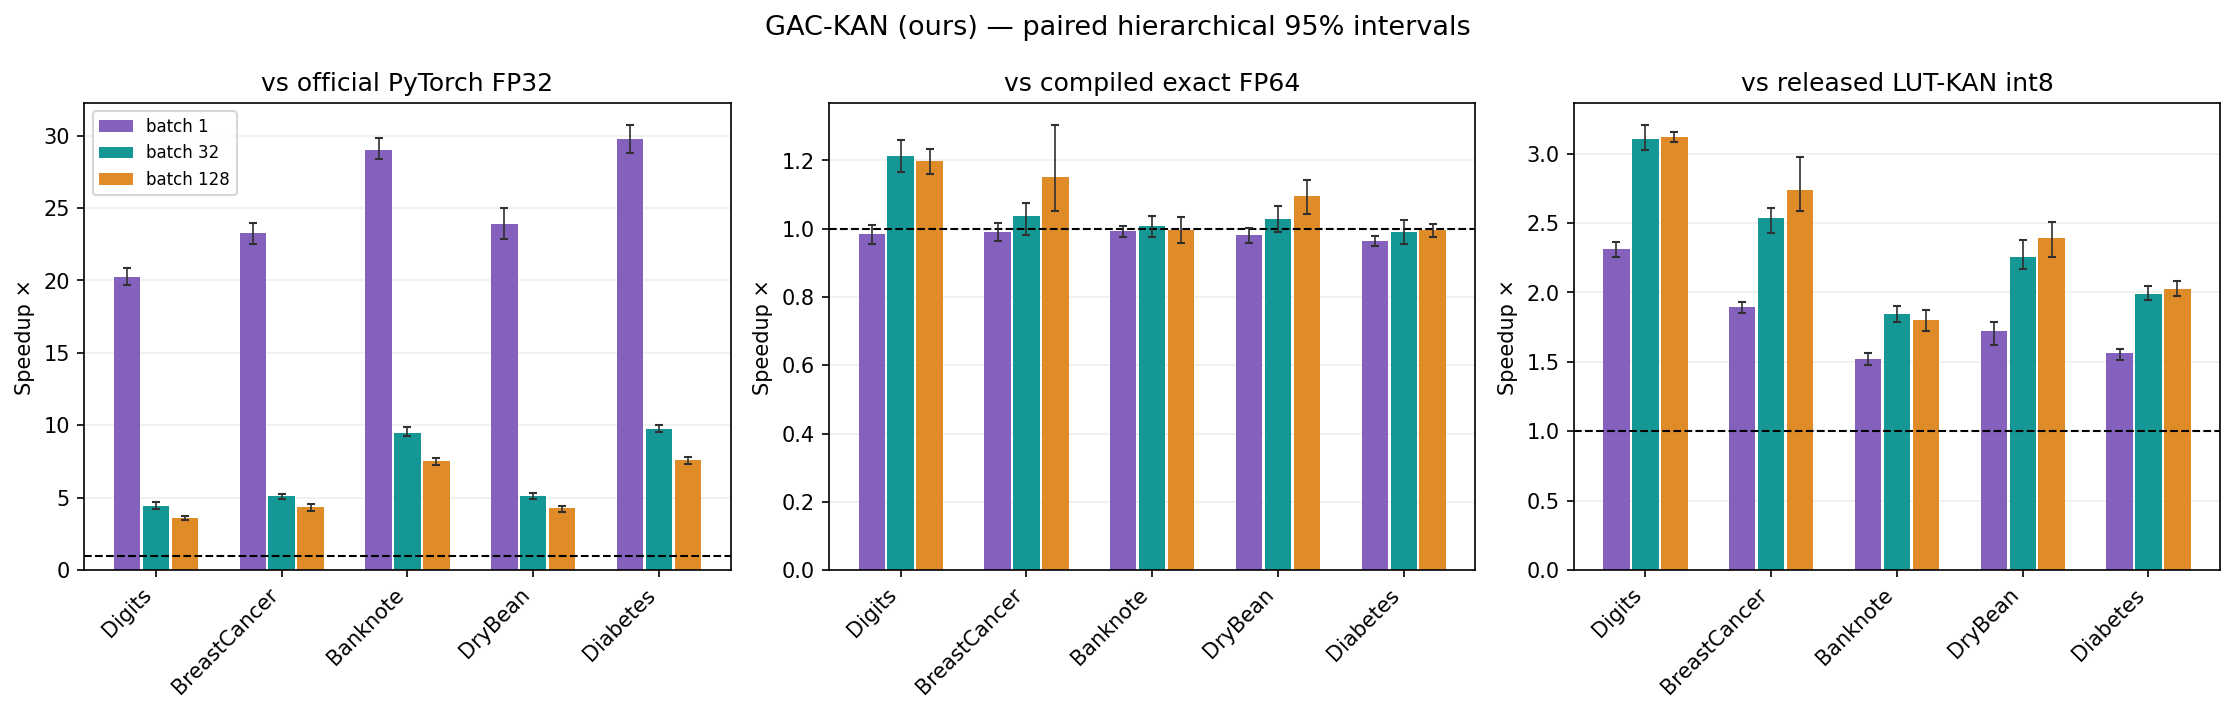

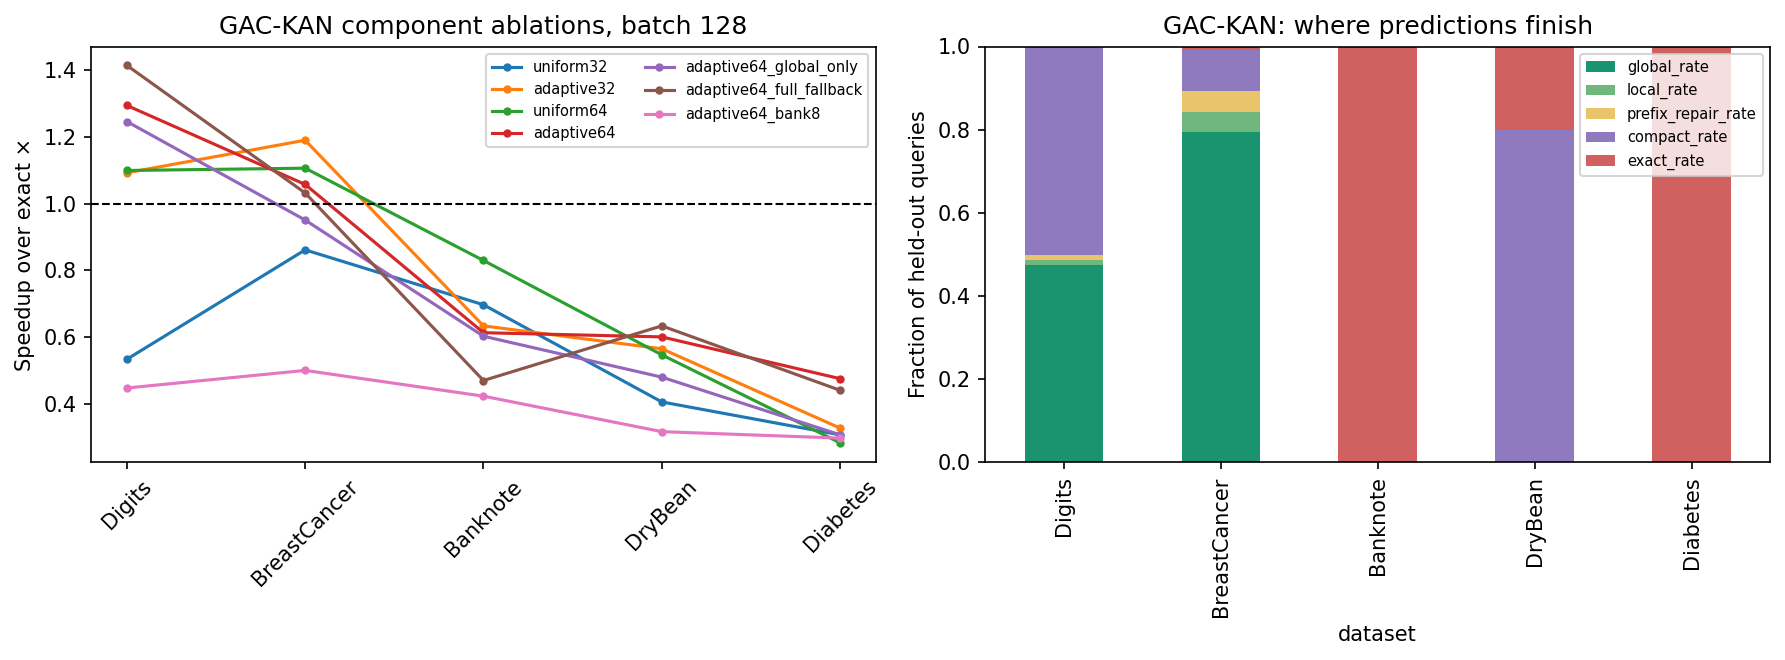

In [53]:
# Paired plots retain every dataset, including unfavorable outcomes.
fig,axes=plt.subplots(1,3,figsize=(15,4.8))
colors={1:'#8361bc',32:'#159895',128:'#df8b28'}
names=CLASS_NAMES+REG_NAMES
for axis,field,title in zip(axes,['speedup_torch32','speedup_exact','speedup_published'],
                           ['vs official PyTorch FP32','vs compiled exact FP64','vs released LUT-KAN int8']):
    for j,batch in enumerate((1,32,128)):
        f=SPEED_SUMMARY[SPEED_SUMMARY.batch==batch].set_index('dataset').loc[names]
        x=np.arange(len(names))+(j-1)*.23;y=f[field].to_numpy();low=f[field+'_low'].to_numpy();high=f[field+'_high'].to_numpy()
        axis.bar(x,y,width=.21,color=colors[batch],label=f'batch {batch}',zorder=2)
        axis.errorbar(x,y,yerr=np.maximum(0,np.vstack([y-low,high-y])),fmt='none',ecolor='#303030',capsize=2,lw=.8,zorder=3)
    axis.axhline(1,color='black',ls='--',lw=1);axis.set_xticks(np.arange(len(names)),names,rotation=45,ha='right')
    axis.set_ylabel('Speedup ×');axis.set_title(title);axis.grid(axis='y',alpha=.2,zorder=0)
axes[0].legend(fontsize=8);fig.suptitle('GAC-KAN (ours) — paired hierarchical 95% intervals',fontsize=13)
fig.tight_layout();display(fig);plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(12,4.5))
f=ABLATION_FRAME.query('batch==128').pivot_table(index='dataset',columns='variant',values='speedup_exact').reindex(names)
variants=['uniform32','adaptive32','uniform64','adaptive64','adaptive64_global_only','adaptive64_full_fallback','adaptive64_bank8']
for j,label in enumerate(variants):axes[0].plot(names,f[label],marker='o',ms=3,label=label)
axes[0].axhline(1,color='black',ls='--',lw=1);axes[0].set_ylabel('Speedup over exact ×');axes[0].set_title('GAC-KAN component ablations, batch 128')
axes[0].tick_params(axis='x',rotation=45);axes[0].legend(fontsize=7,ncol=2)
f=COMPILER_FRAME.query('method=="GAC-KAN (ours)" and batch==128').groupby('dataset')[['global_rate','local_rate','prefix_repair_rate','compact_rate','exact_rate']].mean().reindex(names)
f.plot.bar(stacked=True,ax=axes[1],color=['#1a936f','#70b77e','#e9c46a','#8f79bf','#d16060'])
axes[1].set_ylim(0,1);axes[1].set_ylabel('Fraction of held-out queries');axes[1].set_title('GAC-KAN: where predictions finish');axes[1].legend(fontsize=7)
fig.tight_layout();display(fig);plt.close(fig)

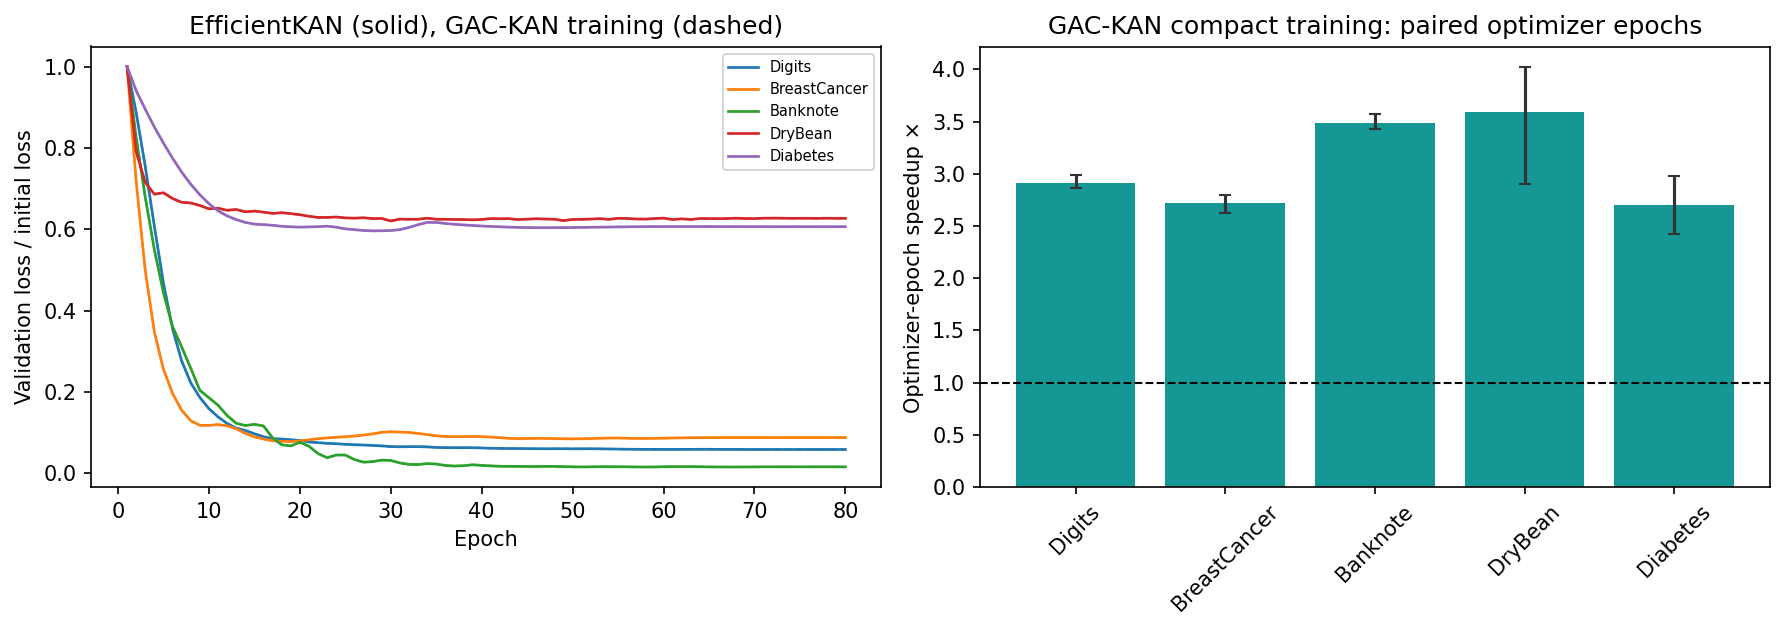

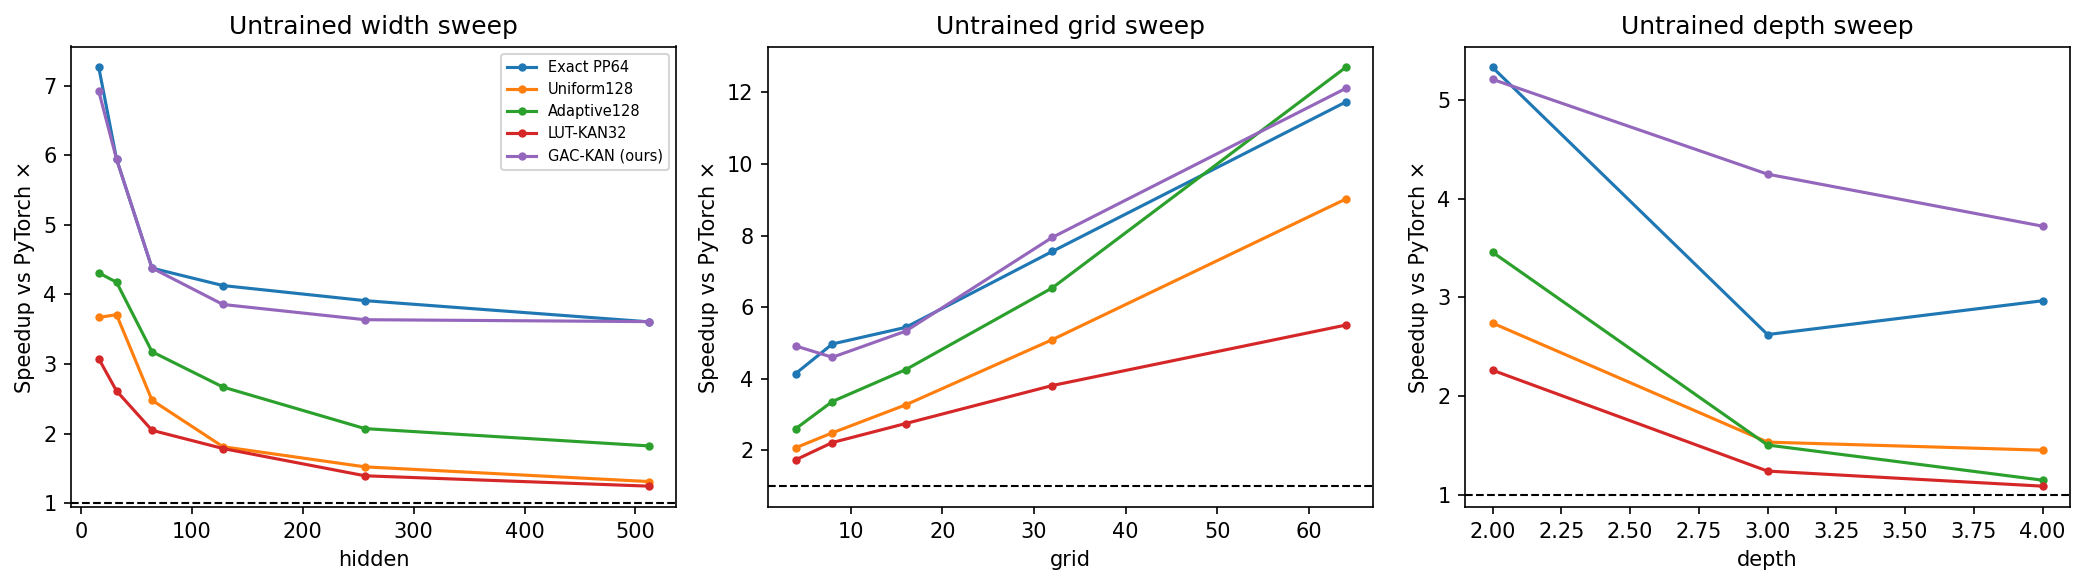

In [54]:
fig,axes=plt.subplots(1,2,figsize=(12,4.3))
for name in CLASS_NAMES+REG_NAMES:
    h=HISTORY[name,SPLITS[0],0,'EfficientKAN'];q=HISTORY[name,SPLITS[0],0,'GAC-KAN (compact training)']
    line,=axes[0].plot(h.epoch,h.val_loss/h.val_loss.iloc[0],label=name,lw=1.3)
    axes[0].plot(q.epoch,q.val_loss/q.val_loss.iloc[0],ls='--',lw=1,alpha=.7,color=line.get_color())
axes[0].set_xlabel('Epoch');axes[0].set_ylabel('Validation loss / initial loss');axes[0].set_title('EfficientKAN (solid), GAC-KAN training (dashed)');axes[0].legend(fontsize=7)
f=TRAINING_SUMMARY.set_index('dataset').loc[names];y=f.training_speedup.to_numpy()
axes[1].bar(names,y,color='#159895');axes[1].errorbar(np.arange(len(names)),y,
    yerr=np.maximum(0,np.vstack([y-f.ci95_low.to_numpy(),f.ci95_high.to_numpy()-y])),fmt='none',color='#333',capsize=3)
axes[1].axhline(1,color='black',ls='--',lw=1);axes[1].set_ylabel('Optimizer-epoch speedup ×');axes[1].set_title('GAC-KAN compact training: paired optimizer epochs');axes[1].tick_params(axis='x',rotation=45)
fig.tight_layout();display(fig);plt.close(fig)

fig,axes=plt.subplots(1,3,figsize=(14,4))
for axis,sweep,key in zip(axes,['width','grid','depth'],['hidden','grid','depth']):
    f=SCALING_FRAME.query('batch==128 and sweep==@sweep')
    for method in ['Exact PP64','Uniform128','Adaptive128','LUT-KAN32','GAC-KAN (ours)']:
        q=f[f.method==method];axis.plot(q[key],q.speedup_torch32,marker='o',ms=3,label=method)
    axis.axhline(1,color='black',ls='--',lw=1);axis.set_xlabel(key);axis.set_ylabel('Speedup vs PyTorch ×');axis.set_title('Untrained '+sweep+' sweep')
axes[0].legend(fontsize=7);fig.tight_layout();display(fig);plt.close(fig)

In [55]:
# Compact audit: no SOTA/novelty claim follows automatically from these experiments.
assert len(TRAIN_RESULTS)==250 and len(TUNING)==60
assert STRESS_FRAME.passed.all()
safe=COMPILER_FRAME[COMPILER_FRAME.method.isin(['GAC-KAN (ours)','Adaptive-64-Guarded','Adaptive-128-Guarded','Uniform-64-Guarded','Compact FP64'])]
assert safe.disagreements.dropna().eq(0).all()
assert safe.max_teacher_error.dropna().le(.0100001).all()
display(pd.DataFrame([dict(final_training_runs=len(TRAIN_RESULTS),hyperparameter_runs=len(TUNING),optimizer_epoch_fits=sum(len(t) for r in TRAIN_RESULTS if r['method']=='GAC-KAN (compact training)' for t in r['epoch_samples_s'].values()),
    datasets=len(CLASS_NAMES+REG_NAMES),splits=len(SPLITS),seeds=len(SEEDS),inference_rows=len(COMPILER_RESULTS),
    ablation_rows=len(COMPILER_ABLATIONS),stress_evaluations=int(STRESS_FRAME.samples.sum()),
    stress_failures=int((~STRESS_FRAME.passed).sum()),all_guarded_class_disagreements=int(safe.disagreements.fillna(0).sum()),
    GPU_tested=False,second_machine_tested=False,formal_FP_proof=False,universal_SOTA_proven=False)]))
display(pd.DataFrame([
    dict(method='EfficientKAN',status='unmodified official code; trained and benchmarked',url=SOURCE_MANIFEST['EfficientKAN']['url']),
    dict(method='FastKAN',status='unmodified official code; trained and benchmarked',url=SOURCE_MANIFEST['FastKAN']['url']),
    dict(method='LUT-KAN v2.2.0',status='unmodified official quantizer and Numba kernel; same teacher',url='https://github.com/KuznetsovKarazin/lut-kan/tree/'+LUT_COMMIT),
    dict(method='SHARe-KAN / LUTHAM',status='related work; GPU implementation not benchmarked here',url='https://arxiv.org/abs/2512.15742'),
    dict(method='FlashKAN / InKAN',status='related work; published GPU system not benchmarked here',url='https://arxiv.org/abs/2609.01956'),
    dict(method='MatrixKAN',status='existing polynomial evaluation approach; related work',url='https://arxiv.org/abs/2502.07176'),
    dict(method='DAREK',status='existing propagated spline error analysis; related work',url='https://arxiv.org/abs/2501.04757'),
    dict(method='PolyKAN GPU operators',status='related work; GPU implementation not benchmarked here',url='https://arxiv.org/abs/2511.14852')]))

display(pd.DataFrame(SETUP_RESULTS).groupby(['dataset','inductor_status']).size().rename('runs').to_frame())
# Raw measurements and learning curves stay inside this notebook.
from IPython.display import JSON
def json_safe(value):
    if isinstance(value,pd.DataFrame):return json_safe(value.to_dict(orient='records'))
    if isinstance(value,dict):return {str(k):json_safe(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)):return [json_safe(v) for v in value]
    if isinstance(value,np.ndarray):return json_safe(value.tolist())
    if isinstance(value,np.generic):return json_safe(value.item())
    if isinstance(value,float) and not math.isfinite(value):return None
    return value
# Regression tolerances use train-standardized targets; MSE uses original units squared.
PROTOCOL=dict(datasets=CLASS_NAMES+REG_NAMES,splits=SPLITS,seeds=SEEDS,
    full_fit_epochs=FINAL_EPOCHS,hyperparameter_epochs=TUNING_EPOCHS,CPU_threads=torch.get_num_threads(),
    regression_tolerance=.01,regression_tolerance_units='train-standardized targets',mse_units='original target squared',
    guard_reference='FP64 evaluation of official EfficientKAN weights',
    versions=dict(Python=platform.python_version(),PyTorch=torch.__version__,NumPy=np.__version__,
                  SciPy=scipy.__version__,Numba=__import__('numba').__version__),
    target_scalers=[dict(dataset=name,split=split,mean=d['target_mean'],scale=d['target_scale'])
                    for (name,split),d in DATA.items() if d['task']=='regression'],
    split_arrays_sha256={'/'.join(map(str,key)):hashlib.sha256(b''.join(
        a.tobytes() for part in ('train','val','cal','test') for a in d[part])).hexdigest() for key,d in DATA.items()})
RAW_RESULTS=json_safe(dict(protocol=PROTOCOL,numerical_encoding='Nonfinite values use JSON null',configuration_sha256=CONFIG_SHA256,
    compiler_search_sha256=COMPILER_SEARCH_SHA256,upstream=SOURCE_MANIFEST,
    tuning=TUNING,training=TRAIN_RESULTS,operator_training=TRAINING_KERNEL_RESULTS,inference=COMPILER_RESULTS,
    calibration=CALIBRATION_RESULTS,ablations=COMPILER_ABLATIONS,stress=STRESS_RESULTS,scaling=SCALING_RESULTS,
    setup=SETUP_RESULTS,real_arithmetic_checks=PROOF_CHECKS,
    learning_curves={'/'.join(map(str,key)):dict(columns=list(h.columns),values=h.to_numpy()) for key,h in HISTORY.items()}))
display(JSON(RAW_RESULTS,expanded=False))

,final_training_runs,hyperparameter_runs,optimizer_epoch_fits,datasets,splits,seeds,inference_rows,ablation_rows,stress_evaluations,stress_failures,all_guarded_class_disagreements,GPU_tested,second_machine_tested,formal_FP_proof,universal_SOTA_proven
0,250,60,750,5,2,5,2265,300,197430,0,0,False,False,False,False


,method,status,url
0,EfficientKAN,unmodified official code; trained and benchmarked,https://raw.githubusercontent.com/Blealtan/eff...
1,FastKAN,unmodified official code; trained and benchmarked,https://raw.githubusercontent.com/ZiyaoLi/fast...
2,LUT-KAN v2.2.0,unmodified official quantizer and Numba kernel...,https://github.com/KuznetsovKarazin/lut-kan/tr...
3,SHARe-KAN / LUTHAM,related work; GPU implementation not benchmark...,https://arxiv.org/abs/2512.15742
4,FlashKAN / InKAN,related work; published GPU system not benchma...,https://arxiv.org/abs/2609.01956
5,MatrixKAN,existing polynomial evaluation approach; relat...,https://arxiv.org/abs/2502.07176
6,DAREK,existing propagated spline error analysis; rel...,https://arxiv.org/abs/2501.04757
7,PolyKAN GPU operators,related work; GPU implementation not benchmark...,https://arxiv.org/abs/2511.14852


runs
dataset      inductor_status                                         
Banknote     executed                                               1
             not scheduled: representative-only Inductor con...     9
BreastCancer executed                                               1
             not scheduled: representative-only Inductor con...     9
Diabetes     executed                                               1
             not scheduled: representative-only Inductor con...     9
Digits       executed                                               1
             not scheduled: representative-only Inductor con...     9
DryBean      executed                                               1
             not scheduled: representative-only Inductor con...     9

<IPython.core.display.JSON object>